In [1]:
# Hops, Hooch, and Hidden Genes
import os, sys, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import Bio
from Bio import Entrez
Entrez.email = os.environ.get("NCBI_EMAIL", "anonymous@example.org")   # always tell NCBI who you are (lecture 09); set NCBI_EMAIL
os.makedirs("figures", exist_ok=True)
print("Biopython", Bio.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

Biopython 1.88 | pandas 3.1.1 | numpy 2.5.5


In [2]:
# Cache-first fetch for the published supplementary tables (data/raw/ is not in git). I look the file up in
# data/MANIFEST.csv, download it only if it is missing, and check its SHA-256 so a changed upstream file can't
# silently change our results.
import hashlib, io, time, zipfile, requests

def ensure_external(path):
    """Make sure a data/raw/external file exists (download from its MANIFEST URL if not) and matches its checksum."""
    man = pd.read_csv("data/MANIFEST.csv")
    row = man[man.local_path == path]
    assert len(row) == 1, f"{path} is not listed in data/MANIFEST.csv"
    url, sha = row.accession_or_url.iloc[0], row.sha256.iloc[0]
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        # Europe PMC sometimes answers 500/503, so I retry a few times with a growing wait before giving up
        for attempt in range(5):
            r = requests.get(url.split(" ")[0], timeout=300)
            if r.ok:
                break
            time.sleep(15 * (attempt + 1))
        r.raise_for_status()
        if "europepmc" in url:            # Europe PMC serves all supplementary files of a paper as one zip
            z = zipfile.ZipFile(io.BytesIO(r.content))
            data = z.read(next(n for n in z.namelist() if n.endswith(os.path.basename(path))))
        else:
            data = r.content
        open(path, "wb").write(data)
        print(f"downloaded {path}")
    digest = hashlib.sha256(open(path, "rb").read()).hexdigest()
    assert digest == sha, f"{path}: checksum differs from MANIFEST ({digest[:12]} vs {sha[:12]})"
    return path

In [3]:
# 1. Data acquisition: S288C reference genes and PAD1/FDC1 alleles
import os, io, time
import pandas as pd
from Bio import Entrez, SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord

Entrez.email = os.environ.get("NCBI_EMAIL", "anonymous@example.org")
Entrez.tool = "bch339n_project"
os.makedirs("data/reference", exist_ok=True); os.makedirs("data/blast", exist_ok=True); os.makedirs("data/seqs", exist_ok=True)

def efetch_region(acc, start, stop, strand=1):
    """FASTA text for acc:start-stop; strand=2 returns the reverse complement."""
    h = Entrez.efetch(db="nuccore", id=acc, rettype="fasta", retmode="text",
                      seq_start=start, seq_stop=stop, strand=strand)
    txt = h.read(); h.close(); time.sleep(0.34)  # NCBI limit: 3 requests/s
    return txt

In [4]:
# 1a. S288C reference CDS
# making a reference sequence dictionary to make sure that later NCBI querys are matches to the protein strains we want
# the genes we want to analyze
genes = pd.DataFrame([
    ("PAD1", "YDR538W", "NC_001136.10", 1510902, 1511630, "+"),
    ("FDC1", "YDR539W", "NC_001136.10", 1512094, 1513605, "+"),
    ("MAL11", "YGR289C", "NC_001139.9", 1073963, 1075813, "-"),
    ("MAL31", "YBR298C", "NC_001134.8", 802631, 804475, "-"),
    ("MPH2", "YDL247W", "NC_001136.10", 5985, 7814, "+"),
    ("MPH3", "YJR160C", "NC_001142.9", 738008, 739816, "-"),
], columns=["gene", "systematic", "chr_acc", "start", "stop", "strand"])
# then storing genes to a data file to save them, we don't have to query every time we run this notebook
genes.to_csv("data/reference/genes.csv", index=False)

# dictionary of sequences
ref = {}
for g in genes.itertuples():
    path = f"data/reference/{g.gene}_cds.fasta"
    # check if this file is not in data to save time
    if not os.path.exists(path):
        rec = SeqIO.read(io.StringIO(efetch_region(g.chr_acc, g.start, g.stop, 1 if g.strand == "+" else 2)), "fasta")
        open(path, "w").write(f">{g.gene}_S288C {rec.description}\n{rec.seq}\n")
    # add gene sequence to dictionary as {g.gene: seq}
    ref[g.gene] = SeqIO.read(path, "fasta").seq
    # for printing below, translate sequence to protein
    prot = ref[g.gene].translate()
    # check that the first three aa of the sequence should be ATG, the sequence should be a multiple of 3, the protein should end as '*' and not have any '*' within it
    assert ref[g.gene][:3] == "ATG" and len(ref[g.gene]) % 3 == 0 and prot[-1] == "*" and "*" not in prot[:-1], g.gene
    # print results nicely
    print(f"{g.gene:6s} {len(ref[g.gene]):5d} bp  {len(prot) - 1:4d} aa  OK")

PAD1     729 bp   242 aa  OK
FDC1    1512 bp   503 aa  OK
MAL11   1851 bp   616 aa  OK
MAL31   1845 bp   614 aa  OK
MPH2    1830 bp   609 aa  OK
MPH3    1809 bp   602 aa  OK


In [5]:
# 1b. BLAST PAD1 and FDC1 against core_nt (yeast only)
import requests
BLAST = "https://blast.ncbi.nlm.nih.gov/Blast.cgi"
COLS = ["qacc", "sacc", "pident", "length", "mismatch", "gapopen", "qstart", "qend", "sstart", "send", "evalue", "bitscore"]

def blast_tabular(name, seq, db="core_nt", entrez_query="txid4932[ORGN] OR txid27292[ORGN]"):
    put = requests.post(BLAST, data=dict(CMD="Put", PROGRAM="blastn", MEGABLAST="on", DATABASE=db,
                        QUERY=f">{name}\n{seq}", ENTREZ_QUERY=entrez_query, HITLIST_SIZE=500, EXPECT=1e-50,
                        EMAIL=Entrez.email, TOOL=Entrez.tool)).text
    rid = put.split("RID = ")[1].split()[0]
    while "Status=READY" not in requests.get(BLAST, params=dict(CMD="Get", FORMAT_OBJECT="SearchInfo", RID=rid)).text:
        time.sleep(10)
    txt = requests.get(BLAST, params=dict(CMD="Get", FORMAT_TYPE="Text", ALIGNMENT_VIEW="Tabular",
                       DESCRIPTIONS=500, ALIGNMENTS=500, RID=rid)).text
    rows = [l.split("\t")[:12] for l in txt.splitlines() if l.count("\t") >= 11 and not l.startswith("#")]
    return pd.DataFrame(rows, columns=COLS)

hits = {}
for gene in ["PAD1", "FDC1"]:
    path = f"data/blast/{gene}_core_nt.tsv"
    if not os.path.exists(path):
        blast_tabular(gene, ref[gene]).to_csv(path, sep="\t", index=False)
    hits[gene] = pd.read_csv(path, sep="\t")
    print(gene, len(hits[gene]), "hits;", "pident range", hits[gene].pident.min(), "-", hits[gene].pident.max())

PAD1 19 hits; pident range 98.765 - 100.0
FDC1 23 hits; pident range 99.537 - 100.0


In [6]:
# 1c. Beer, wine, sake, wild... genomes with known ecology (Gallone et al. 2016, Cell 166:1397)
from Bio import Align
aligner = Align.PairwiseAligner(mode="global", match_score=1, mismatch_score=-1, open_gap_score=-5, extend_gap_score=-1)

def best_match(S, k, start=0, max_mm=3):
    """Leftmost position in S (>= start) where k matches with the fewest mismatches (<= max_mm)."""
    best = (max_mm + 1, -1)
    for i in range(start, len(S) - len(k) + 1):
        mm = sum(a != b for a, b in zip(S[i:i + len(k)], k))
        if mm < best[0]:
            best = (mm, i)
            if mm == 0: break
    return best[1]

def locate_cds(S, cds):
    """Return (start, end) 0-based half-open of the CDS in S using start/stop 24-mer anchors, or None."""
    a = best_match(S, str(cds[:24]))
    if a < 0: return None
    b = best_match(S[a:a + len(cds) + 400], str(cds[-24:]), start=int(0.85 * len(cds)))
    return (a, a + b + 24) if b >= 0 else None

# self-check on a synthetic chromosome: flank + PAD1 with a 1-bp insertion + flank
_toy = "ACGT" * 50 + str(ref["PAD1"][:300]) + "A" + str(ref["PAD1"][300:]) + "TTGA" * 50
assert locate_cds(_toy, ref["PAD1"]) == (200, 200 + len(ref["PAD1"]) + 1)

if not all(os.path.exists(f"data/blast/{g}_gallone_chrIV.tsv") for g in ["PAD1", "FDC1"]):
    ids = Entrez.read(Entrez.esearch(db="nuccore", term='PRJNA323691[BioProject] AND "chromosome IV"[title]', retmax=500))["IdList"]
    chr4 = [(d["AccessionVersion"], int(d["Length"])) for d in Entrez.read(Entrez.esummary(db="nuccore", id=",".join(ids)))]
    rows = {"PAD1": [], "FDC1": []}
    for acc, L in chr4:
        st = max(1, L - 250000)
        S = str(SeqIO.read(io.StringIO(efetch_region(acc, st, L)), "fasta").seq).upper()
        for gene in rows:
            loc = locate_cds(S, ref[gene])
            if loc is None:
                print("not found:", acc, gene); continue
            c = aligner.align(ref[gene], S[loc[0]:loc[1]])[0].counts()
            n = c.identities + c.mismatches + c.gaps
            rows[gene].append([gene, acc, round(100 * c.identities / n, 3), n, c.mismatches, c.gaps,
                               1, len(ref[gene]), st + loc[0], st + loc[1] - 1, "NA", "NA"])
    for gene, rr in rows.items():
        pd.DataFrame(rr, columns=COLS).to_csv(f"data/blast/{gene}_gallone_chrIV.tsv", sep="\t", index=False)
for gene in hits:
    g2 = pd.read_csv(f"data/blast/{gene}_gallone_chrIV.tsv", sep="\t")
    print(gene, "Gallone chrIV alleles:", len(g2))
    hits[gene] = pd.concat([hits[gene], g2], ignore_index=True)

PAD1 Gallone chrIV alleles: 157
FDC1 Gallone chrIV alleles: 157


In [7]:
# 1d. Hit titles (Entrez esummary) and allele sequences (Entrez efetch)
# time to get the actual nt sequences
# check if we have it first
path = "data/blast/hit_titles.csv"
if not os.path.exists(path):
    # esummary first to see what hits we find from our hits dictionary
    accs = sorted(set(pd.concat(hits.values()).sacc))
    summ = Entrez.read(Entrez.esummary(db="nuccore", id=",".join(accs)))
    pd.DataFrame([(d["AccessionVersion"], d["Title"]) for d in summ], columns=["sacc", "title"]).to_csv(path, index=False)
titles = pd.read_csv(path).set_index("sacc").title

# now we can do the full efetch for each hit
for gene, df in hits.items():
    path = f"data/seqs/{gene}_alleles.fasta"
    if not os.path.exists(path):
        recs, seen = [SeqRecord(ref[gene], id="S288C_REF", description="S288C reference CDS")], {}
        for h in df.itertuples():
            lo, hi, minus = min(h.sstart, h.send), max(h.sstart, h.send), h.send < h.sstart
            seq = SeqIO.read(io.StringIO(efetch_region(h.sacc, lo, hi, 2 if minus else 1)), "fasta").seq
            seen[h.sacc] = seen.get(h.sacc, 0) + 1
            rid = h.sacc if seen[h.sacc] == 1 else f"{h.sacc}_{seen[h.sacc]}"
            # if less than 95% of sequence is present in hit, flag as partial, but keep it
            flag = (" PARTIAL" if (h.qend - h.qstart + 1) < 0.95 * len(ref[gene]) else "") + (" CONTAINS_N" if "N" in seq else "")
            recs.append(SeqRecord(seq, id=rid, description=f"{h.sstart}-{h.send} strand={'-' if minus else '+'}{flag} | {titles.get(h.sacc, '')}"))
        SeqIO.write(recs, path, "fasta")

In [8]:
# 1e. Sanity checks and PAD1/FDC1 pairing by strain
import re
# dictionary w FASTAs of pad1 and fdc1
alleles = {g: list(SeqIO.parse(f"data/seqs/{g}_alleles.fasta", "fasta")) for g in ["PAD1", "FDC1"]}
for g, recs in alleles.items():
    # match record id to length
    L = pd.Series({r.id: len(r.seq) for r in recs})
    # count how many records are x amount of nucleotides long
    print(f"{g}: {len(recs)} records; lengths {L.value_counts().to_dict()}")
    # not divisible by 3 (frameshift mutation candidate) and "partials" (premature stop candidate)
    print("   not %3:", list(L[L % 3 != 0].index), "| partial:", [r.id for r in recs if "PARTIAL" in r.description])

def strain_of(title):
    # find strain name by searching for "strain:" and finding the words up until chromosome or complete
    m = re.search(r"strain:? ([^,]+?)(?: chromosome.*|, complete.*)?$", title)
    if m: return m.group(1).strip()
    # if that fails, search for "cerevisiae", words that follow that until chromosome or genes
    m = re.search(r"cerevisiae (\S+) (?:chromosome|genes)", title)
    return m.group(1) if m else None

def strain_table(gene):
    # one row per strain; for RIB6002 (several alleles) keep all accessions joined by ';'
    # make table with one row per strain
    t = pd.DataFrame([(r.id, strain_of(r.description.split(" | ", 1)[-1])) for r in alleles[gene][1:]], columns=["sacc", "strain"])
    return t.dropna().groupby("strain").sacc.apply(";".join)

# make file with strain table including pad1 and fdc1, if it doesn't already exist
path = "data/seqs/paired_strains.csv"
if not os.path.exists(path):
    pd.concat([strain_table("PAD1").rename("pad1_sacc"), strain_table("FDC1").rename("fdc1_sacc")], axis=1, join="inner") \
      .rename_axis("strain").reset_index().to_csv(path, index=False)
paired = pd.read_csv(path)
paired

PAD1: 177 records; lengths {729: 175, 560: 1, 978: 1}
   not %3: ['AY693262.1'] | partial: ['AY693262.1']
FDC1: 181 records; lengths {1512: 107, 1513: 73, 1511: 1}
   not %3: ['AB368814.1', 'LC075323.1', 'AB368810.1', 'LC493900.1', 'LC075324.1', 'LC075325.1', 'CM005250.2', 'CM004898.2', 'CM007154.1', 'CM007106.1', 'CM007090.1', 'CM007074.1', 'CM007058.1', 'CM007042.1', 'CM007026.1', 'CM006994.1', 'CM006946.1', 'CM006930.1', 'CM006882.1', 'CM006802.1', 'CM006738.1', 'CM006722.1', 'CM006626.1', 'CM006610.1', 'CM006594.1', 'CM006578.1', 'CM006530.1', 'CM006514.1', 'CM006482.1', 'CM006466.1', 'CM006450.1', 'CM006434.1', 'CM006418.1', 'CM006402.1', 'CM006386.1', 'CM006370.1', 'CM006354.1', 'CM006338.1', 'CM006322.1', 'CM006306.1', 'CM006290.1', 'CM006274.1', 'CM006258.1', 'CM006226.1', 'CM006210.1', 'CM006162.1', 'CM006146.1', 'CM006130.1', 'CM006114.1', 'CM006098.1', 'CM006082.1', 'CM006066.1', 'CM006050.1', 'CM006018.1', 'CM005922.1', 'CM005874.1', 'CM005794.1', 'CM005762.1', 'CM005746.1'

,strain,pad1_sacc,fdc1_sacc
0,Bottom Fermentation Yeast NCYC984,AB368793.1,AB368814.1
1,N85,LN907787.1,LN907787.1
2,NCIM3107,CP009945.1,CP009945.1
3,RIB6002,LC075298.1;LC075299.1,LC075323.1;LC075324.1;LC075325.1
4,SY14,CP029160.1,CP029160.1
5,Sake Yeast Kyokai No. 6,AB368778.1,AB368799.1
6,Shochu Yeast Kyokai No. 2,AB368782.1,AB368803.1
7,Top Fermentation Yeast NCYC240,AB368789.1,AB368810.1
8,Wine Yeast EC1118,AB368787.1,AB368807.1
9,Wine Yeast K1-V1116,AB368797.1,AB368818.1


In [9]:
# 2. Maltose / maltotriose transporter copy number in complete genomes
import os, io, re, time
import pandas as pd

EMAIL, TOOL = os.environ.get('NCBI_EMAIL', 'anonymous@example.org'), 'bch339n_project'
# file names into the new cnv folder
CNV = 'data/cnv'
STRAINS_CSV = f'{CNV}/complete_genome_strains.csv'
HITS_TSV = f'{CNV}/mal_blast_hits.tsv'
COPY_CSV = f'{CNV}/mal_copy_number.csv'
QFASTA = f'{CNV}/mal_query_cds.fasta'
GENES = {  # S288C CDS: chromosome record, start, stop, strand (1 = +, 2 = -)
    'MAL11': ('NC_001139.9', 1073963, 1075813, 2),
    'MAL31': ('NC_001134.8', 802631, 804475, 2),
    'MPH2':  ('NC_001136.10', 5985, 7814, 1),
    'MPH3':  ('NC_001142.9', 738008, 739816, 2)}
os.makedirs(CNV, exist_ok=True)

In [10]:
# Query CDSs (Entrez efetch of the S288C coordinates) - cached
if not os.path.exists(QFASTA):
    from Bio import Entrez
    Entrez.email, Entrez.tool = EMAIL, TOOL
    with open(QFASTA, 'w') as out:
        for g, (acc, s, e, strand) in GENES.items():
            fa = Entrez.efetch(db='nuccore', id=acc, rettype='fasta', retmode='text',
                               seq_start=s, seq_stop=e, strand=strand).read()
            out.write(f'>{g}_S288C {acc}:{s}-{e}\n' + ''.join(fa.split('\n')[1:]).strip() + '\n')
            time.sleep(0.4)
from Bio import SeqIO
QUERIES = {r.id.split('_')[0]: str(r.seq) for r in SeqIO.parse(QFASTA, 'fasta')}
QLEN = {g: len(s) for g, s in QUERIES.items()}
print(QLEN)

{'MAL11': 1851, 'MAL31': 1845, 'MPH2': 1830, 'MPH3': 1809}


In [11]:
# Strain set: chromosome-level assemblies -> nuccore records (Entrez esearch / esummary / elink)
if not os.path.exists(STRAINS_CSV):
    from Bio import Entrez
    Entrez.email, Entrez.tool = EMAIL, TOOL
    term = ('(txid4932[orgn] OR txid27292[orgn]) AND ("complete genome"[filter] OR '
            '"chromosome level"[filter]) AND latest[filter]')
    ids = Entrez.read(Entrez.esearch(db='assembly', term=term, retmax=1000))['IdList']
    # shortcut: we hand-picked strains spanning niches from these summaries (contig N50 >= ~400 kb,
    # i.e. long-read assemblies); re-curate the list below if NCBI adds better ale assemblies.
    raise SystemExit(f'{len(ids)} assemblies found - curate {STRAINS_CSV} from their esummary/biosample records')
strains = pd.read_csv(STRAINS_CSV)
acc2strain = {a: row.strain for row in strains.itertuples() for a in row.nuccore_accessions.split(';')}
print(len(strains), 'assemblies;', strains.group.value_counts().to_dict())

36 assemblies; {'Wine': 10, 'Wild': 7, 'Other/Unknown': 6, 'Laboratory': 4, 'Clinical': 4, 'Lager': 2, 'Sake': 1, 'Bioethanol': 1, 'Ale': 1}


In [12]:
# BLAST each assembly (records packed into <= 9.5 Mb batches: the bl2seq subject limit is 10 Mb)
def blast2seq(query_fasta, subject_accs):
    import requests
    url = 'https://blast.ncbi.nlm.nih.gov/'
    put = requests.post(url + 'BlastAlign.cgi', data=dict(
        CMD='Put', PROGRAM='blastn', MEGABLAST='on', BLAST_SPEC='blast2seq', QUERY=query_fasta,
        SUBJECTS='\n'.join(subject_accs), EXPECT='1e-50', HITLIST_SIZE=500, EMAIL=EMAIL, TOOL=TOOL)).text
    rid = re.search(r'name="RID" value="(\w+)"', put).group(1)
    while True:
        time.sleep(15)
        info = requests.get(url + 'Blast.cgi', params=dict(CMD='Get', FORMAT_OBJECT='SearchInfo', RID=rid)).text
        if 'Status=READY' in info: break
        if 'Status=WAITING' not in info: raise RuntimeError(rid + ' failed')
    txt = requests.get(url + 'Blast.cgi', params=dict(CMD='Get', FORMAT_TYPE='Text', ALIGNMENT_VIEW='Tabular',
                                                      DESCRIPTIONS=5000, ALIGNMENTS=5000, RID=rid)).text
    return [l.split('\t') for l in txt.splitlines() if re.match(r'^\S+\t', l) and not l.startswith('#')]

if not os.path.exists(HITS_TSV):
    from Bio import Entrez
    Entrez.email, Entrez.tool = EMAIL, TOOL
    qfa = ''.join(f'>{g}\n{s}\n' for g, s in QUERIES.items())
    rows = []
    for row in strains.itertuples():
        accs = row.nuccore_accessions.split(';')
        summ = Entrez.read(Entrez.esummary(db='nuccore', id=','.join(accs)))
        size = {d['AccessionVersion']: int(d['Length']) for d in summ}
        title = {d['AccessionVersion']: d['Title'] for d in summ}
        batches = []
        for a in sorted(accs, key=size.get, reverse=True):          # first-fit packing
            b = next((b for b in batches if b[0] + size[a] <= 9.5e6), None)
            if b is None: b = [0, []]; batches.append(b)
            b[0] += size[a]; b[1].append(a)
        for _, batch in batches:
            for h in blast2seq(qfa, batch):
                rows.append(h[:12] + [title.get(h[1], '')])
            time.sleep(10)
    cols = 'gene sacc pident length mismatch gapopen qstart qend sstart send evalue bitscore title'.split()
    hits = pd.DataFrame(rows, columns=cols)
    for c in cols[2:12]: hits[c] = pd.to_numeric(hits[c])
    hits['qcov'] = (hits.qend - hits.qstart + 1) / hits.gene.map(QLEN)
    hits['strain'] = hits.sacc.map(acc2strain)
    hits[['gene', 'sacc', 'pident', 'length', 'qcov', 'sstart', 'send', 'qstart', 'qend', 'evalue',
          'bitscore', 'strain', 'title']].to_csv(HITS_TSV, sep='\t', index=False)
hits = pd.read_csv(HITS_TSV, sep='\t')
print(len(hits), 'HSPs (all, unfiltered)')

224 HSPs (all, unfiltered)


In [13]:
# Filter, then count copies: raw HSP counts and best-query assignment of merged loci
# filter and count best hits for genes of interest, 80% sequence identity and 70% of length
keep = hits[(hits.pident >= 80) & (hits.length >= 0.7 * hits.gene.map(QLEN))].copy()
# smallest chromosome coordinate is lo, larger coordinate is hi
keep['lo'] = keep[['sstart', 'send']].min(axis=1)
keep['hi'] = keep[['sstart', 'send']].max(axis=1)

# Score = bitscore / query length: raw bitscore favours the longer MPH2 query even at the MPH3 locus
# (MPH2 and MPH3 are 99.9% identical), so we normalise by the query's maximum possible length.
# normalize bitscores by dividing by gene total length
keep['score'] = keep.bitscore / keep.gene.map(QLEN)

def best_loci(df):
    """Greedy: best-scoring HSP first; an HSP overlapping an existing locus by >50% of the shorter joins it."""
    loci = []
    # sort hits by score
    for h in df.sort_values('score', ascending=False).itertuples():
        for L in loci:
            # if h overlaps any genes already saved in that chromosome, then don't save it
            if L['sacc'] == h.sacc and min(L['hi'], h.hi) - max(L['lo'], h.lo) > 0.5 * min(L['hi'] - L['lo'], h.hi - h.lo):
                break
        else:
            # otherwise, save it
            loci.append(dict(sacc=h.sacc, lo=h.lo, hi=h.hi, gene=h.gene, strain=h.strain))
    return pd.DataFrame(loci)

loci = best_loci(keep)
# MPH2/MPH3 differ at a handful of sites, so sequence cannot tell them apart outside S288C;
# name them by synteny instead: chr IV-left copy = MPH2, chr X-right copy = MPH3 (S288C positions).
title = keep.drop_duplicates('sacc').set_index('sacc').title
chrom = loci.sacc.map(title).str.extract(r'chromosome (?:S[ce])?(IV|X|4|10)\b', expand=False)
mph = loci.gene.isin(['MPH2', 'MPH3'])
loci.loc[mph & chrom.isin(['IV', '4']), 'gene'] = 'MPH2'
loci.loc[mph & chrom.isin(['X', '10']), 'gene'] = 'MPH3'
# count BLAST hits per gene of interest in total, then by loci to exclude duplicates
raw = keep.groupby(['strain', 'gene']).size().unstack(fill_value=0)
best = loci.groupby(['strain', 'gene']).size().unstack(fill_value=0)
genes = list(GENES)
# strains df from earlier being edited
cn = (strains[['strain', 'assembly_accession', 'group', 'species', 'source_niche']]
      .rename(columns={'assembly_accession': 'assembly_or_record_set'}).set_index('strain'))
# filling new cn df with raw hits and best hits by strain
for g in genes:
    cn[g] = best.get(g, pd.Series(dtype=int)).reindex(cn.index).fillna(0).astype(int)   # best = main count
    cn[g + '_raw'] = raw.get(g, pd.Series(dtype=int)).reindex(cn.index).fillna(0).astype(int)
# MPH2 vs MPH3 difference is near-arbitrary, especially when genes duplicate and jump
# better to have a total count of copies of the gene
cn['MPH2_3'] = cn.MPH2 + cn.MPH3
# sum all genes to measure overall MAL transporter capacity between strains
cn['total_loci'] = cn[genes].sum(axis=1)
cn.reset_index().to_csv(COPY_CSV, index=False)

# self-checks: S288C reference has exactly one locus of each gene; best <= raw everywhere
assert cn.loc['S288C', genes].tolist() == [1, 1, 1, 1], cn.loc['S288C', genes]
assert all((cn[g] <= cn[g + '_raw']).all() for g in genes)
# print for each gene of interest, raw and best, sort by group
cn[genes + [g + '_raw' for g in genes] + ['group']].sort_values('group')

,MAL11,MAL31,MPH2,MPH3,MAL11_raw,MAL31_raw,MPH2_raw,MPH3_raw,group
strain,,,,,,,,,
Jean-Talon,1,1,0,0,1,1,0,0,Ale
GLBRCY22-3,1,2,1,0,1,2,1,1,Bioethanol
273614N,1,4,1,0,1,4,1,1,Clinical
YJM981,0,2,1,0,0,2,1,1,Clinical
YJM975,0,2,1,0,0,2,1,1,Clinical
YJM978,0,1,0,0,0,1,0,0,Clinical
S288C,1,1,1,1,1,1,2,2,Laboratory
CEN.PK113-7D,1,2,1,1,1,2,2,2,Laboratory
SK1,0,2,1,0,0,2,1,1,Laboratory


In [14]:
# 3. Variant calling in PAD1 and FDC1 alleles
import os, re
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.Align import PairwiseAligner, substitution_matrices
from Bio.Data.CodonTable import standard_dna_table

DATA = os.environ.get('VC_DATA', 'data')      # VC_* env vars only used by tests/test_variants.py
FIG = os.environ.get('VC_FIG', 'figures')
RES = f'{DATA}/results'
for d in (RES, FIG):
    os.makedirs(d, exist_ok=True)
VC_GENES = ['PAD1', 'FDC1']
GROUP_ORDER = ['Laboratory', 'Wild', 'Wine', 'Clinical', 'Bioethanol', 'Baking', 'Wheat/Hefeweizen',
               'Beer (Gallone)', 'Ale', 'Lager', 'Sake', 'Shochu/Awamori', 'Spirits', 'Other/Unknown']
ref_cds = {g: str(next(SeqIO.parse(f'{DATA}/reference/{g}_cds.fasta', 'fasta')).seq).upper() for g in VC_GENES}
ref_prot = {g: str(Seq(s).translate(to_stop=True)) for g, s in ref_cds.items()}
alleles = {g: [r for r in SeqIO.parse(f'{DATA}/seqs/{g}_alleles.fasta', 'fasta')
               if not r.id.startswith('S288C_REF')] for g in VC_GENES}
for g in VC_GENES:
    print(f'{g}: reference {len(ref_cds[g])} nt / {len(ref_prot[g])} aa; {len(alleles[g])} alleles')

PAD1: reference 729 nt / 242 aa; 176 alleles
FDC1: reference 1512 nt / 503 aa; 180 alleles


In [15]:
# 3.1 Strain metadata
lookup = pd.read_csv(f'{DATA}/metadata/strain_lookup.csv')

def norm_strain(s):
    s = re.sub(r'\bno\b\.?', '', str(s).lower())
    s = re.sub(r'[\s\-_.:/\'’,()]', '', s)
    # DDBJ (Mukai) titles prefix the niche: 'Wine Yeast Kyokai No. 1', 'Top Fermentation Yeast NCYC240'
    s = s.replace('wineyeastkyokai', 'kyokaiwineyeast').replace('shochuyeastkyokai', 'shochukyokai')
    s = re.sub(r'^(?:top|bottom)fermentationyeast|^(?:sake|shochu|wine)yeast', '', s)
    return s.replace('kagishima', 'kagoshima')  # GenBank typo, see strain_lookup notes

lookup_by_norm = {norm_strain(s): s for s in lookup.strain}
STOPWORDS = r'(?:chromosome|genomic|DNA|PAD1|FDC1|YDR53[89]W|gene|genes|complete|mitochondri\w*|partial|cds|sequence|strain|isolate|clone|contig|scaffold)'

def parse_strain(title, sacc):
    t = re.sub(r'^\S+\s+', '', title) if re.match(r'^[A-Z]{1,2}_?\d+\.\d\s', title) else title
    for pat in [r'strain[:\s]+', r'isolate[:\s]+', r'Saccharomyces (?:cerevisiae|pastorianus|carlsbergensis)\s+(?:x\s+\S+\s+)?']:
        m = re.search(pat + r'(.+?)(?=\s+' + STOPWORDS + r'\b|[,;]|$)', t, flags=re.I)
        name = m.group(1).strip() if m else ''
        if name and (pat.startswith(('strain', 'isolate')) or (len(name.split()) <= 2 and re.search(r'\d', name))):
            return name  # bare 'S. cerevisiae X ...' only counts if X looks like a strain code (N85, Y7)
    return None

def match_strain(name):
    if name is None:
        return None
    n = norm_strain(name)
    if n in lookup_by_norm:
        return lookup_by_norm[n]
    hits = [k for k in lookup_by_norm if len(k) >= 4 and (k in n or n in k)]  # e.g. 'NCYC 240 haploid'
    return lookup_by_norm[max(hits, key=len)] if hits else None

titles = {}
for g in VC_GENES:
    for r in alleles[g]:
        titles[r.id] = r.description.split('|', 1)[1].strip() if '|' in r.description else r.description
GALLONE = {'beer': 'Beer (Gallone)', 'wine': 'Wine', 'sake': 'Sake', 'spirits': 'Spirits', 'wild': 'Wild',
           'bioethanol': 'Bioethanol', 'bread': 'Baking', 'laboratory': 'Laboratory'}
GALLONE_CIT = 'Gallone et al. 2016 Cell PMID:27610566 (BioProject PRJNA323691)'
S288C_RECORDS = {'U43834.1'}  # yeast genome project chromosome IV clone (S288C); NM_/NC_ = RefSeq S288C
rows = []
for sacc, title in titles.items():
    base = re.sub(r'(\.\d+)_\d+$', r'\1', sacc)
    raw = parse_strain(title, base)
    gm = re.fullmatch(r'([a-z]+)\d{3}', raw or '')
    hit = None if gm else match_strain(raw)
    if gm and gm.group(1) in GALLONE:
        rows.append(dict(sacc=sacc, strain=raw, species='S. cerevisiae', group=GALLONE[gm.group(1)],
                         source_niche=f'{gm.group(1)} (Gallone 2016 niche label)', citation=GALLONE_CIT, notes='',
                         dataset='Gallone2016', parsed_name=raw, title=title))
    elif base.startswith(('NM_', 'NC_')) or base in S288C_RECORDS:
        L = lookup[lookup.strain == 'S288C'].iloc[0]
        rows.append(dict(sacc=sacc, strain=f'S288C ({sacc})', species=L.species, group='Laboratory',
                         source_niche=L.source_niche, citation=L.citation, notes='S288C-derived reference record',
                         parsed_name=raw, title=title))
    elif hit:
        L = lookup[lookup.strain == hit].iloc[0]
        rows.append(dict(sacc=sacc, strain=hit, species=L.species, group=L.group, source_niche=L.source_niche,
                         citation=L.citation, notes=L.notes, parsed_name=raw, title=title))
    else:
        sp = 'S. pastorianus' if re.search(r'pastorianus|carlsbergensis', title, re.I) else 'S. cerevisiae'
        rows.append(dict(sacc=sacc, strain=raw or f'unnamed ({sacc})', species=sp, group='Other/Unknown', source_niche='',
                         citation='', notes='strain not in lookup table', parsed_name=raw, title=title))
strains = pd.DataFrame(rows)
strains['dataset'] = strains.reindex(columns=['dataset'])['dataset'].fillna('NCBI_core_nt')
strains.drop(columns=['parsed_name', 'title']).to_csv(f'{DATA}/metadata/strains.csv', index=False)
pd.set_option('display.width', 200, 'display.max_colwidth', 60)
print(pd.crosstab(strains.group, strains.dataset, margins=True).to_string())
print('\nNCBI core_nt records:')
print(strains[strains.dataset == 'NCBI_core_nt'][['sacc', 'strain', 'species', 'group']].to_string(index=False))

dataset           Gallone2016  NCBI_core_nt  All
group                                           
Ale                         0             2    2
Baking                      4             0    4
Beer (Gallone)            102             0  102
Bioethanol                  5             1    6
Laboratory                  2             4    6
Lager                       0             2    2
Other/Unknown               0            11   11
Sake                        7             2    9
Shochu/Awamori              0             4    4
Spirits                    11             0   11
Wheat/Hefeweizen            0             1    1
Wild                        7             0    7
Wine                       19             9   28
All                       157            36  193

NCBI core_nt records:
          sacc                 strain        species            group
    CP029160.1                   SY14  S. cerevisiae       Laboratory
NM_001180846.3 S288C (NM_001180846.3)  S. cerevisiae 

In [16]:
# 3.2 Pairwise alignment and variant calling
nt_aligner = PairwiseAligner(mode='global', match_score=2, mismatch_score=-3,
                             open_gap_score=-10, extend_gap_score=-1)
nt_aligner.target_end_gap_score = nt_aligner.query_end_gap_score = 0.0
prot_aligner = PairwiseAligner(mode='global', substitution_matrix=substitution_matrices.load('BLOSUM62'),
                               open_gap_score=-11, extend_gap_score=-1)
CODON = dict(standard_dna_table.forward_table, **{c: '*' for c in standard_dna_table.stop_codons})

def aa_of(codon):
    return CODON.get(codon, 'X')

def right_shift_ins(ref, p, ins):
    """Insertion of `ins` after 1-based ref position p -> 3'-most equivalent position (HGVS)."""
    while p < len(ref) and ref[p] == ins[0]:
        ins, p = ins[1:] + ins[0], p + 1
    return p, ins

def right_shift_del(ref, a, b):
    """Deletion of ref[a:b] (0-based) -> 3'-most equivalent."""
    while b < len(ref) and ref[b] == ref[a]:
        a, b = a + 1, b + 1
    return a, b

def call_allele(gene, rec):
    ref, alt = ref_cds[gene], str(rec.seq).upper()
    aln = nt_aligner.align(ref, alt)[0]
    R, A = aln[0], aln[1]
    both = [i for i in range(len(R)) if R[i] != '-' and A[i] != '-']
    i0, i1 = both[0], both[-1]
    rpos, apos = i0 - R[:i0].count('-'), i0 - A[:i0].count('-')
    r_start, a_start = rpos, apos            # 0-based first covered ref / allele positions
    variants, snv_alt, ident, i = [], {}, 0, i0
    while i <= i1:
        if R[i] != '-' and A[i] != '-':
            if R[i] == A[i]:
                ident += 1
            elif A[i] in 'ACGT':
                snv_alt[rpos] = A[i]
            else:
                variants.append(dict(cds_pos=rpos + 1, ref=R[i], alt=A[i], type='ambiguous', effect='unknown',
                                     protein_change='', hgvs_c=f'c.{rpos + 1}{R[i]}>{A[i]}'))
            rpos, apos, i = rpos + 1, apos + 1, i + 1
        else:
            j = i
            while j <= i1 and (R[j] == '-') == (R[i] == '-') and (R[j] == '-' or A[j] == '-'):
                j += 1
            if R[i] == '-':                                  # insertion after ref position rpos (1-based)
                p, ins = right_shift_ins(ref, rpos, A[i:j])
                n = len(ins)
                if ref[p - n:p] == ins:
                    kind, h = 'duplication', (f'c.{p}dup{ins}' if n == 1 else f'c.{p - n + 1}_{p}dup{ins}')
                    pos = p - n + 1
                else:
                    kind, h, pos = 'insertion', f'c.{p}_{p + 1}ins{ins}', p
                codon = p // 3 + 1 if kind == 'insertion' else (p - n) // 3 + 1
                variants.append(dict(cds_pos=pos, ref='-', alt=ins, type=kind, indel_len=n, hgvs_c=h, codon=codon))
                apos += j - i
            else:                                            # deletion of ref[rpos:rpos+len]
                a, b = right_shift_del(ref, rpos, rpos + (j - i))
                h = f'c.{a + 1}del{ref[a:b]}' if b - a == 1 else f'c.{a + 1}_{b}del{ref[a:b]}'
                variants.append(dict(cds_pos=a + 1, ref=ref[a:b], alt='-', type='deletion', indel_len=-(b - a),
                                     hgvs_c=h, codon=a // 3 + 1))
                rpos += j - i
            i = j
    r_end = rpos                                                  # 0-based exclusive
    for p, b in snv_alt.items():                                  # SNV effect with all SNVs of that codon applied
        c0 = p - p % 3
        rc = ref[c0:c0 + 3]
        mc = ''.join(snv_alt.get(c0 + k, rc[k]) for k in range(3))
        ra, ma, cn = aa_of(rc), aa_of(mc), c0 // 3 + 1
        if c0 == 0 and rc == 'ATG' and mc != 'ATG':
            eff = 'start_lost'
        elif ra == ma:
            eff = 'synonymous'
        elif ma == '*':
            eff = 'nonsense'
        elif ra == '*':
            eff = 'stop_lost'
        else:
            eff = 'missense'
        variants.append(dict(cds_pos=p + 1, ref=ref[p], alt=b, type='SNV', effect=eff,
                             protein_change='' if eff == 'synonymous' else f'p.{ra}{cn}{ma}',
                             hgvs_c=f'c.{p + 1}{ref[p]}>{b}'))
    net = sum(v.get('indel_len', 0) for v in variants)
    frameshift = net % 3 != 0
    for v in variants:
        if 'indel_len' in v:
            fs = v['indel_len'] % 3 != 0
            v['effect'] = 'frameshift' if fs else ('inframe_' + ('insertion' if v['indel_len'] > 0 else 'deletion'))
            raa = ref_prot[gene][v['codon'] - 1] if v['codon'] <= len(ref_prot[gene]) else '*'
            v['protein_change'] = f"p.{raa}{v['codon']}{'fs' if fs else ('ins' if v['indel_len'] > 0 else 'del')}"
    # translate allele in the reference frame, starting at the first full codon it covers
    k = (-r_start) % 3
    s = alt[a_start + k:]
    s = s[:len(s) // 3 * 3]
    aa_offset = (r_start + k) // 3
    prot = str(Seq(s).translate()) if s else ''
    stop = prot.find('*')
    has_stop = stop >= 0
    protein = prot[:stop] if has_stop else prot
    protein_len = aa_offset + len(protein)
    reflen = len(ref_prot[gene])
    premature = has_stop and protein_len < 0.95 * reflen
    lof = bool(premature or frameshift)
    lof_allele = ''
    if lof:
        causal = sorted([v for v in variants if v['effect'] in ('frameshift', 'nonsense')], key=lambda v: v['cds_pos'])
        what = '; '.join(f"{v['hgvs_c']} {v['protein_change']}" for v in causal) or 'premature stop'
        lof_allele = f"{what} -> {protein_len} aa" + ('' if has_stop else ' (no stop within record)')
    pa = prot_aligner.align(ref_prot[gene], protein)[0] if protein else None
    prot_id = (sum(x == y for x, y in zip(pa[0], pa[1]) if x != '-' and y != '-') / len(protein) * 100) if pa else np.nan
    for v in variants:
        v.pop('codon', None)
    flags = ' '.join(f for f in ('PARTIAL', 'CONTAINS_N') if f in rec.description.split('|')[0])
    callable_ = not flags  # partial or N-containing records cannot support an 'intact' or 'LOF' call
    summary = dict(length_nt=len(alt), ref_covered=f'{r_start + 1}-{r_end}', pct_identity=round(100 * ident / (i1 - i0 + 1), 3),
                   n_snv=sum(v['type'] == 'SNV' for v in variants),
                   n_missense=sum(v['effect'] == 'missense' for v in variants),
                   n_synonymous=sum(v['effect'] == 'synonymous' for v in variants),
                   n_nonsense=sum(v['effect'] == 'nonsense' for v in variants),
                   n_indel=sum('indel_len' in v for v in variants), frameshift=frameshift,
                   protein_len=protein_len, stop_found=has_stop, protein_pct_identity=round(prot_id, 2),
                   flags=flags, callable=callable_)
    summary.update(LOF=lof if callable_ else np.nan, LOF_allele=lof_allele if callable_ else '',
                   LOF_call=('LOF' if lof else 'intact') if callable_ else 'not callable')
    return variants, summary, protein, aln

meta = strains.set_index('sacc')
var_rows, sum_rows, ALN = [], [], {}
for g in VC_GENES:
    prot_recs = []
    for rec in alleles[g]:
        vs, sm, protein, aln = call_allele(g, rec)
        ALN[(g, rec.id)] = aln
        st, gr = meta.loc[rec.id, 'strain'], meta.loc[rec.id, 'group']
        for v in vs:
            v.pop('indel_len', None)
            var_rows.append(dict(gene=g, sacc=rec.id, strain=st, group=gr, **v))
        sum_rows.append(dict(gene=g, sacc=rec.id, strain=st, group=gr, **sm))
        prot_recs.append(f'>{rec.id} {st} | {gr} | {sm["protein_len"]} aa | {sm["LOF_call"]}\n{protein}\n')
    with open(f'{RES}/protein_alleles_{g}.fasta', 'w') as fh:
        fh.write(f'>S288C_REF {g} {len(ref_prot[g])} aa\n{ref_prot[g]}\n' + ''.join(prot_recs))
variant_calls = pd.DataFrame(var_rows, columns=['gene', 'sacc', 'strain', 'group', 'cds_pos', 'ref', 'alt', 'type',
                                                'effect', 'protein_change', 'hgvs_c']).sort_values(['gene', 'sacc', 'cds_pos'])
allele_summary = pd.DataFrame(sum_rows)
variant_calls.to_csv(f'{RES}/variant_calls.csv', index=False)
KNOWN_LOF = {('FDC1', 'c.160A>T'): 'carries sake-type K54*', ('FDC1', 'c.460C>T'): 'carries Beer 1 ale-type Q154*',
             ('FDC1', 'c.501dupA'): 'carries ale/lager FDC1 c.501dupA frameshift', ('PAD1', 'c.305G>A'): 'carries ale-type PAD1 W102*'}
for (g, h), note in KNOWN_LOF.items():
    carriers = set(variant_calls[(variant_calls.gene == g) & (variant_calls.hgvs_c == h)].sacc)
    m = strains.sacc.isin(carriers) & (strains.group == 'Other/Unknown')
    strains.loc[m, 'notes'] = strains.loc[m, 'notes'].fillna('').str.cat([note] * m.sum(), sep='; ').str.strip('; ')
for r in allele_summary[allele_summary.pct_identity < 95].itertuples():  # e.g. introgressed alleles
    strains.loc[strains.sacc == r.sacc, 'notes'] = (strains.loc[strains.sacc == r.sacc, 'notes'].fillna('') +
                                                    f'; divergent {r.gene} allele ({r.pct_identity:.1f}% nt identity to S288C) - possible introgression').str.strip('; ')
strains.drop(columns=['parsed_name', 'title']).to_csv(f'{DATA}/metadata/strains.csv', index=False)
allele_summary.to_csv(f'{RES}/allele_summary.csv', index=False)
print(allele_summary.groupby(['gene', 'LOF_call']).size().unstack(fill_value=0).to_string())
print('\nNot callable:', allele_summary[~allele_summary.callable][['gene', 'sacc', 'strain', 'flags']].to_string(index=False))
print('\nDivergent alleles (<95 % nt identity):')
print(allele_summary[allele_summary.pct_identity < 95][['gene', 'sacc', 'strain', 'group', 'pct_identity', 'LOF_call']].to_string(index=False))

LOF_call  LOF  intact  not callable
gene                               
FDC1       88      92             0
PAD1       57     117             2

Not callable: gene       sacc               strain      flags
PAD1 AY693262.1 unnamed (AY693262.1)    PARTIAL
PAD1 CM005458.1        bioethanol005 CONTAINS_N

Divergent alleles (<95 % nt identity):
gene       sacc        strain      group  pct_identity     LOF_call
PAD1 CM005522.1 bioethanol002 Bioethanol        89.712       intact
PAD1 CM005458.1 bioethanol005 Bioethanol        73.517 not callable
FDC1 CM005522.1 bioethanol002 Bioethanol        90.278       intact


In [17]:
# Variant counts by effect (full list in data/results/variant_calls.csv)
print(variant_calls.groupby(['gene', 'effect']).size().unstack(fill_value=0).to_string())

effect  frameshift  inframe_insertion  missense  nonsense  synonymous  unknown
gene                                                                          
FDC1            74                  0       197        75         519        1
PAD1             0                  1       481        57         672        0


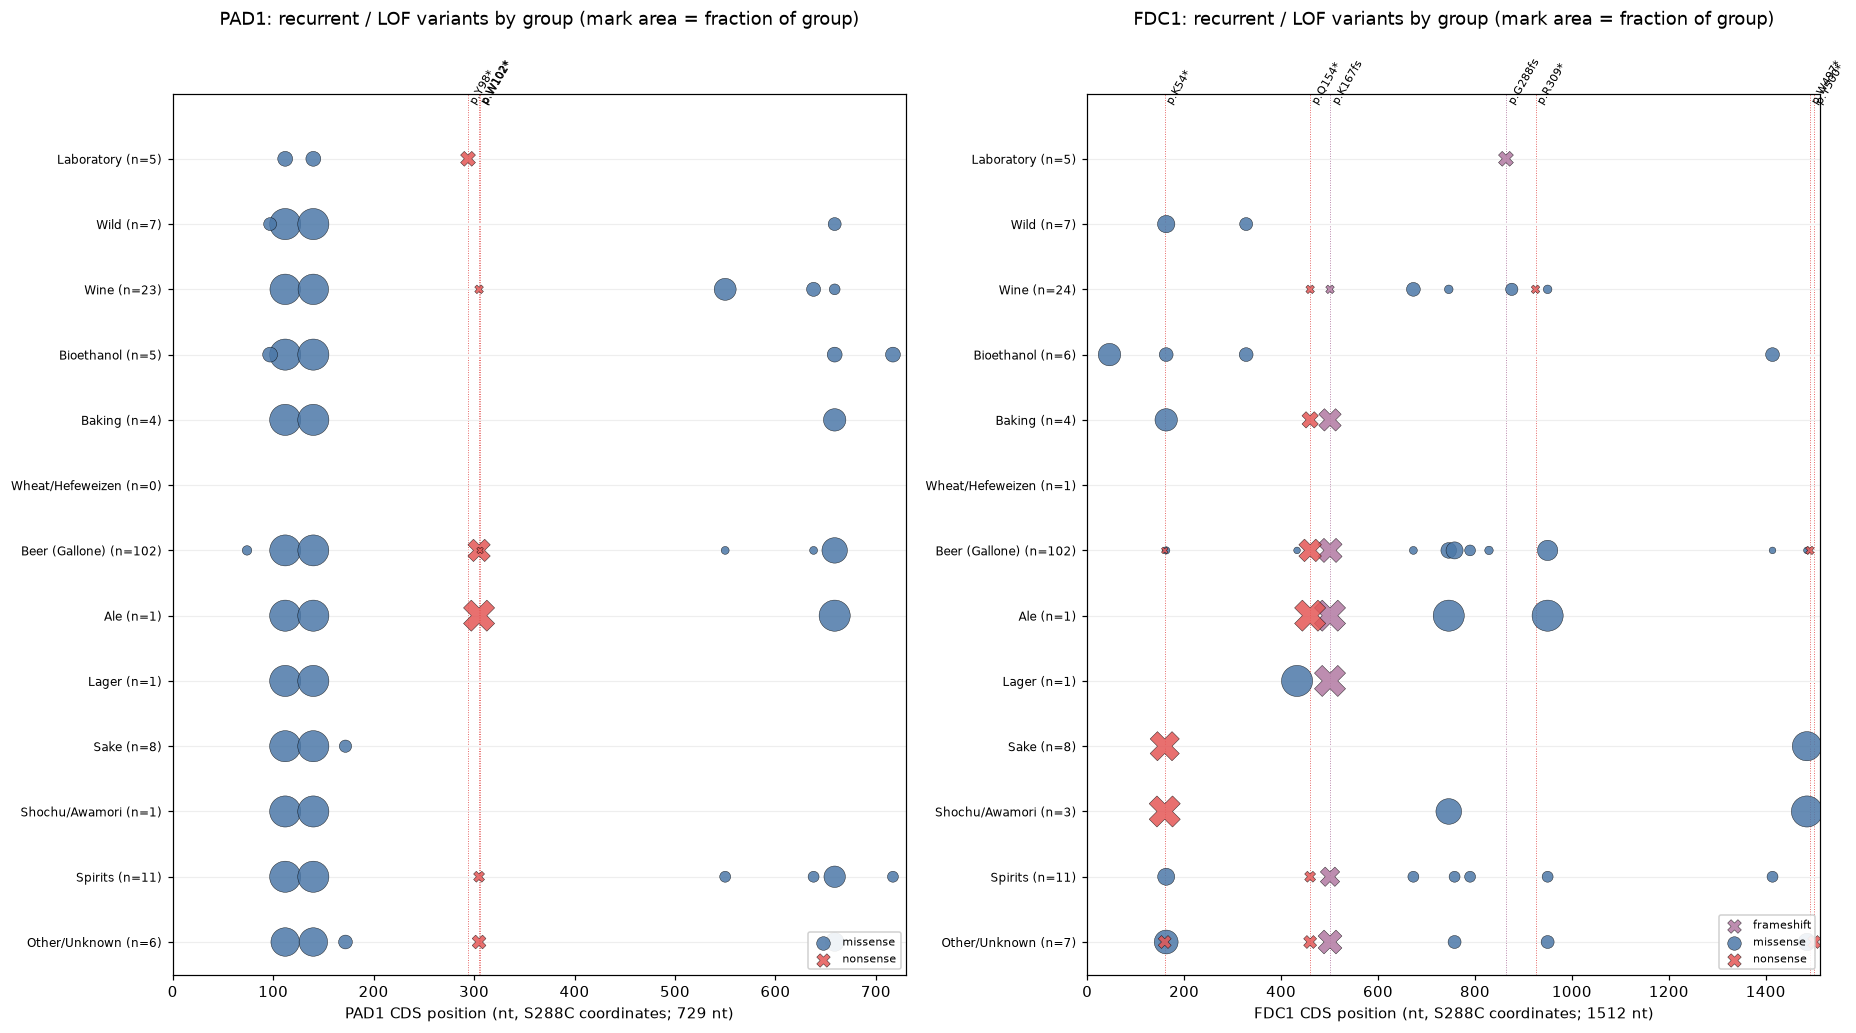

In [18]:
# 3.3 Variant tracks along each CDS, aggregated by group
EFFECT_COL = {'synonymous': '#b0b0b0', 'missense': '#4c78a8', 'inframe_insertion': '#72b7b2',
              'inframe_deletion': '#72b7b2', 'nonsense': '#e45756', 'frameshift': '#b279a2',
              'start_lost': '#f58518', 'stop_lost': '#f58518', 'unknown': '#eeca3b'}
LOFEFF = ['nonsense', 'frameshift']
AS_c = allele_summary[allele_summary.callable]
VC = variant_calls[variant_calls.sacc.isin(AS_c.sacc)].merge(AS_c[['gene', 'sacc']], on=['gene', 'sacc'])
grp_order = [g for g in GROUP_ORDER if g in set(allele_summary.group)]
n_grp = AS_c.groupby(['gene', 'group']).size()
freq = VC.groupby(['gene', 'group', 'hgvs_c', 'cds_pos', 'effect', 'protein_change']).sacc.nunique().rename('n').reset_index()
freq['frac'] = freq.n / [n_grp[(g, gr)] for g, gr in zip(freq.gene, freq.group)]
n_tot = VC.groupby(['gene', 'hgvs_c']).sacc.nunique()
freq['n_total'] = [n_tot[(g, h)] for g, h in zip(freq.gene, freq.hgvs_c)]
shown = freq[freq.effect.isin(LOFEFF) | ((freq.effect != 'synonymous') & (freq.n_total > 1))]

fig, axes = plt.subplots(1, 2, figsize=(17, 0.5 * len(grp_order) + 3))
for ax, g in zip(axes, VC_GENES):
    S = shown[shown.gene == g]
    ypos = {gr: i for i, gr in enumerate(grp_order)}
    for x in S[S.effect.isin(LOFEFF)].drop_duplicates('hgvs_c').itertuples():
        ax.axvline(x.cds_pos, color=EFFECT_COL[x.effect], lw=0.6, ls=':', zorder=0)
        ax.text(x.cds_pos, -0.8, f'{x.protein_change}', rotation=60, fontsize=7, ha='left', va='bottom')
    for eff, sub in S.groupby('effect'):
        ax.scatter(sub.cds_pos, sub.group.map(ypos), s=15 + 400 * sub.frac, color=EFFECT_COL.get(eff, 'k'),
                   marker='X' if eff in LOFEFF else 'o', alpha=0.85, edgecolor='k', linewidth=0.3, label=eff, zorder=3)
    ax.set_yticks(range(len(grp_order)))
    ax.set_yticklabels([f'{gr} (n={n_grp.get((g, gr), 0)})' for gr in grp_order], fontsize=8)
    ax.set_ylim(len(grp_order) - 0.5, -1.0)
    ax.set_xlim(0, len(ref_cds[g]) + 1)
    ax.set_xlabel(f'{g} CDS position (nt, S288C coordinates; {len(ref_cds[g])} nt)')
    ax.set_title(f'{g}: recurrent / LOF variants by group (mark area = fraction of group)', pad=45)
    ax.grid(axis='y', color='#eeeeee')
    ax.legend(fontsize=7, loc='lower right', framealpha=0.9, markerscale=0.6)
plt.tight_layout()
plt.savefig(f'{FIG}/03a_variant_tracks.png', dpi=200)
plt.show()

gene    hgvs_c     effect protein_change  n_strains  n_records  n_called_LOF                                                                          groups
FDC1 c.501dupA frameshift       p.K167fs         71         73            73 Beer (Gallone) 60; Spirits 4; Other/Unknown 4; Baking 2; Ale 1; Lager 1; Wine 1
FDC1  c.460C>T   nonsense        p.Q154*         57         57            57          Beer (Gallone) 52; Ale 1; Wine 1; Spirits 1; Baking 1; Other/Unknown 1
PAD1  c.305G>A   nonsense        p.W102*         55         55            55                    Beer (Gallone) 51; Ale 1; Wine 1; Spirits 1; Other/Unknown 1
FDC1  c.160A>T   nonsense         p.K54*         12         12            12                     Sake 7; Shochu/Awamori 3; Other/Unknown 1; Beer (Gallone) 1
FDC1 c.1491G>A   nonsense        p.W497*          4          4             0                                                                Beer (Gallone) 4
FDC1 c.1500C>G   nonsense        p.Y500*          1       

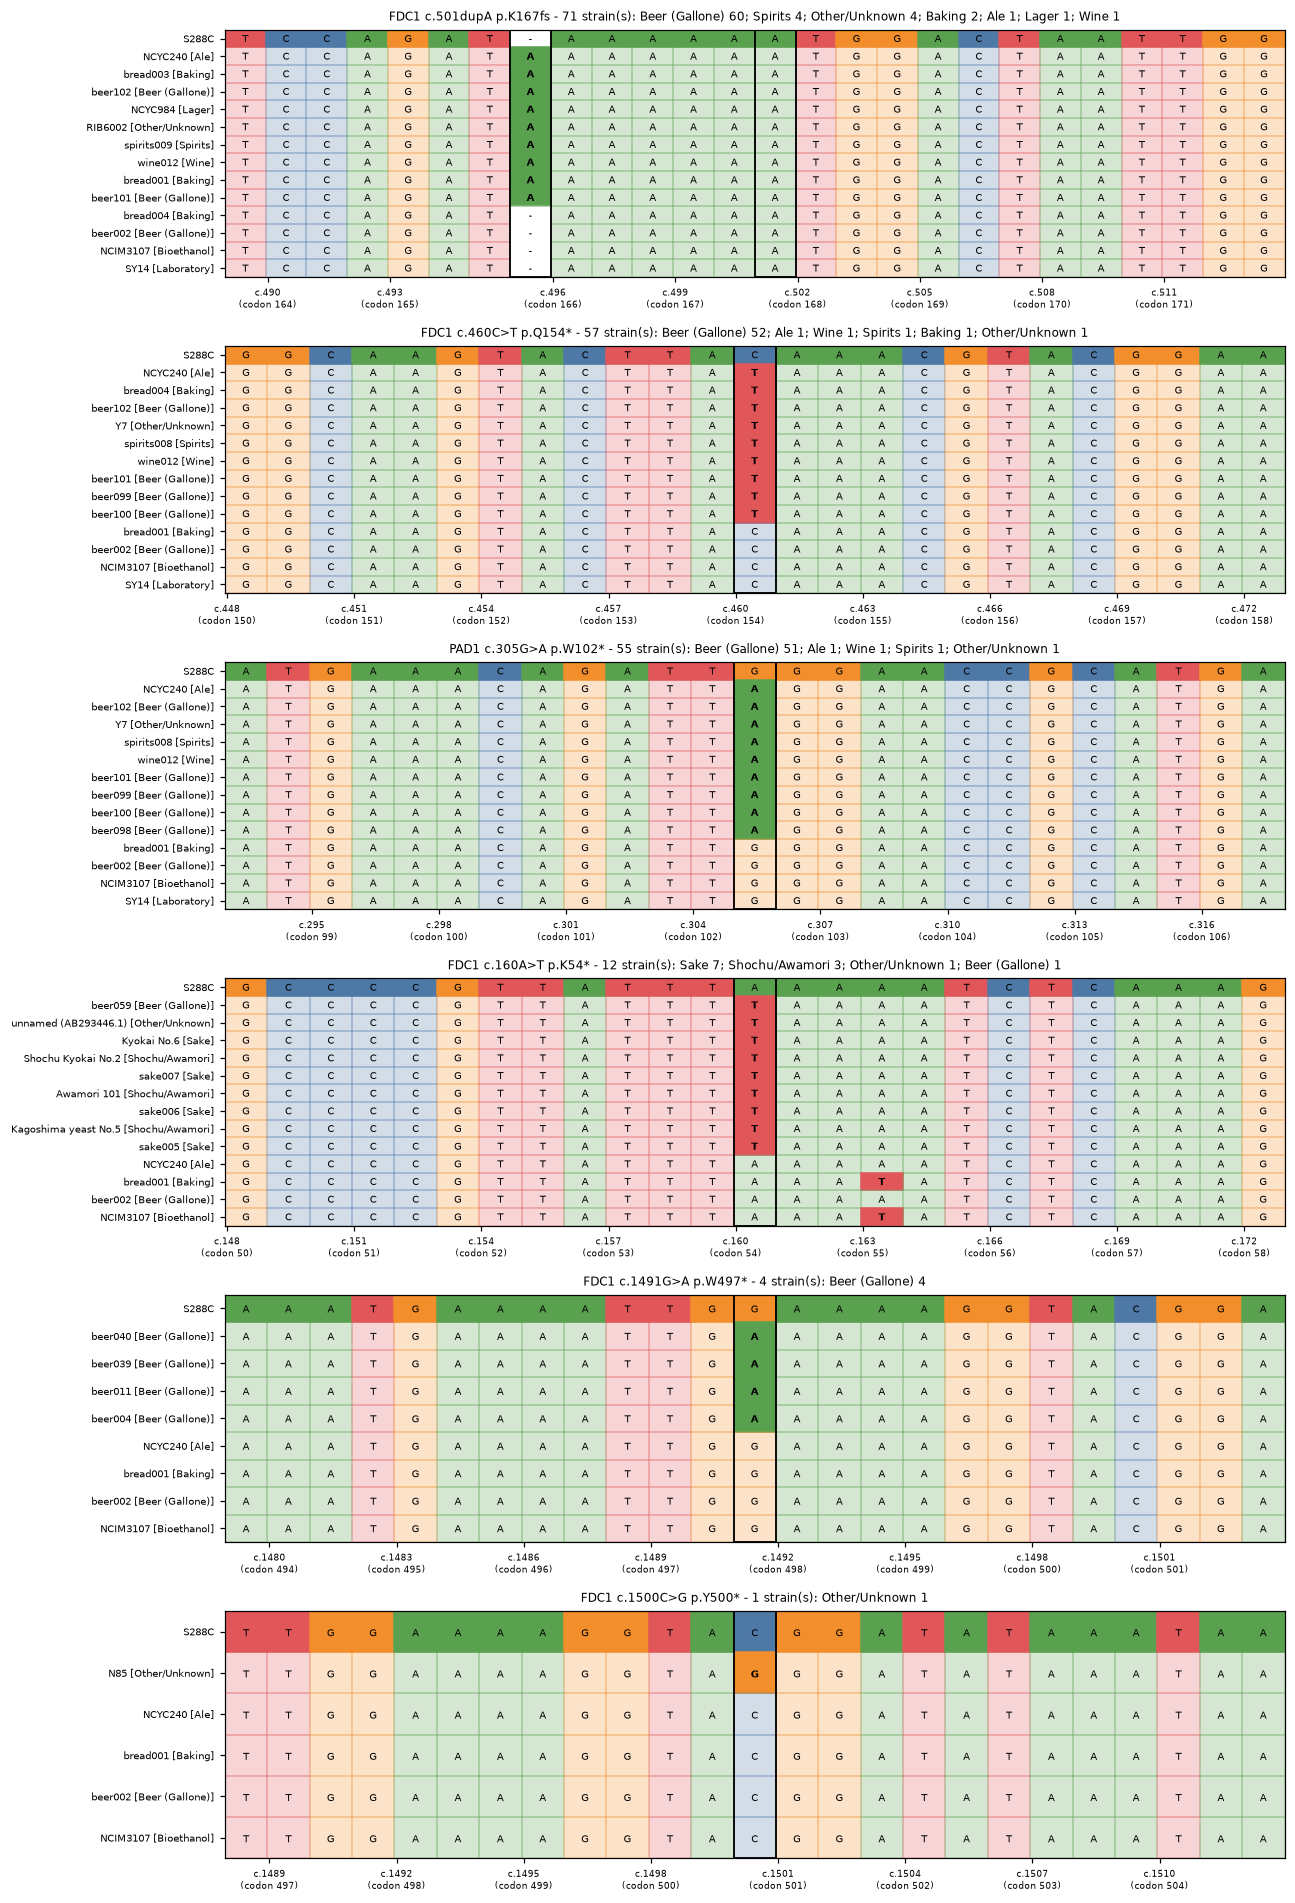

In [19]:
# 3.4 Recurrent LOF alleles and alignment windows
BASE_COL = {'A': '#59a14f', 'C': '#4e79a7', 'G': '#f28e2b', 'T': '#e15759', '-': '#ffffff'}

def ref_projection(aln):
    """dict ref_pos(0-based) -> (base, inserted_after) for one allele alignment."""
    R, A = aln[0], aln[1]
    out, rpos = {}, -1
    for x, y in zip(R, A):
        if x == '-':
            if rpos >= 0:
                b, ins = out[rpos]
                out[rpos] = (b, ins + y)
        else:
            rpos += 1
            out[rpos] = (y, '')
    return out

def window_plot(ax, g, center, sacc_list, half=12):
    lo, hi = max(0, center - 1 - half), min(len(ref_cds[g]), center + half)
    proj = {s: ref_projection(ALN[(g, s)]) for s in sacc_list}
    max_ins = {p: max([len(proj[s].get(p, ('', ''))[1]) for s in sacc_list] + [0]) for p in range(lo, hi)}
    cols = []  # (ref_pos, ins_index or None)
    for p in range(lo, hi):
        cols.append((p, None))
        cols += [(p, k) for k in range(max_ins[p])]
    rows = [('S288C', None)] + [(s, proj[s]) for s in sacc_list]
    for y, (name, pr) in enumerate(rows):
        for x, (p, k) in enumerate(cols):
            if pr is None:
                b = ref_cds[g][p] if k is None else '-'
                refb = b
            else:
                b0, ins = pr.get(p, (' ', ''))
                b = b0 if k is None else (ins[k] if k < len(ins) else '-')
                refb = ref_cds[g][p] if k is None else '-'
            same = b == refb
            ax.add_patch(plt.Rectangle((x, y), 1, 1, color=BASE_COL.get(b, '#dddddd'), alpha=0.25 if same and pr is not None else 1))
            ax.text(x + 0.5, y + 0.55, b, ha='center', va='center', fontsize=6.5, fontweight='normal' if same else 'bold')
    ticks = [x for x, (p, k) in enumerate(cols) if k is None and p % 3 == 0]
    ax.set_xticks([t + 0.05 for t in ticks])
    ax.set_xticklabels([f'c.{cols[t][0] + 1}\n(codon {cols[t][0] // 3 + 1})' for t in ticks], fontsize=6)
    ax.set_yticks([y + 0.5 for y in range(len(rows))])
    ax.set_yticklabels(['S288C'] + [f"{meta.loc[s, 'strain']} [{meta.loc[s, 'group']}]" for s in sacc_list], fontsize=6.5)
    ax.set_xlim(0, len(cols)); ax.set_ylim(len(rows), 0)
    for x, (p, k) in enumerate(cols):
        if (k is None and p == center - 1) or k is not None:  # mark the site and any insertion column
            ax.add_patch(plt.Rectangle((x, 0), 1, len(rows), fill=False, ec='k', lw=1.2))

lof_v = VC[VC.effect.isin(LOFEFF)].merge(AS_c[['gene', 'sacc', 'LOF']], on=['gene', 'sacc'])
recurrent = (lof_v.groupby(['gene', 'hgvs_c', 'cds_pos', 'effect', 'protein_change'])
             .agg(n_strains=('strain', 'nunique'), n_records=('sacc', 'nunique'), n_called_LOF=('LOF', lambda x: int(np.nansum(x))),
                  groups=('group', lambda x: '; '.join(f'{k} {v}' for k, v in x.value_counts().items())),
                  carriers=('sacc', list))
             .reset_index().sort_values(['n_strains', 'gene'], ascending=[False, True]))
recurrent.drop(columns='carriers').to_csv(f'{RES}/recurrent_lof_alleles.csv', index=False)
print(recurrent.drop(columns=['carriers', 'cds_pos']).to_string(index=False))

def pick(saccs, k):
    """Up to k records, spread across groups (round-robin)."""
    by = meta.loc[saccs].groupby('group').groups
    lists, out = [list(v) for v in by.values()], []
    while len(out) < k and any(lists):
        for l in lists:
            if l and len(out) < k:
                out.append(l.pop(0))
    return out

if len(recurrent):
    show = recurrent.head(6)
    fig, axes = plt.subplots(len(show), 1, figsize=(12, 2.9 * len(show)), squeeze=False)
    for ax, r in zip(axes[:, 0], show.itertuples()):
        others = pick([s for s in AS_c[AS_c.gene == r.gene].sacc if s not in r.carriers], 4)
        window_plot(ax, r.gene, r.cds_pos, pick(r.carriers, 9) + others)
        ax.set_title(f'{r.gene} {r.hgvs_c} {r.protein_change} - {r.n_strains} strain(s): {r.groups}', fontsize=8)
    plt.tight_layout()
    plt.savefig(f'{FIG}/03b_lof_alignment_windows.png', dpi=200)
    plt.show()
else:
    print('No nonsense/frameshift variants found - no alignment windows drawn.')

                      mean                                  size                            
gene                  FDC1      PAD1 either (strain POF-)   FDC1   PAD1 either (strain POF-)
group                                                                                       
Laboratory             0.2       0.2                 0.25    5.0    5.0                  4.0
Wild                   0.0       0.0                  0.0    7.0    7.0                  7.0
Wine              0.083333  0.043478             0.086957   24.0   23.0                 23.0
Bioethanol             0.0       0.0                  0.0    6.0    5.0                  5.0
Baking                0.75       0.0                 0.75    4.0    4.0                  4.0
Wheat/Hefeweizen       0.0         0                    0    1.0    0.0                  0.0
Beer (Gallone)    0.598039  0.509804             0.598039  102.0  102.0                102.0
Ale                    1.0       1.0                  1.0    1.0    1.

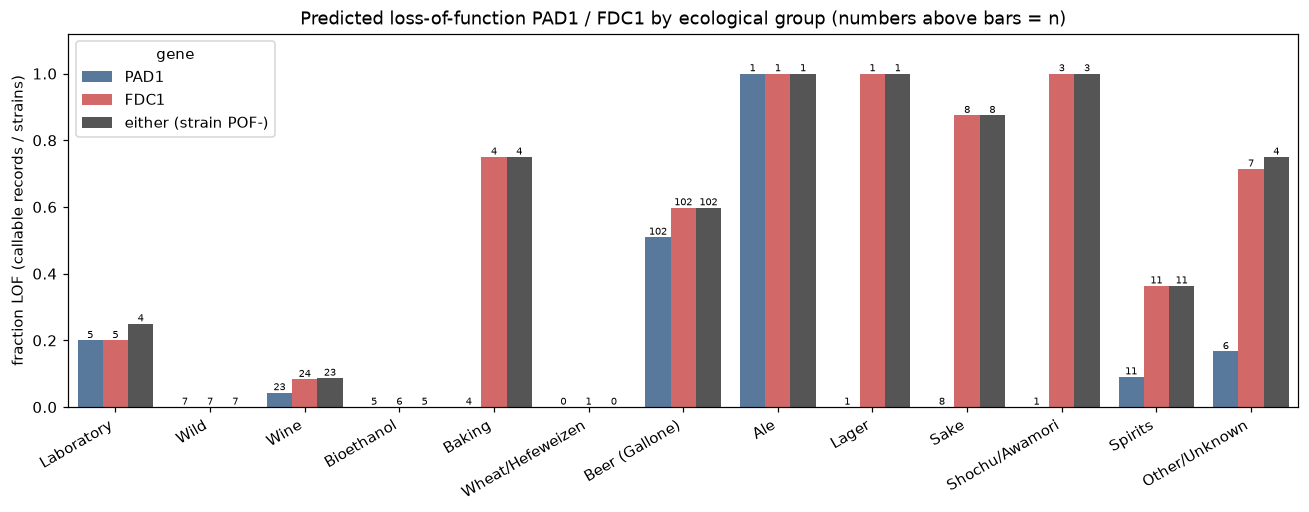

In [20]:
# 3.5 LOF frequency by ecological group and the predicted POF phenotype
lof_mat = allele_summary.pivot_table(index=['group', 'strain'], columns='gene', values='LOF', aggfunc='mean').reindex(columns=VC_GENES)
for st_ in set(allele_summary.set_index(['group', 'strain']).index) - set(lof_mat.index):  # only non-callable records
    lof_mat.loc[st_, :] = np.nan

def pof_call(r):
    if (r == 1).any():
        return 'POF-'
    if r.isna().any() or (r > 0).any():
        return '?'
    return 'POF+'

pof = lof_mat.apply(pof_call, axis=1).rename('predicted_POF')
genotype = lof_mat.assign(predicted_POF=pof).reset_index()
genotype['g_rank'] = genotype.group.map({g: i for i, g in enumerate(GROUP_ORDER)}).fillna(99)
genotype = genotype.sort_values(['g_rank', 'strain']).drop(columns='g_rank').reset_index(drop=True)
genotype.to_csv(f'{RES}/pof_genotype_by_strain.csv', index=False)

frac = (AS_c.groupby(['group', 'gene']).LOF.agg(['mean', 'size']).reset_index())
gp = genotype[genotype.predicted_POF != '?'].groupby('group').predicted_POF
frac = pd.concat([frac, pd.DataFrame({'group': gp.size().index, 'gene': 'either (strain POF-)',
                                      'mean': gp.apply(lambda x: (x == 'POF-').mean()).values, 'size': gp.size().values})])
hue_order = VC_GENES + ['either (strain POF-)']
frac = (frac.set_index(['group', 'gene']).reindex(pd.MultiIndex.from_product([grp_order, hue_order], names=['group', 'gene']))
        .fillna({'mean': 0, 'size': 0}).reset_index())
fig, ax = plt.subplots(figsize=(12, 4.8))
sns.barplot(data=frac, x='group', y='mean', hue='gene', order=grp_order, hue_order=hue_order,
            palette=['#4c78a8', '#e45756', '#555555'], ax=ax)
for cont, g in zip(ax.containers, hue_order):
    sub = frac[frac.gene == g].set_index('group')['size']
    ax.bar_label(cont, labels=[f'{int(sub[t.get_text()])}' for t in ax.get_xticklabels()], fontsize=6.5)
ax.set_ylim(0, 1.12); ax.set_ylabel('fraction LOF (callable records / strains)'); ax.set_xlabel('')
ax.set_title('Predicted loss-of-function PAD1 / FDC1 by ecological group (numbers above bars = n)')
plt.xticks(rotation=30, ha='right'); plt.tight_layout()
plt.savefig(f'{FIG}/03c_lof_fraction_by_group.png', dpi=200)
plt.show()
print(frac.pivot(index='group', columns='gene', values=['mean', 'size']).reindex(grp_order).round(3).to_string())

genotype_class    both intact  PAD1 LOF only  FDC1 LOF only  both LOF  incomplete / not callable
group                                                                                           
Laboratory                  3              0              0         1                          2
Wild                        7              0              0         0                          0
Wine                       21              0              1         1                          1
Bioethanol                  5              0              0         0                          1
Baking                      1              0              3         0                          0
Wheat/Hefeweizen            0              0              0         0                          1
Beer (Gallone)             41              0              9        52                          0
Ale                         0              0              0         1                          0
Lager                       0 

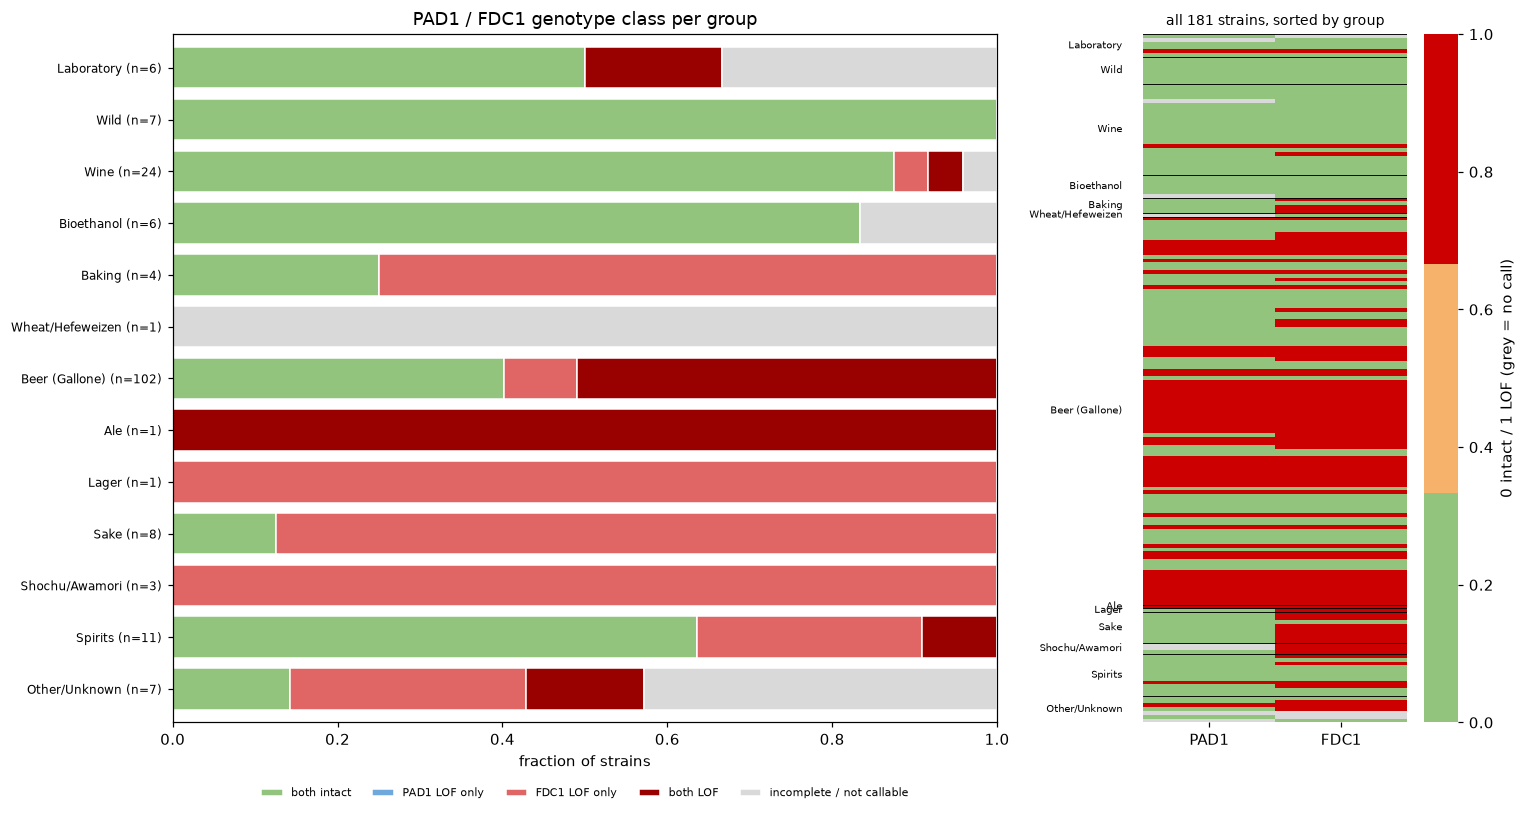

In [21]:
def geno_class(r):
    p, f = r['PAD1'], r['FDC1']
    if p == 1 and f == 1: return 'both LOF'
    if f == 1: return 'FDC1 LOF only'
    if p == 1: return 'PAD1 LOF only'
    if p == 0 and f == 0: return 'both intact'
    return 'incomplete / not callable'

CLASS_COL = {'both intact': '#93c47d', 'PAD1 LOF only': '#6fa8dc', 'FDC1 LOF only': '#e06666', 'both LOF': '#990000',
             'incomplete / not callable': '#d9d9d9'}
genotype['genotype_class'] = genotype.apply(geno_class, axis=1)
genotype.to_csv(f'{RES}/pof_genotype_by_strain.csv', index=False)
counts = pd.crosstab(genotype.group, genotype.genotype_class).reindex(index=grp_order, columns=list(CLASS_COL), fill_value=0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, max(5, 0.42 * len(grp_order) + 2)), gridspec_kw={'width_ratios': [3, 1.2]})
(counts.div(counts.sum(axis=1), axis=0)).plot.barh(stacked=True, color=list(CLASS_COL.values()), ax=a1, width=0.8, edgecolor='white')
a1.set_yticklabels([f'{g} (n={counts.loc[g].sum()})' for g in grp_order], fontsize=8); a1.invert_yaxis()
a1.set_xlabel('fraction of strains'); a1.set_ylabel(''); a1.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=5, frameon=False)
a1.set_title('PAD1 / FDC1 genotype class per group')
hm = genotype[VC_GENES].astype(float)
sns.heatmap(hm, cmap=sns.color_palette(['#93c47d', '#f6b26b', '#cc0000'], as_cmap=True), vmin=0, vmax=1, ax=a2,
            cbar_kws={'label': '0 intact / 1 LOF (grey = no call)'}, yticklabels=False)
a2.set_facecolor('#d9d9d9')
bounds = genotype.index[genotype.group.ne(genotype.group.shift())].tolist() + [len(genotype)]
for b0, b1 in zip(bounds[:-1], bounds[1:]):
    a2.axhline(b0, color='k', lw=0.6)
    a2.text(-0.08, (b0 + b1) / 2, genotype.group[b0], ha='right', va='center', fontsize=6.5, transform=a2.get_yaxis_transform())
a2.set_title(f'all {len(genotype)} strains, sorted by group', fontsize=9); a2.set_xlabel('')
plt.tight_layout()
plt.savefig(f'{FIG}/03d_lof_matrix.png', dpi=200)
plt.show()
print(counts.to_string())

In [22]:
# 3.6 Is LOF enriched in domesticated beverage yeasts? (Fisher's exact test)
from scipy.stats import fisher_exact, chi2_contingency
Gt = genotype[genotype.predicted_POF != '?']
DOMESTIC = ['Beer (Gallone)', 'Ale', 'Lager', 'Sake', 'Shochu/Awamori', 'Spirits']
stat_rows = []
for label, A_, B_ in [('Domesticated beverage vs Wild+Wine+Bioethanol', DOMESTIC, ['Wild', 'Wine', 'Bioethanol']),
                      ('Beer (Gallone)+Ale vs Wild+Wine', ['Beer (Gallone)', 'Ale'], ['Wild', 'Wine'])]:
    a, b = Gt[Gt.group.isin(A_)], Gt[Gt.group.isin(B_)]
    tab = [[(a.predicted_POF == 'POF-').sum(), (a.predicted_POF == 'POF+').sum()],
           [(b.predicted_POF == 'POF-').sum(), (b.predicted_POF == 'POF+').sum()]]
    odds, pval = fisher_exact(tab)
    stat_rows.append(dict(test=label, a_POFneg=tab[0][0], a_POFpos=tab[0][1], b_POFneg=tab[1][0], b_POFpos=tab[1][1],
                          odds_ratio=odds, fisher_p=pval))
ct = pd.crosstab(Gt.group, Gt.predicted_POF)
chi2, chi_p, dof, _ = chi2_contingency(ct)
stat_rows.append(dict(test=f'chi-square, all groups x POF ({dof} df)', fisher_p=np.nan, chi2=chi2, chi2_p=chi_p))
stats_tbl = pd.DataFrame(stat_rows)
stats_tbl.to_csv(f'{RES}/lof_enrichment_tests.csv', index=False)
print(ct.to_string()); print()
print(stats_tbl.to_string(index=False))

predicted_POF   POF+  POF-
group                     
Ale                0     1
Baking             1     3
Beer (Gallone)    41    61
Bioethanol         5     0
Laboratory         3     1
Lager              0     1
Other/Unknown      1     3
Sake               1     7
Shochu/Awamori     0     3
Spirits            7     4
Wild               7     0
Wine              21     2

                                         test  a_POFneg  a_POFpos  b_POFneg  b_POFpos  odds_ratio     fisher_p      chi2   chi2_p
Domesticated beverage vs Wild+Wine+Bioethanol      77.0      49.0       2.0      33.0   25.928571 1.136684e-09       NaN      NaN
              Beer (Gallone)+Ale vs Wild+Wine      62.0      41.0       2.0      28.0   21.170732 6.728408e-08       NaN      NaN
         chi-square, all groups x POF (11 df)       NaN       NaN       NaN       NaN         NaN          NaN 44.931124 0.000005


In [23]:
# Computed summary used by the interpretation below, cross-checked against the literature (Mukai 2014; Mertens 2019)
def strain_list(df, cap=12):
    names = sorted(set(df.strain if isinstance(df, pd.DataFrame) else df))
    return (', '.join(names[:cap]) + (f' ... (+{len(names) - cap})' if len(names) > cap else '')) or 'none'

print(f"Records: PAD1 {sum(allele_summary.gene == 'PAD1')}, FDC1 {sum(allele_summary.gene == 'FDC1')} "
      f"({(~allele_summary.callable).sum()} not callable); strains: {len(genotype)}")
for g in VC_GENES:
    A = AS_c[AS_c.gene == g]
    print(f"\n{g}: {int(A.LOF.sum())}/{len(A)} callable records LOF")
    for grp in grp_order:
        sub = A[A.group == grp]
        if len(sub):
            print(f"  {grp:18s} {int(sub.LOF.sum()):3d}/{len(sub):<3d} LOF: {strain_list(sub[sub.LOF == 1])}")
for h, lab in [('c.460C>T', 'FDC1 Q154*'), ('c.501dupA', 'FDC1 c.501dupA (= c.495_496insA left-aligned)'),
               ('c.160A>T', 'FDC1 K54*'), ('c.305G>A', 'PAD1 W102*')]:
    r = recurrent[recurrent.hgvs_c == h]
    print(f"{lab}: " + (f"{r.n_strains.iloc[0]} strains - {r.groups.iloc[0]}" if len(r) else 'none'))
bneg = genotype[(genotype.group == 'Beer (Gallone)') & (genotype.predicted_POF == 'POF-')].strain
q154 = set(VC[(VC.hgvs_c == 'c.460C>T') & (VC.gene == 'FDC1')].strain)
print(f"Q154* among POF- Beer (Gallone) strains: {len(set(bneg) & q154)}/{len(bneg)} "
      f"({100 * len(set(bneg) & q154) / max(1, len(bneg)):.1f} %; Mertens 2019: 73.8 % of POF- Beer 1)")
late = VC[VC.effect == 'nonsense'].merge(AS_c[['gene', 'sacc', 'LOF', 'protein_len']], on=['gene', 'sacc'])
late = late[late.LOF == 0]
print('\nNonsense SNVs NOT called LOF (stop at >= 95 % of reference length):')
print(late.groupby(['gene', 'hgvs_c', 'protein_change', 'protein_len']).strain.apply(strain_list).to_string() if len(late) else '  none')
EXPECT = {'Laboratory': 'POF+', 'Wine': 'POF+', 'Wild': 'POF+', 'Bioethanol': 'POF+', 'Wheat/Hefeweizen': 'POF+',
          'Ale': 'POF-', 'Lager': 'POF-', 'Sake': 'POF-', 'Shochu/Awamori': 'POF-'}
genotype['expected'] = genotype.group.map(EXPECT).fillna('?')
mism = genotype[(genotype.expected != '?') & (genotype.predicted_POF != '?') & (genotype.expected != genotype.predicted_POF)]
print('\nStrains whose predicted POF disagrees with the expectation for their group:')
print(mism[['group', 'strain', 'PAD1', 'FDC1', 'predicted_POF', 'expected']].to_string(index=False) if len(mism) else '  none')
inc = genotype[genotype.predicted_POF == '?']
print(f"\nStrains with no POF call ('?'): {strain_list(inc, 30)}")
amb = variant_calls[variant_calls.type == 'ambiguous']
print('Ambiguous (IUPAC) base calls:', ', '.join(f'{r.gene} {r.strain} {r.hgvs_c}' for r in amb.itertuples()) or 'none')

Records: PAD1 176, FDC1 180 (2 not callable); strains: 181

PAD1: 57/174 callable records LOF
  Laboratory           1/5   LOF: laboratory001
  Wild                 0/7   LOF: none
  Wine                 1/23  LOF: wine012
  Bioethanol           0/5   LOF: none
  Baking               0/4   LOF: none
  Beer (Gallone)      52/102 LOF: beer001, beer007, beer008, beer009, beer010, beer012, beer015, beer019, beer035, beer036, beer037, beer041 ... (+40)
  Ale                  1/1   LOF: NCYC240
  Lager                0/1   LOF: none
  Sake                 0/8   LOF: none
  Shochu/Awamori       0/1   LOF: none
  Spirits              1/11  LOF: spirits008
  Other/Unknown        1/6   LOF: Y7

FDC1: 88/180 callable records LOF
  Laboratory           1/5   LOF: laboratory001
  Wild                 0/7   LOF: none
  Wine                 2/24  LOF: wine012, wine014
  Bioethanol           0/6   LOF: none
  Baking               3/4   LOF: bread001, bread003, bread004
  Wheat/Hefeweizen     0/1   LOF

In [24]:
# 4. Phylogeny, clustering and MAL/MPH copy number
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
import seaborn as sns
from Bio import SeqIO, Phylo
from Bio.Align import PairwiseAligner, MultipleSeqAlignment
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.Phylo.TreeConstruction import DistanceMatrix, DistanceTreeConstructor
from Bio.Phylo.Consensus import get_support
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
from scipy.stats import mannwhitneyu
from sklearn.decomposition import PCA
from sklearn.manifold import MDS
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

os.makedirs("data/results", exist_ok=True); os.makedirs("figures", exist_ok=True)
GROUPS = ["Beer (Gallone)", "Ale", "Lager", "Wheat/Hefeweizen", "Wine", "Sake", "Shochu/Awamori", "Spirits", "Baking",
          "Bioethanol", "Laboratory", "Wild", "Clinical", "Other/Unknown"]
PALETTE = dict(zip(GROUPS, sns.color_palette("tab10").as_hex() + ["#000000", "#556b2f", "#b8860b", "#00008b"]))
POF_COL = {"POF-": "#000000", "POF+": "#dddddd", "?": "#ff69b4"}
N_BOOT = int(os.environ.get("N_BOOT", 100))
rng = np.random.default_rng(0)

In [25]:
# helpers (pure functions; tests/test_phylo.py runs this cell on its own)
aligner = PairwiseAligner(mode="global", match_score=2, mismatch_score=-1,
                          open_gap_score=-5, extend_gap_score=-0.5)

def pct_identity(a, b):
    """% identical columns in the best global alignment (gaps count as differences)."""
    aln = aligner.align(a, b)[0]
    return 100 * aln.counts().identities / aln.length

def reference_guided_msa(ref, seqs):
    """Align every sequence to the reference and project it onto reference coordinates.
    Insertions relative to the reference get their own gap-padded columns, so the result is a
    true MSA (all rows same length). shortcut: no realignment between non-reference sequences;
    fine for near-identical alleles, use Clustal Omega/MUSCLE for divergent sets."""
    L = len(ref)
    rows = {}
    for name, s in seqs.items():
        aln = aligner.align(ref, s)[0]
        main, ins, k = ["-"] * L, [""] * (L + 1), 0   # ins[k] = bases inserted before ref position k
        for r, q in zip(aln[0], aln[1]):
            if r == "-": ins[k] += q
            else: main[k] = q; k += 1
        rows[name] = (main, ins)
    width = [max(len(rows[n][1][k]) for n in rows) for k in range(L + 1)]
    out = {}
    for n, (main, ins) in rows.items():
        parts = []
        for k in range(L + 1):
            parts.append(ins[k].ljust(width[k], "-"))
            if k < L: parts.append(main[k])
        out[n] = "".join(parts)
    return MultipleSeqAlignment([SeqRecord(Seq(v), id=n) for n, v in out.items()])

def msa_array(msa):
    return np.array([np.frombuffer(str(r.seq).encode(), dtype=np.uint8) for r in msa])

def p_distance(A):
    """Pairwise p-distance between MSA rows: differing columns / columns not gapped in both
    (= 1 - alignment-induced identity). Same idea as DistanceCalculator('identity'), vectorised with numpy."""
    gap = A == ord("-")
    D = np.zeros((len(A), len(A)))
    for i in range(len(A)):
        both = gap[i] & gap
        D[i] = ((A[i] != A) & ~both).sum(1) / (~both).sum(1)
    return D

def to_dm(names, D):
    return DistanceMatrix(list(names), [list(D[i, :i + 1]) for i in range(len(names))])

def one_hot_variable(msa):
    """One-hot encode only the MSA columns that are not constant."""
    A = np.array([list(str(r.seq)) for r in msa])
    var = [j for j in range(A.shape[1]) if len(set(A[:, j])) > 1]
    df = pd.DataFrame(A[:, var], index=[r.id for r in msa], columns=var)
    return pd.get_dummies(df.astype(str)).astype(int)

def build_trees(msa):
    names = [r.id for r in msa]
    dm = to_dm(names, p_distance(msa_array(msa)))
    c = DistanceTreeConstructor()
    nj, up = c.nj(dm), c.upgma(dm)
    nj.root_at_midpoint()
    for t in (nj, up):
        for cl in t.get_nonterminals(): cl.name = None   # drop 'Inner1' labels so they don't print
    return dm, nj, up

In [26]:
# 4a. Load alleles, strain names, groups and LOF / POF calls
strains = pd.read_csv("data/metadata/strains.csv").set_index("sacc")
summ = pd.read_csv("data/results/allele_summary.csv")
callable_ = {(g, s): bool(c) for g, s, c in zip(summ.gene, summ.sacc, summ.callable)}
lof_of = {(g, s): bool(l) for g, s, l in zip(summ.gene, summ.sacc, summ.LOF) if str(l) in ("True", "False")}
lofallele = {(g, s): a for g, s, a in zip(summ.gene, summ.sacc, summ.LOF_allele) if isinstance(a, str)}
pof = pd.read_csv("data/results/pof_genotype_by_strain.csv").set_index("strain").predicted_POF.to_dict()

def strain_group(sid):
    if sid == "S288C_REF": return "S288C", "Laboratory"
    key = sid if sid in strains.index else re.sub(r"_\d+$", "", sid)
    if key not in strains.index: return sid, "Other/Unknown"
    st, g = strains.loc[key, ["strain", "group"]]
    return str(st), (g if g in PALETTE else "Other/Unknown")

alleles, meta = {}, []
for gene in ["PAD1", "FDC1"]:
    recs = [r for r in SeqIO.parse(f"data/seqs/{gene}_alleles.fasta", "fasta")
            if not re.search("PARTIAL|CONTAINS_N", r.description) and callable_.get((gene, r.id), True)]
    alleles[gene] = {r.id: str(r.seq).upper() for r in recs}
    for r in recs:
        st, gr = strain_group(r.id)
        meta.append(dict(gene=gene, sacc=r.id, strain=st, group=gr, LOF=lof_of.get((gene, r.id), False),
                         LOF_allele=lofallele.get((gene, r.id), ""), POF=pof.get(st, "POF+" if r.id == "S288C_REF" else "?")))
meta = pd.DataFrame(meta)

# Concatenated PAD1+FDC1 for strains with both (first accession per gene; strain names from strains.csv)
gm = meta.drop_duplicates("sacc").set_index("sacc")
p = pd.read_csv("data/seqs/paired_strains.csv")
pairs = [("S288C", "S288C_REF", "S288C_REF")] + [
    (gm.loc[a, "strain"], a, b) for a, b in zip(p.pad1_sacc.str.split(";").str[0], p.fdc1_sacc.str.split(";").str[0])
    if a in alleles["PAD1"] and b in alleles["FDC1"]]
pairs = list({st: (st, a, b) for st, a, b in pairs}.values())
cid = lambda st: re.sub(r"[^A-Za-z0-9.]+", "_", st)   # safe leaf names for Newick
alleles["PAD1_FDC1"] = {cid(st): alleles["PAD1"][a] + alleles["FDC1"][b] for st, a, b in pairs}
fm = meta[meta.gene == "FDC1"].set_index("sacc")
cmeta = pd.DataFrame([dict(gene="PAD1_FDC1", sacc=cid(st), strain=st, group=gm.loc[a, "group"],
                           LOF=bool(meta[(meta.gene == "PAD1") & (meta.sacc == a)].LOF.any() or fm.loc[b, "LOF"]),
                           LOF_allele=" + ".join(x for x in [meta[(meta.gene == "PAD1") & (meta.sacc == a)].LOF_allele.iloc[0],
                                                              fm.loc[b, "LOF_allele"]] if x),
                           POF=gm.loc[a, "POF"]) for st, a, b in pairs])
meta = pd.concat([meta, cmeta], ignore_index=True)
meta.to_csv("data/results/phylo_allele_groups.csv", index=False)
info = {(r.gene, r.sacc): r for r in meta.itertuples()}
dup = meta.groupby("gene").strain.apply(lambda v: set(v[v.duplicated()]))   # strains with >1 allele (e.g. RIB6002)
label = lambda gene, x: info[gene, x].strain + (f" ({x})" if info[gene, x].strain in dup[gene] else "")
print(meta.groupby(["group", "gene"]).size().unstack().fillna(0).astype(int))
print("POF status (concatenated set):", cmeta.POF.value_counts().to_dict())

gene              FDC1  PAD1  PAD1_FDC1
group                                  
Ale                  1     1          1
Baking               4     4          4
Beer (Gallone)     102   102        102
Bioethanol           6     5          5
Laboratory           6     6          4
Lager                1     1          1
Other/Unknown        7     6          3
Sake                 8     8          8
Shochu/Awamori       3     1          1
Spirits             11    11         11
Wheat/Hefeweizen     1     0          0
Wild                 7     7          7
Wine                24    23         23
POF status (concatenated set): {'POF+': 87, 'POF-': 83}


PAD1: excluded divergent allele bioethanol002 [Bioethanol], median identity 89.99%
PAD1: n=174, MSA 174 x 729; identity min 98.22%, median 99.31%; max |MSA - PairwiseAligner| on 10 pairs = 0.000 points
FDC1: excluded divergent allele bioethanol002 [Bioethanol], median identity 90.01%
FDC1: n=180, MSA 180 x 1513; identity min 99.14%, median 99.67%; max |MSA - PairwiseAligner| on 10 pairs = 0.000 points
PAD1_FDC1: excluded divergent allele bioethanol002 [Bioethanol], median identity 90.05%
PAD1_FDC1: n=169, MSA 169 x 2242; identity min 99.06%, median 99.55%; max |MSA - PairwiseAligner| on 10 pairs = 0.000 points


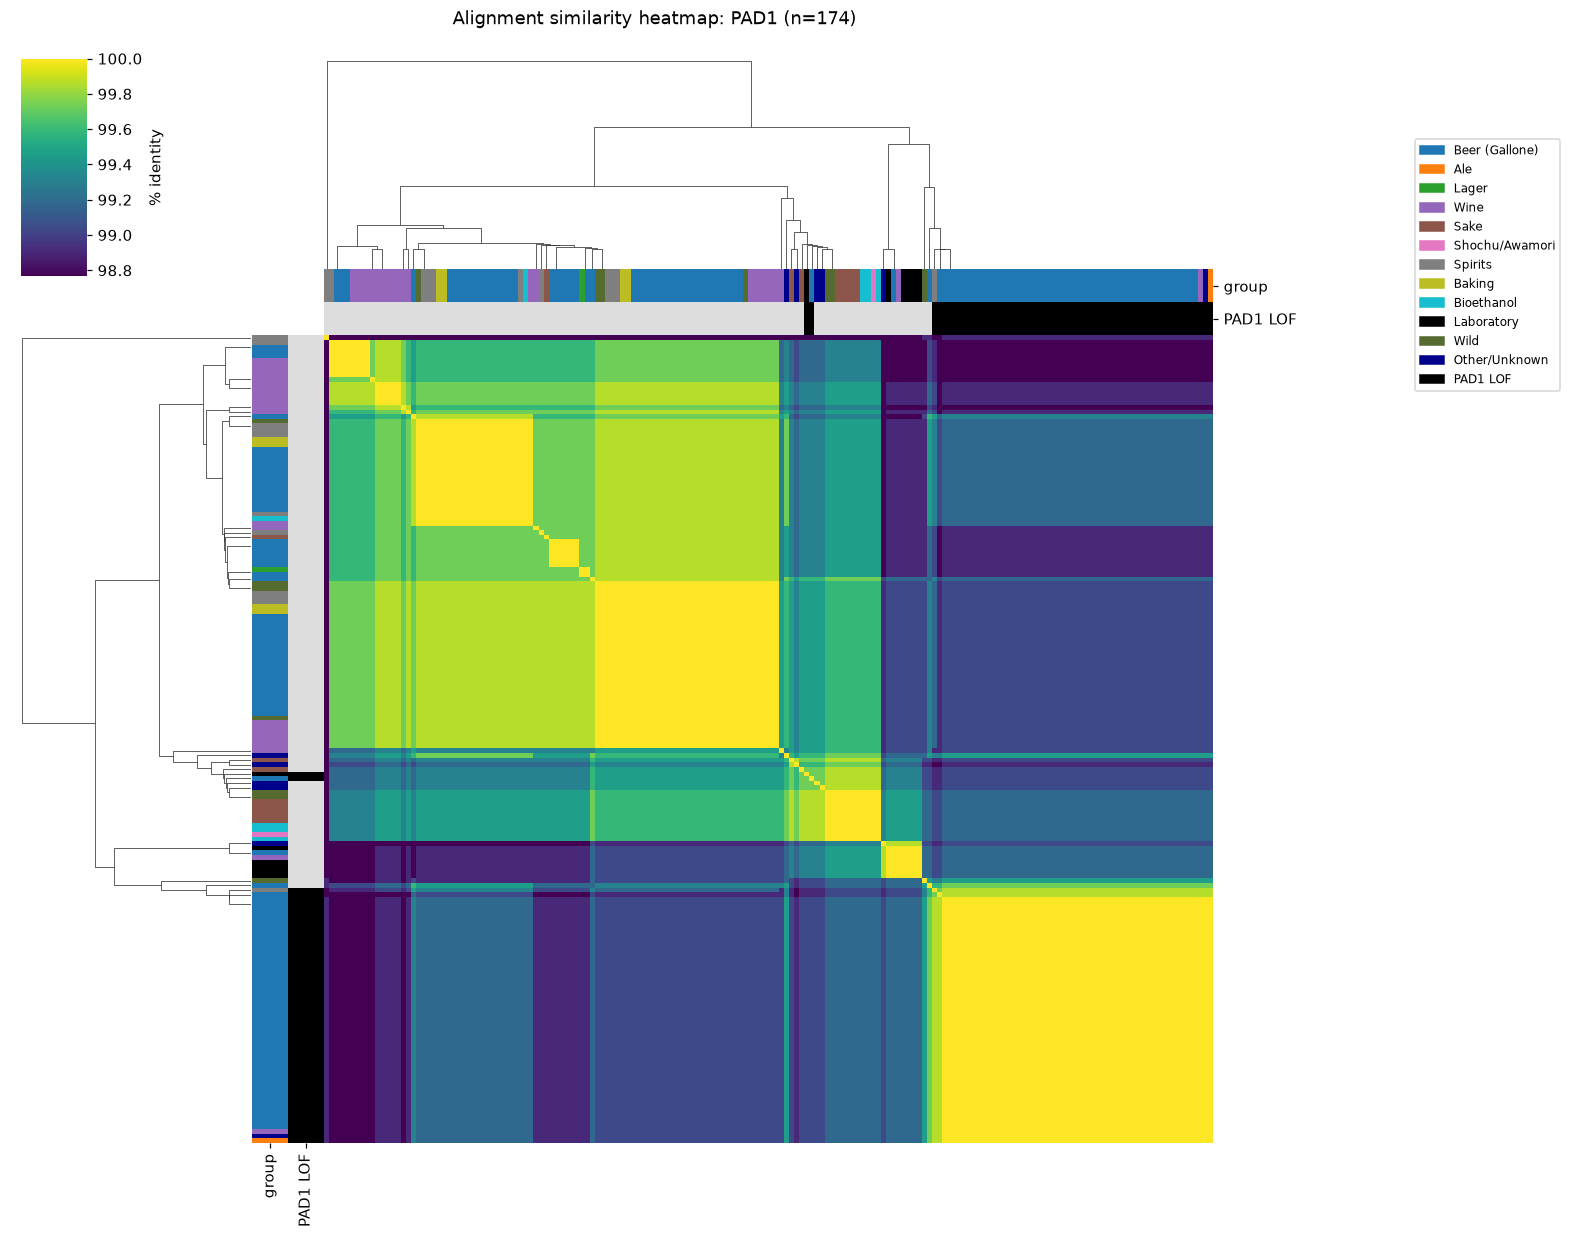

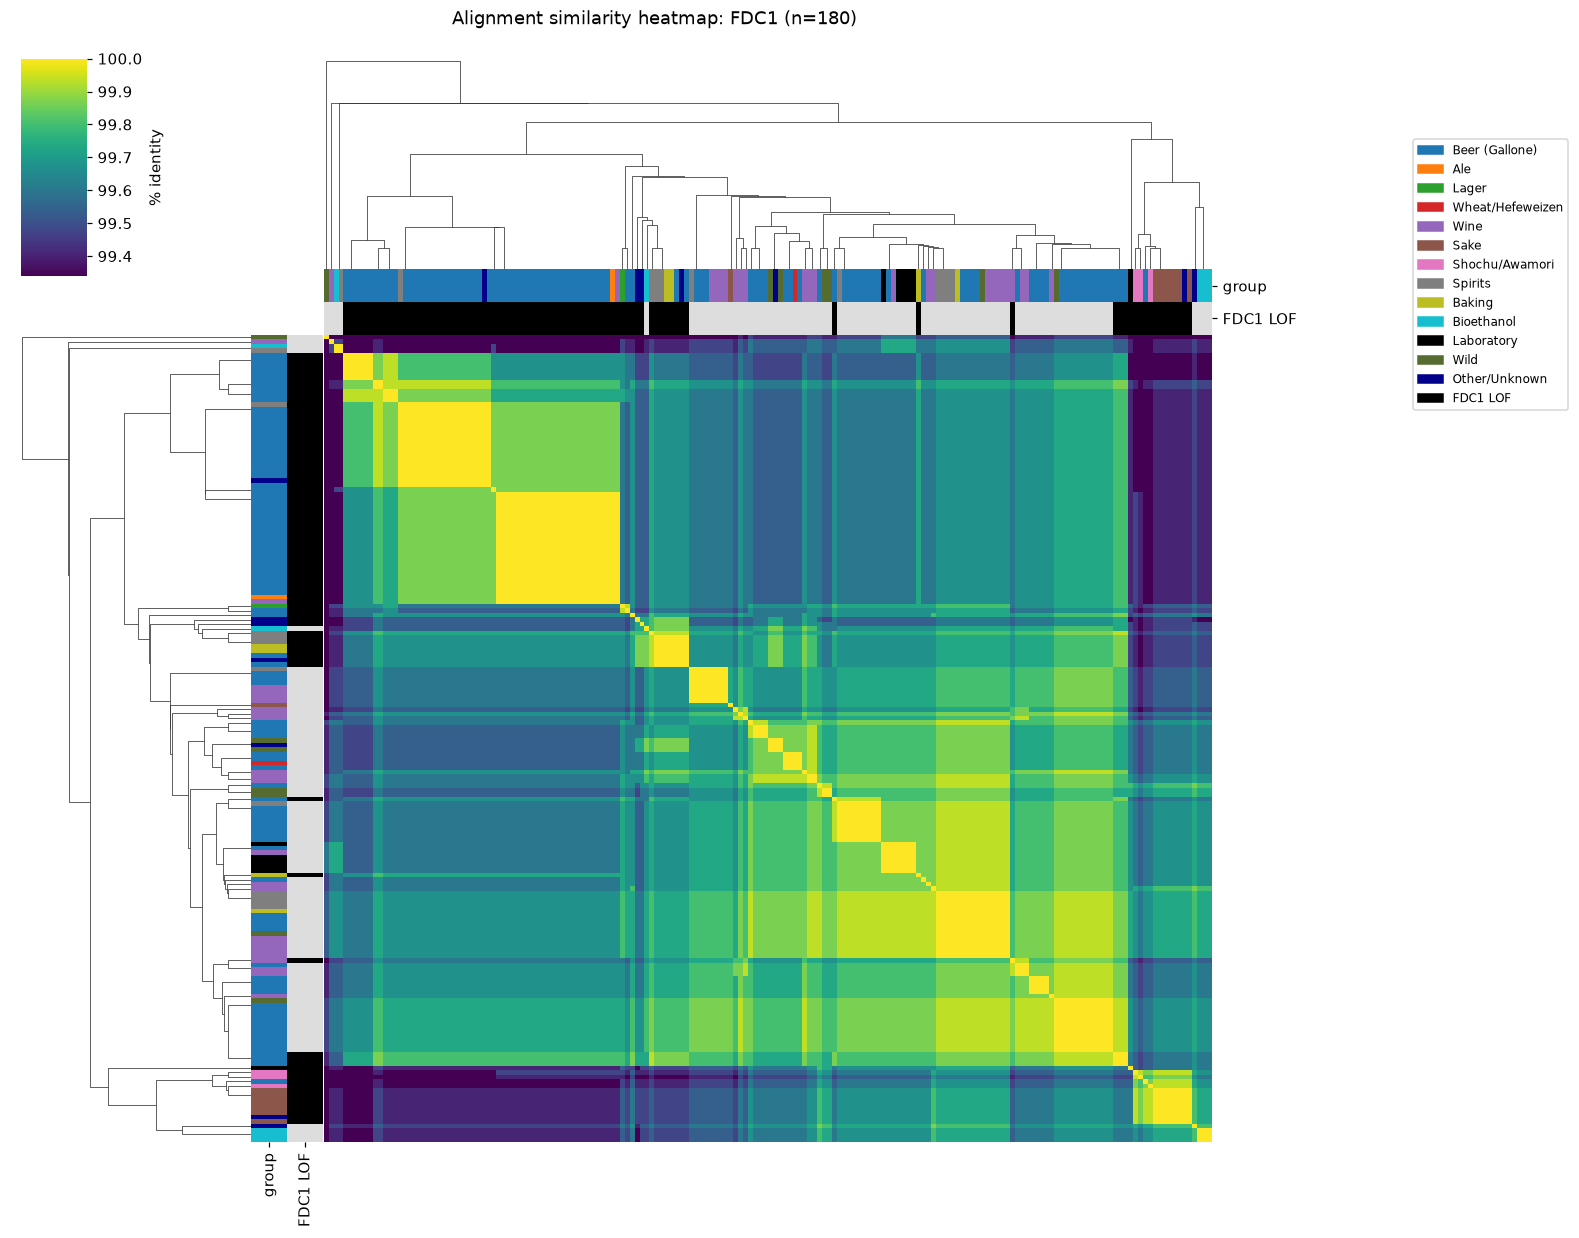

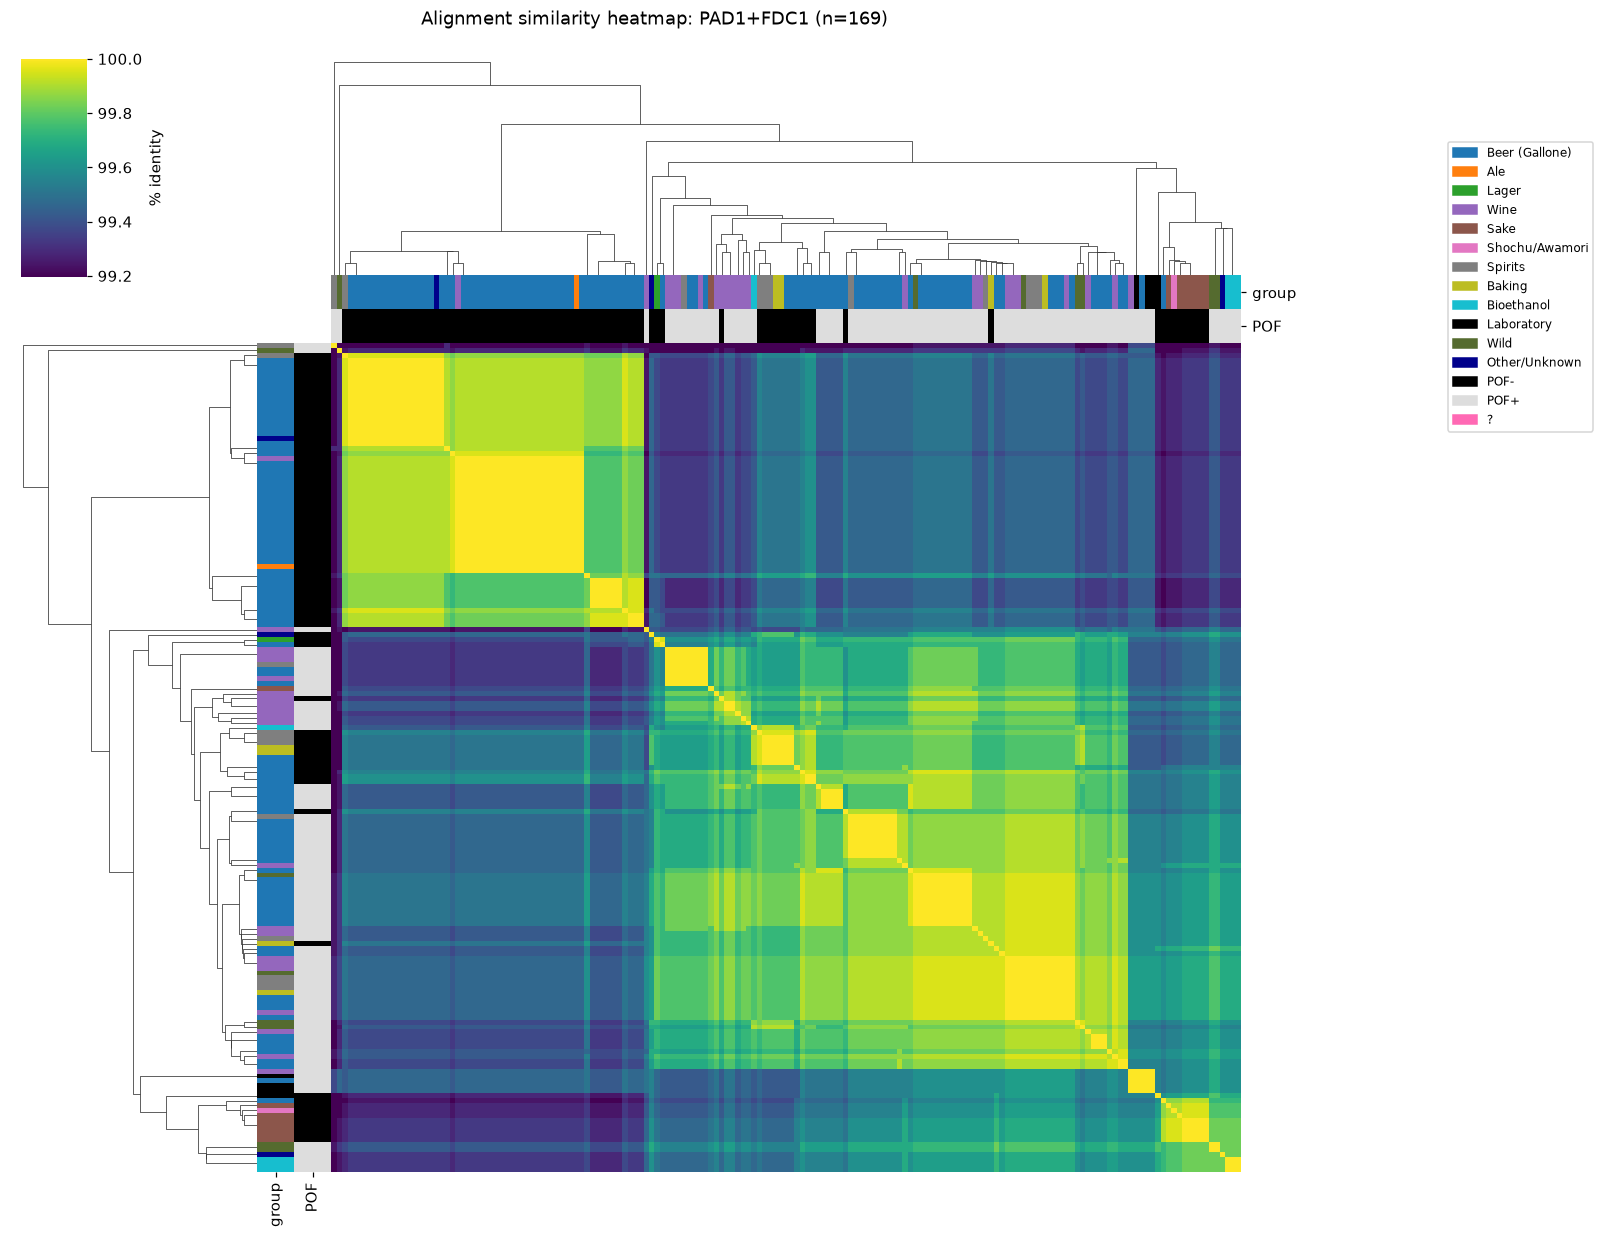

In [27]:
# 4b. Reference-guided MSA and alignment similarity heatmap
msas, ident, outliers = {}, {}, {}
for gene, seqs in alleles.items():
    ref = seqs["S288C_REF"] if "S288C_REF" in seqs else seqs[cid("S288C")]
    msa = reference_guided_msa(ref, seqs)
    names = [r.id for r in msa]
    M = pd.DataFrame(100 * (1 - p_distance(msa_array(msa))), index=names, columns=names)
    # divergent outliers (median identity < 97%, e.g. a non-S. cerevisiae allele) would flatten every tree; report and drop
    out = [x for x in names if M.loc[x].drop(x).median() < 97]
    for x in out:
        print(f"{gene}: excluded divergent allele {label(gene, x)} [{info[gene, x].group}], median identity {M.loc[x].drop(x).median():.2f}%")
        outliers[gene, x] = M.loc[x].drop(x)
    keep = [x for x in names if x not in out]
    M = M.loc[keep, keep]
    msa = MultipleSeqAlignment([r for r in msa if r.id in keep]); names = keep
    alleles[gene] = {x: seqs[x] for x in keep}
    msas[gene] = msa
    with open(f"data/results/{gene}_msa.fasta", "w") as fh: SeqIO.write(msa, fh, "fasta")
    ident[gene] = M
    M.to_csv(f"data/results/{gene}_pct_identity.csv")
    chk = [tuple(rng.choice(names, 2, replace=False)) for _ in range(10)]
    err = max(abs(M.loc[a, b] - pct_identity(seqs[a], seqs[b])) for a, b in chk)
    off = M.values[np.triu_indices(len(M), 1)]
    print(f"{gene}: n={len(M)}, MSA {len(msa)} x {msa.get_alignment_length()}; identity min {off.min():.2f}%, "
          f"median {np.median(off):.2f}%; max |MSA - PairwiseAligner| on 10 pairs = {err:.3f} points")

    stripes = pd.DataFrame({"group": [PALETTE[info[gene, x].group] for x in names],
                            ("POF" if gene == "PAD1_FDC1" else f"{gene} LOF"):
                                [POF_COL[info[gene, x].POF] if gene == "PAD1_FDC1" else ("#000000" if info[gene, x].LOF else "#dddddd")
                                 for x in names]}, index=names)
    Z = linkage(squareform(100 - M.values, checks=False), "average")
    cg = sns.clustermap(M, row_linkage=Z, col_linkage=Z, row_colors=stripes, col_colors=stripes, cmap="viridis",
                        vmin=max(np.percentile(off, 1), 90), vmax=100, figsize=(12, 11), xticklabels=False,
                        yticklabels=len(M) <= 40, cbar_kws={"label": "% identity"})
    cg.fig.suptitle(f"Alignment similarity heatmap: {gene.replace('_', '+')} (n={len(M)})", y=1.02)
    present = [g for g in GROUPS if any(info[gene, x].group == g for x in names)]
    hs = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[g]) for g in present]
    ls = present
    if gene == "PAD1_FDC1": hs += [plt.Rectangle((0, 0), 1, 1, color=c) for c in POF_COL.values()]; ls += list(POF_COL)
    else: hs += [plt.Rectangle((0, 0), 1, 1, color="#000000")]; ls += [f"{gene} LOF"]
    cg.ax_heatmap.legend(hs, ls, loc="upper left", bbox_to_anchor=(1.22, 1.25), fontsize=8)
    cg.savefig(f"figures/heatmap_identity_{gene}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [28]:
# 4c. Haplotypes
haps = {}
for gene, M in ident.items():
    names = list(M.index)
    hid = pd.Series(M.round(8).apply(tuple, axis=1).factorize()[0], index=names)
    order = hid.value_counts().index           # H0 = most common haplotype
    hid = hid.map({h: i for i, h in enumerate(order)})
    h = pd.DataFrame({"sacc": names, "haplotype": hid.values, "strain": [label(gene, x) for x in names],
                      "group": [info[gene, x].group for x in names], "LOF": [info[gene, x].LOF for x in names],
                      "LOF_allele": [info[gene, x].LOF_allele for x in names], "POF": [info[gene, x].POF for x in names]})
    haps[gene] = h
    h.to_csv(f"data/results/{gene}_haplotypes.csv", index=False)
    tab = pd.crosstab(h.haplotype, h.group)
    tab["n"] = tab.sum(axis=1); tab["LOF"] = h.groupby("haplotype").LOF.sum()
    tab["LOF_allele"] = h.groupby("haplotype").LOF_allele.agg(lambda v: "; ".join(sorted(set(x for x in v if x)))[:60])
    print(f"\n{gene}: {h.haplotype.nunique()} haplotypes among {len(h)} strains/alleles; "
          f"haplotypes per group: {h.groupby('group').haplotype.nunique().to_dict()}")
    print(tab[tab.n >= 3].to_string())


PAD1: 32 haplotypes among 174 strains/alleles; haplotypes per group: {'Ale': 1, 'Baking': 2, 'Beer (Gallone)': 12, 'Bioethanol': 2, 'Laboratory': 2, 'Lager': 1, 'Other/Unknown': 6, 'Sake': 4, 'Shochu/Awamori': 1, 'Spirits': 6, 'Wild': 4, 'Wine': 11}
group      Ale  Baking  Beer (Gallone)  Bioethanol  Laboratory  Lager  Other/Unknown  Sake  Shochu/Awamori  Spirits  Wild  Wine   n  LOF                  LOF_allele
haplotype                                                                                                                                                           
0            1       0              50           0           0      0              1     0               0        0     0     1  53   53  c.305G>A p.W102* -> 101 aa
1            0       2              22           0           0      0              0     0               0        3     3     6  36    0                            
2            0       2              14           1           0      0              0     

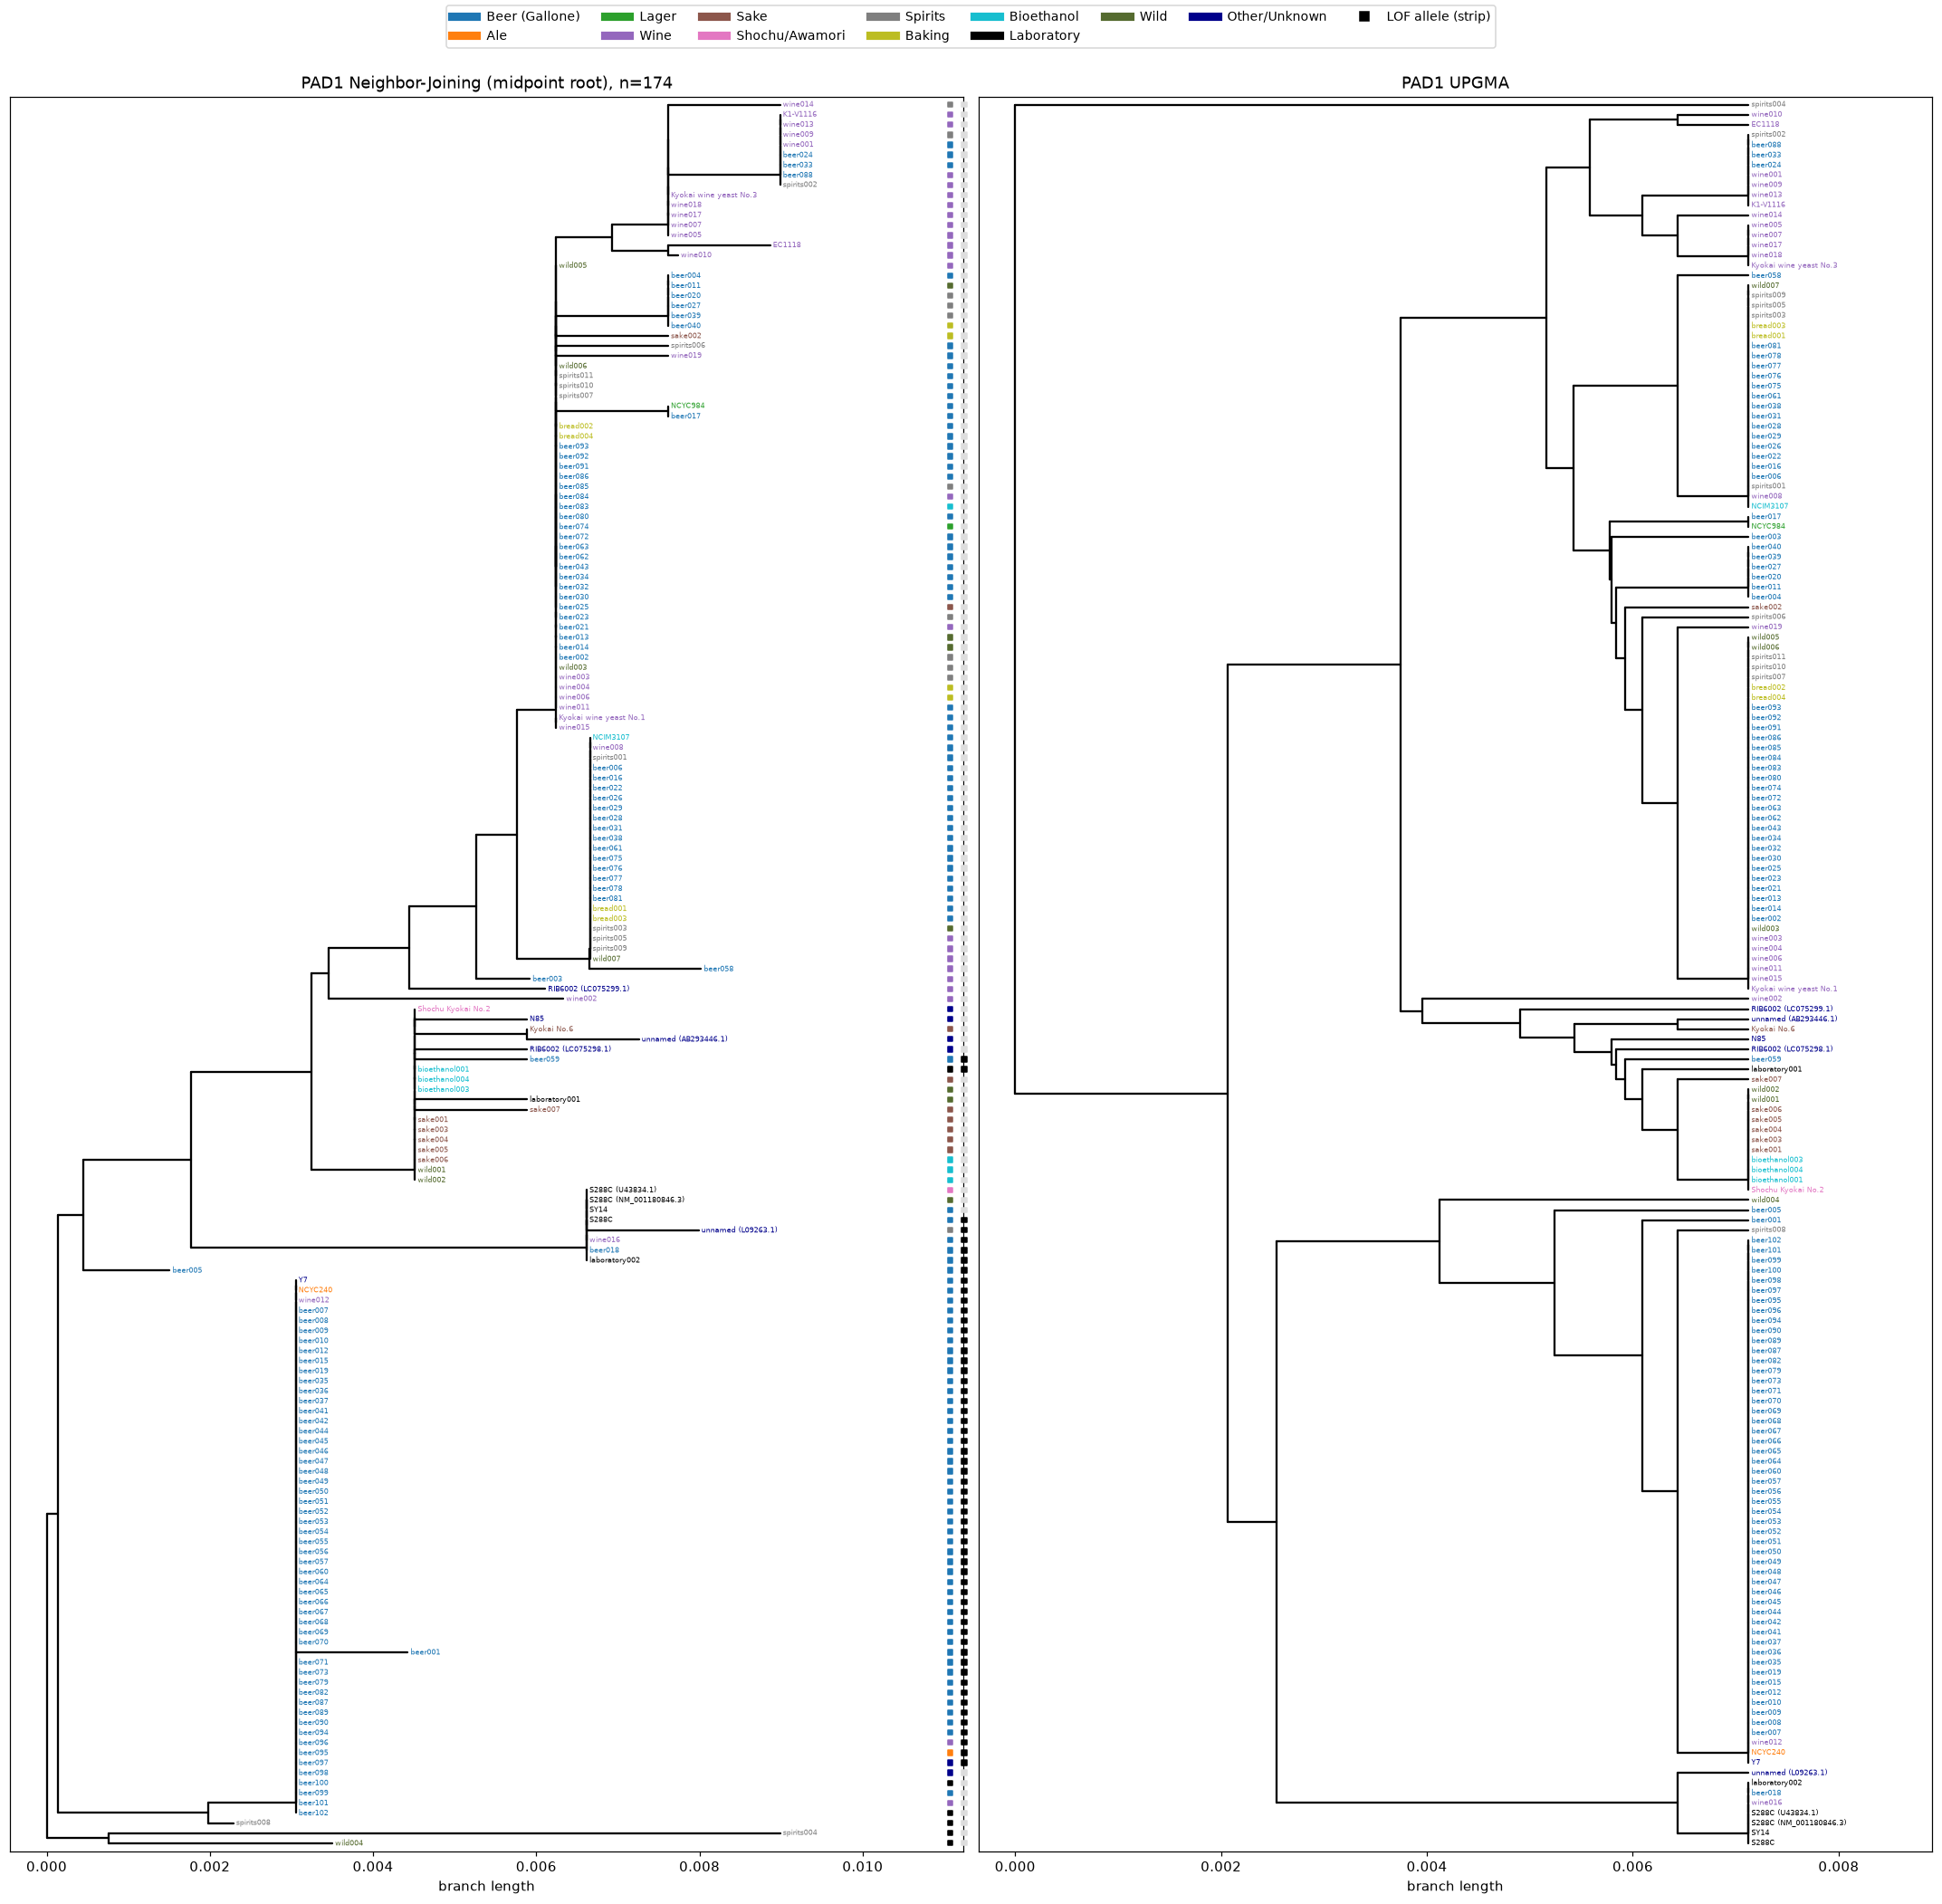

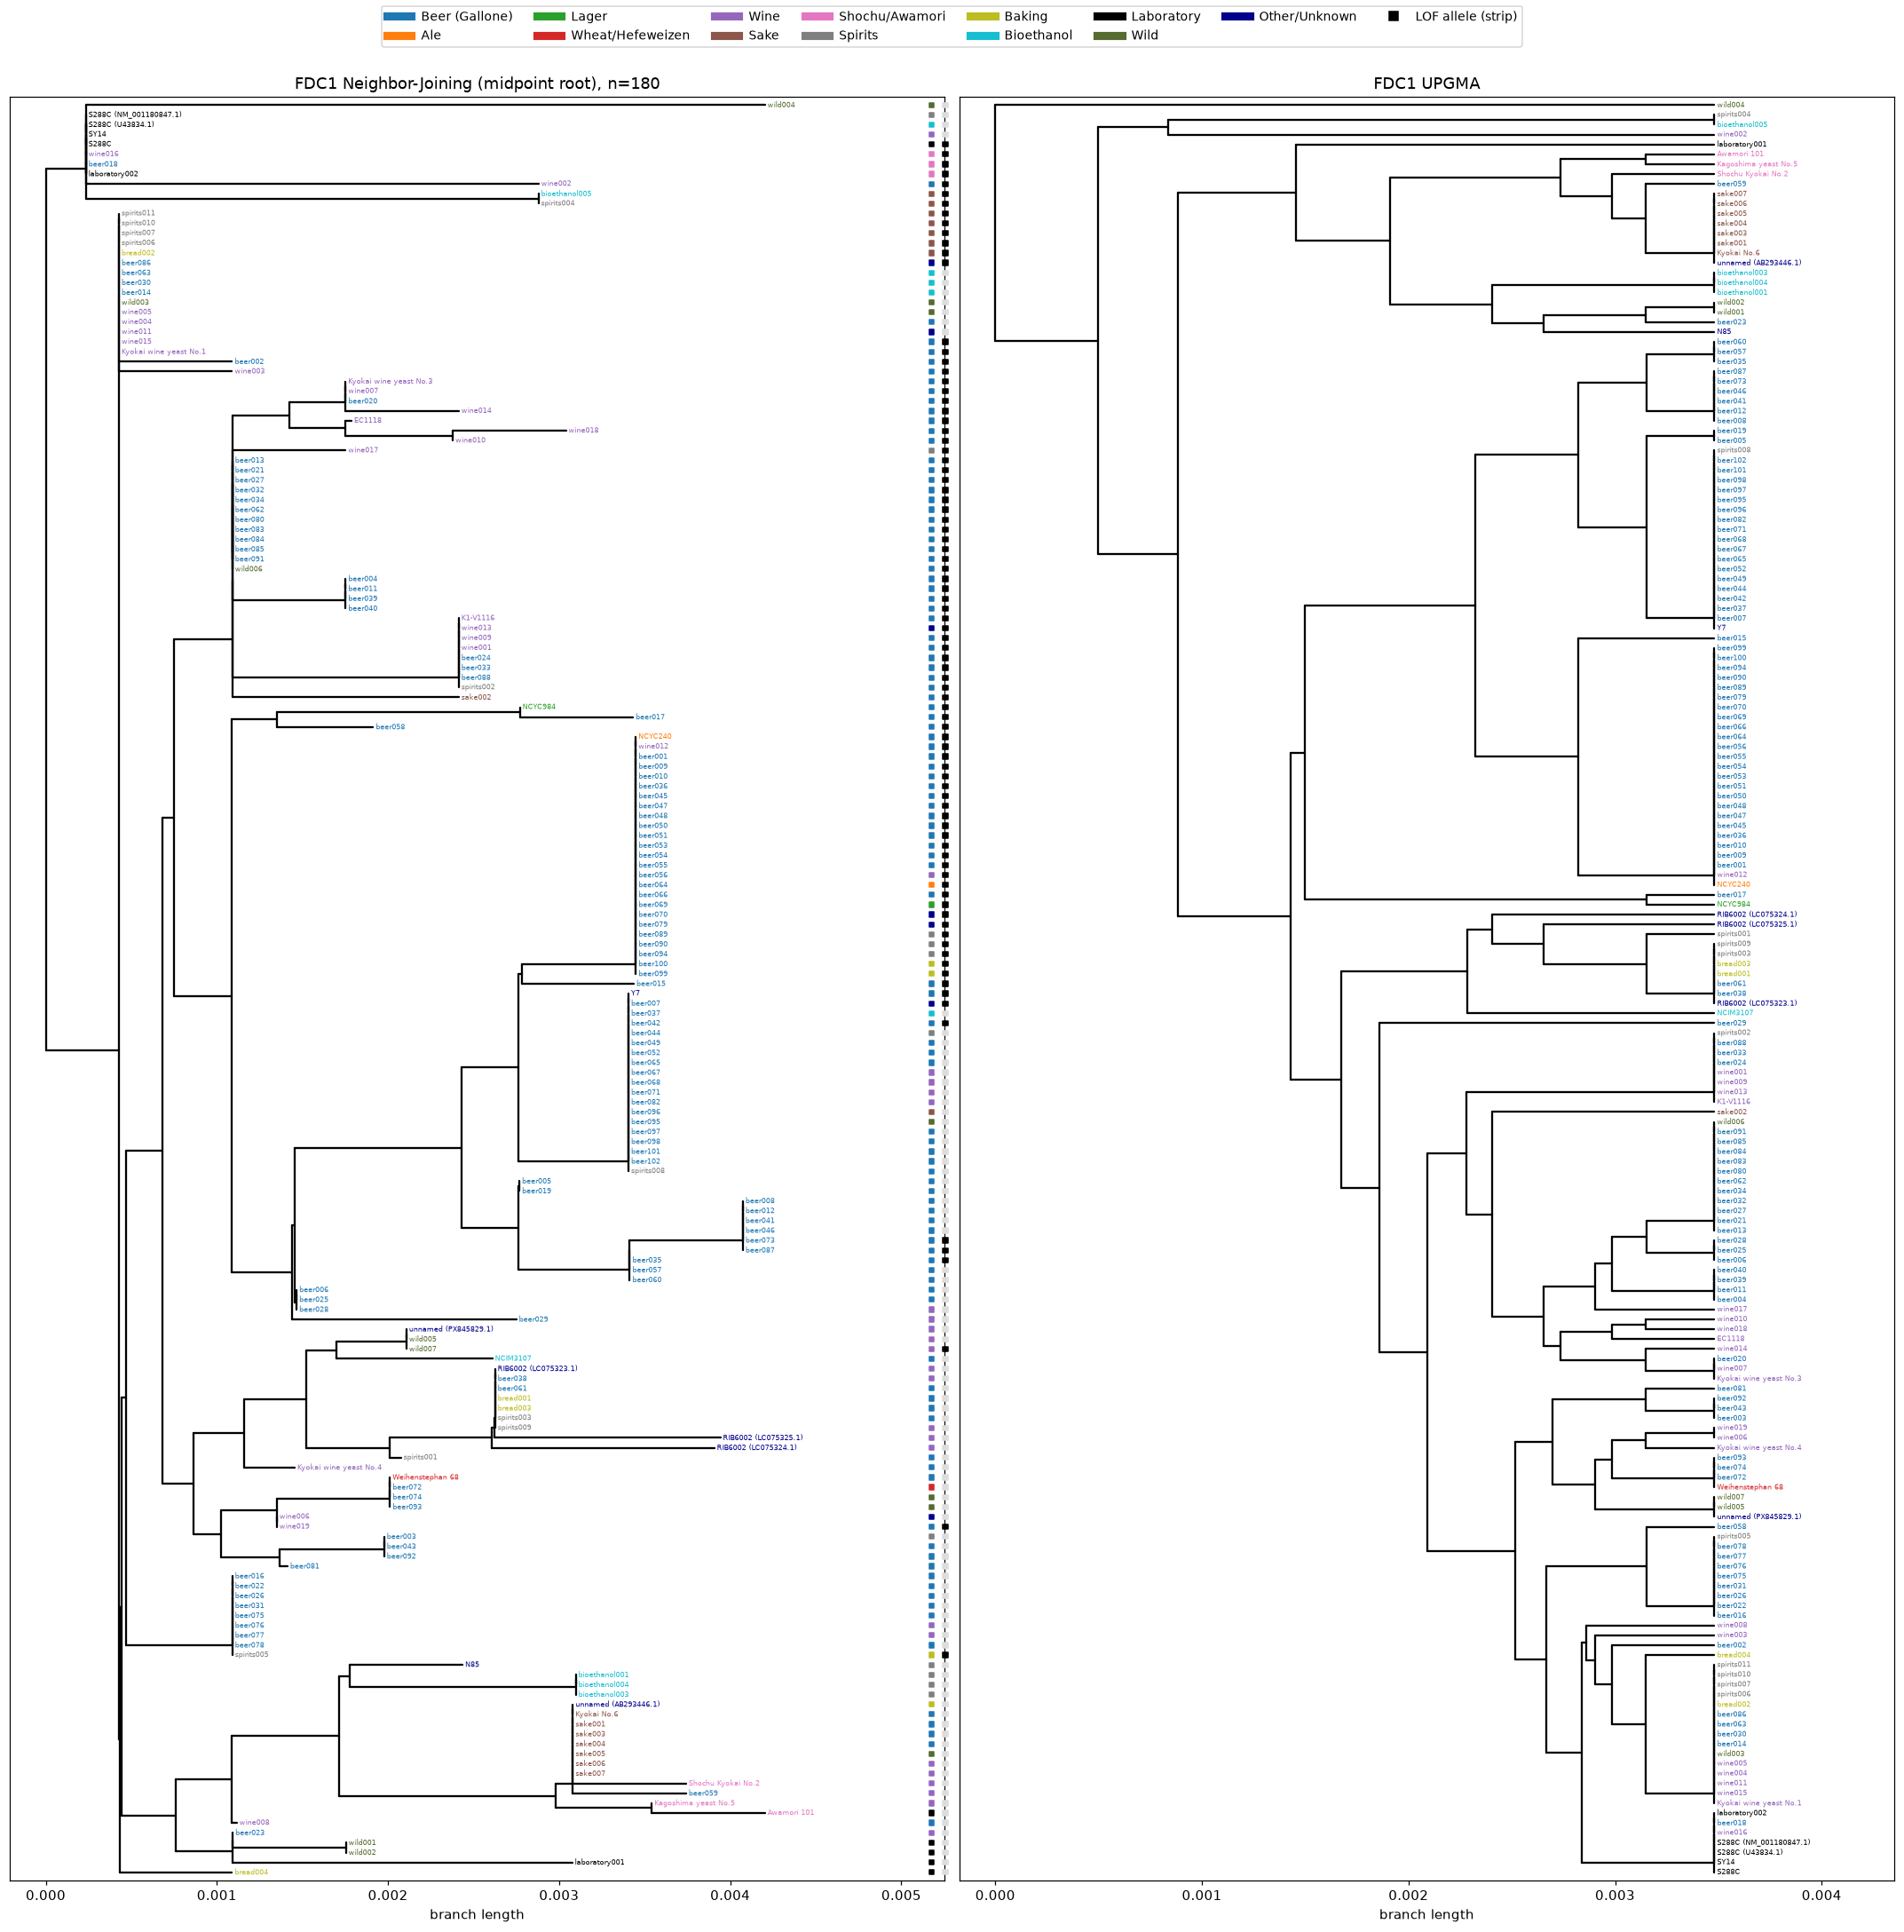

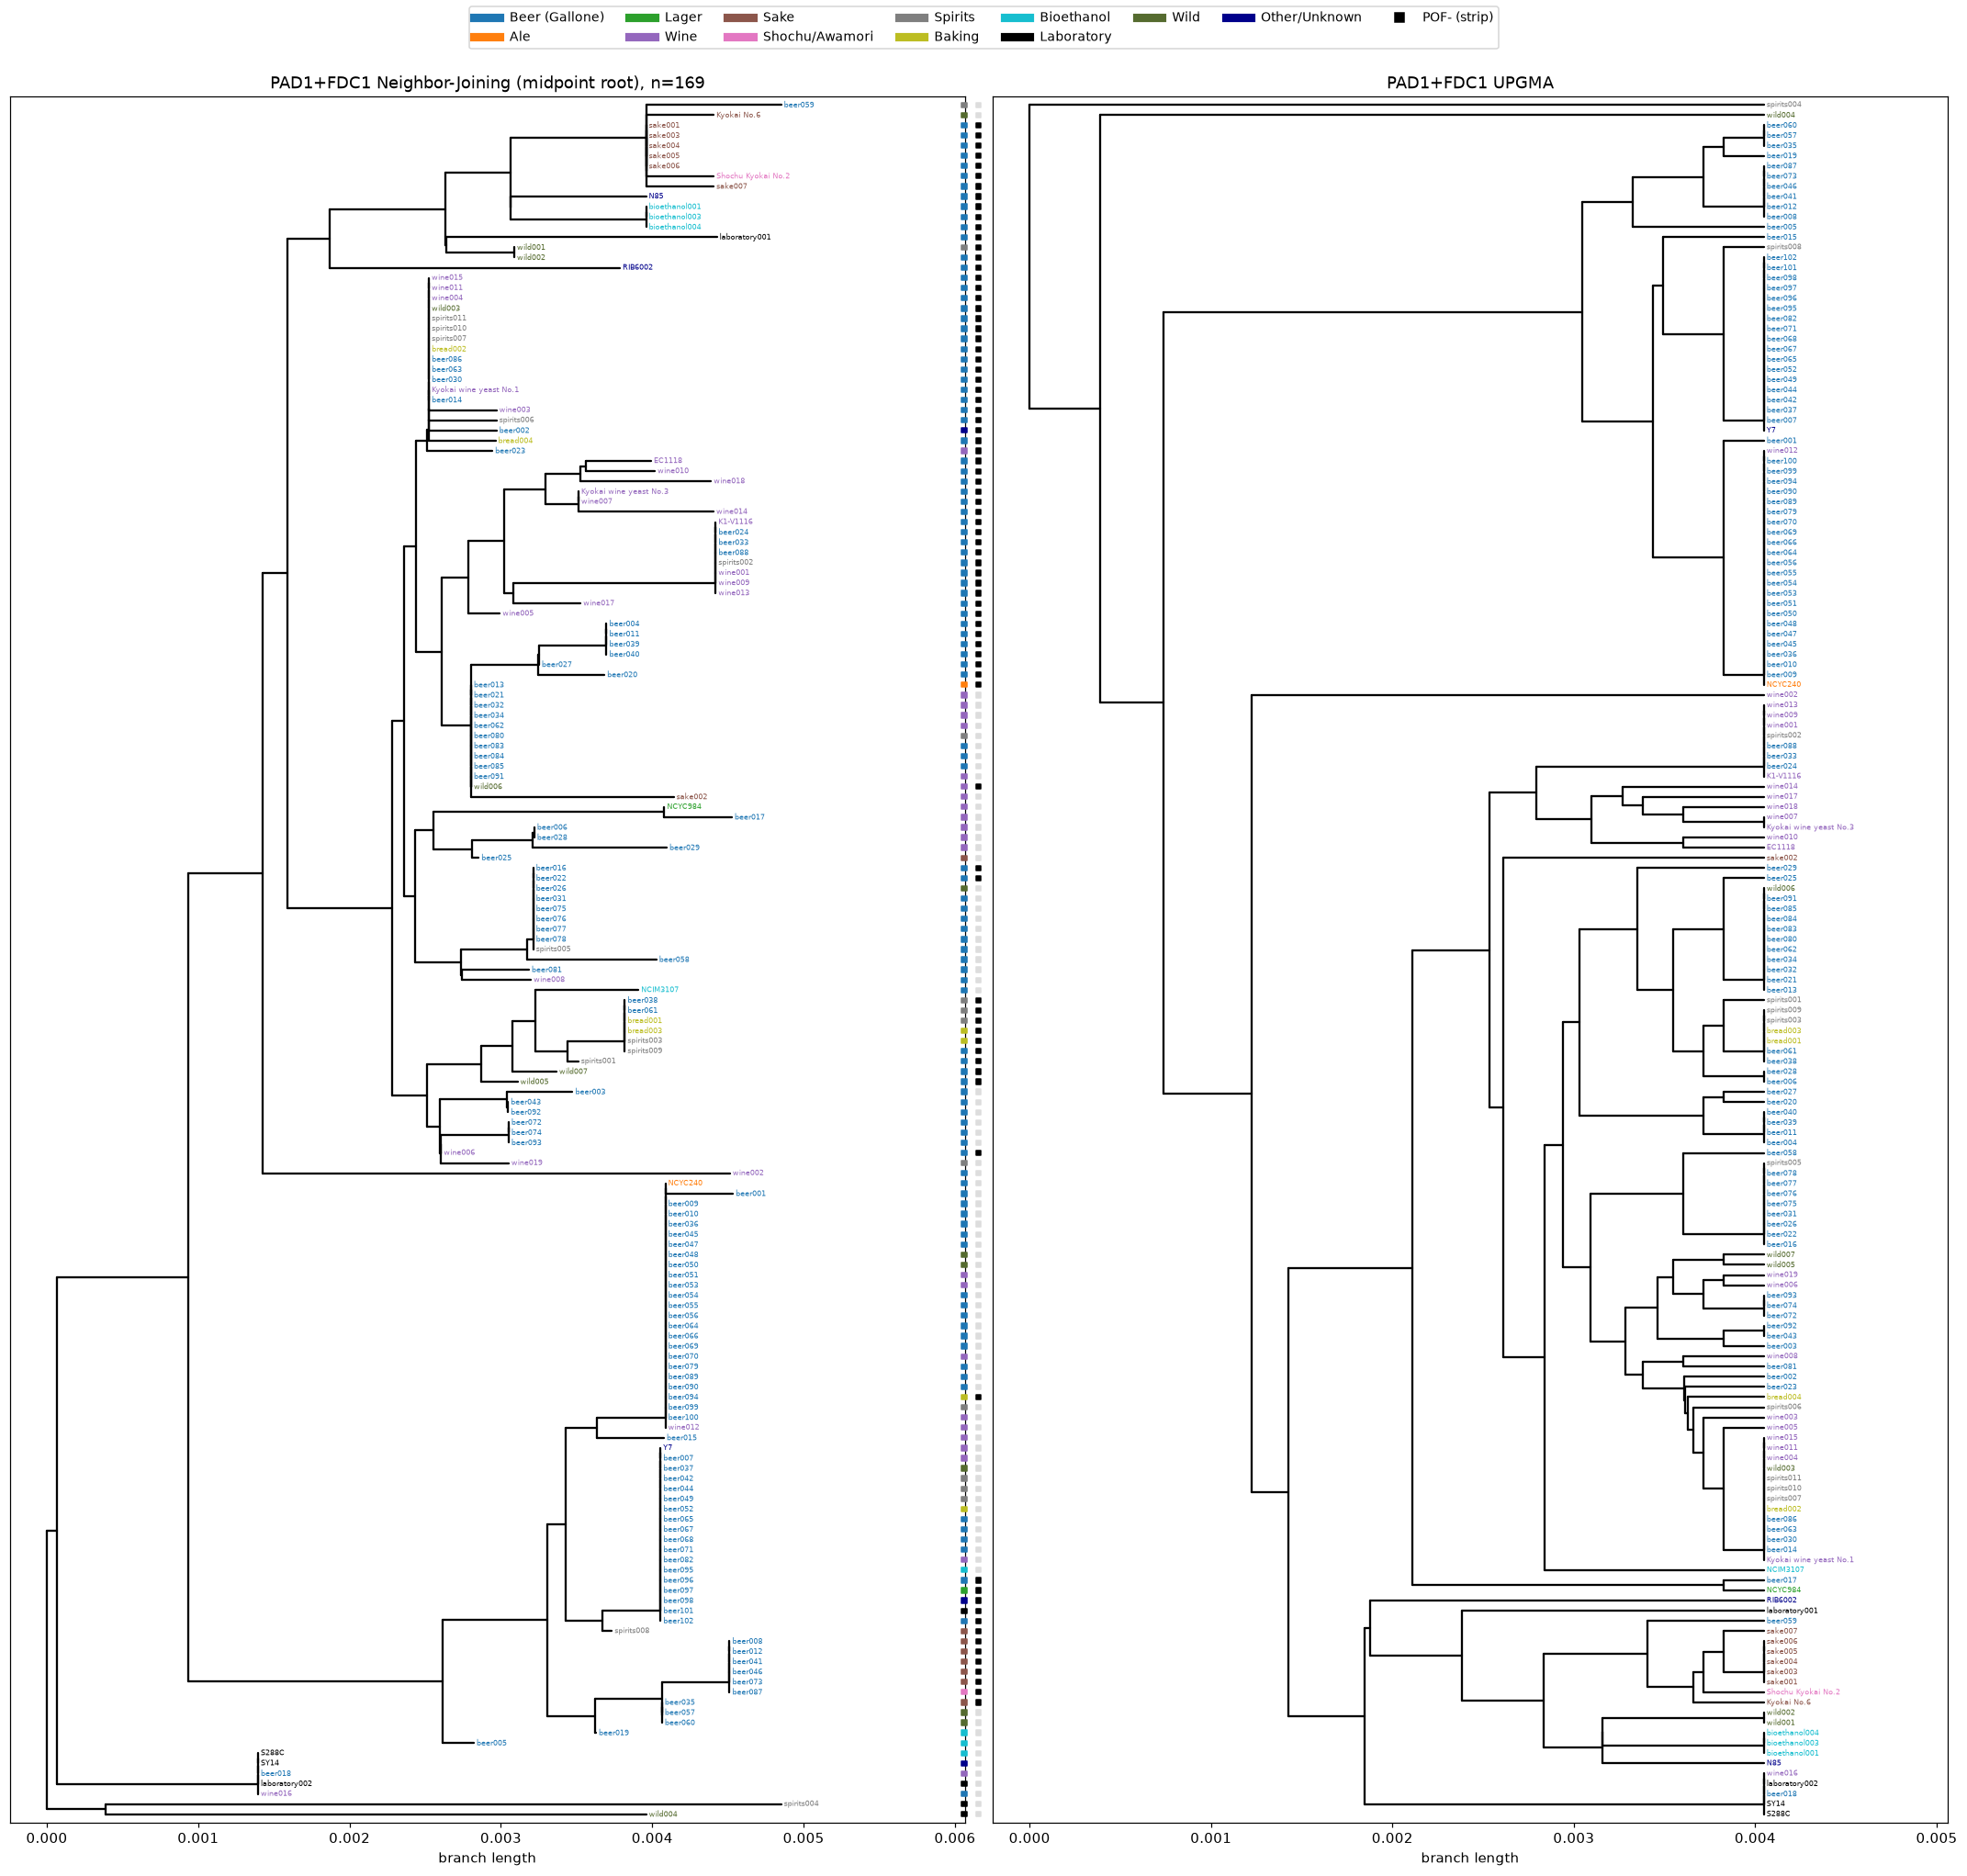

In [29]:
# 4d. Phylogeny: Neighbor-Joining and UPGMA
def draw(tree, gene, ax, title, fs=5):
    names = {x: label(gene, x) for x in alleles[gene]}
    cols = {names[x]: PALETTE[info[gene, x].group] for x in alleles[gene]}
    Phylo.draw(tree, label_func=lambda c: names.get(c.name, c.name) if c.is_terminal() else "",
               label_colors=lambda s: cols.get(s, "grey"), axes=ax, do_show=False)
    for t in ax.texts: t.set_fontsize(fs)
    tr = mtransforms.blended_transform_factory(ax.transAxes, ax.transData)
    for y, cl in enumerate(tree.get_terminals(), start=1):   # Phylo.draw puts terminal i at y = i + 1
        r = info[gene, cl.name]
        dark = (r.POF == "POF-") if gene == "PAD1_FDC1" else r.LOF
        ax.scatter([-0.03, -0.015], [y, y], c=[PALETTE[r.group], "#000000" if dark else "#dddddd"],
                   marker="s", s=12, transform=tr, clip_on=False)
    ax.set_title(title); ax.set_ylabel(""); ax.set_yticks([])

trees = {}
for gene, msa in msas.items():
    dm, nj, up = build_trees(msa)
    trees[gene] = dict(dm=dm, nj=nj, up=up)
    Phylo.write(nj, f"data/results/{gene}_nj.nwk", "newick")
    Phylo.write(up, f"data/results/{gene}_upgma.nwk", "newick")
    n = len(msa)
    fig, axs = plt.subplots(1, 2, figsize=(20, max(8, 0.11 * n)))
    draw(nj, gene, axs[0], f"{gene.replace('_', '+')} Neighbor-Joining (midpoint root), n={n}")
    draw(up, gene, axs[1], f"{gene.replace('_', '+')} UPGMA")
    present = [g for g in GROUPS if any(info[gene, x].group == g for x in alleles[gene])]
    fig.legend(handles=[plt.Line2D([], [], color=PALETTE[g], lw=6, label=g) for g in present]
               + [plt.Line2D([], [], color="k", marker="s", lw=0, label="POF- (strip)" if gene == "PAD1_FDC1" else "LOF allele (strip)")],
               loc="upper center", ncol=8, fontsize=9)
    fig.tight_layout(rect=(0.02, 0, 1, 0.97))
    fig.savefig(f"figures/tree_{gene}.png", dpi=150); plt.show()

61 haplotypes; 7 clades with >= 70% bootstrap support
  74%: 2 haplotypes, 2 strains: {'Spirits': 1, 'Wild': 1}; POF {'POF+': 2}
  78%: 9 haplotypes, 16 strains: {'Sake': 7, 'Bioethanol': 3, 'Wild': 2, 'Other/Unknown': 1, 'Shochu/Awamori': 1, 'Beer (Gallone)': 1, 'Laboratory': 1}; POF {'POF-': 10, 'POF+': 6}
  89%: 5 haplotypes, 9 strains: {'Sake': 7, 'Shochu/Awamori': 1, 'Beer (Gallone)': 1}; POF {'POF-': 9}
  100%: 2 haplotypes, 14 strains: {'Wine': 5, 'Beer (Gallone)': 4, 'Spirits': 3, 'Baking': 1, 'Wild': 1}; POF {'POF+': 14}
  100%: 2 haplotypes, 2 strains: {'Lager': 1, 'Beer (Gallone)': 1}; POF {'POF-': 2}
  91%: 9 haplotypes, 56 strains: {'Beer (Gallone)': 52, 'Ale': 1, 'Other/Unknown': 1, 'Spirits': 1, 'Wine': 1}; POF {'POF-': 56}
  90%: 2 haplotypes, 25 strains: {'Beer (Gallone)': 23, 'Ale': 1, 'Wine': 1}; POF {'POF-': 25}


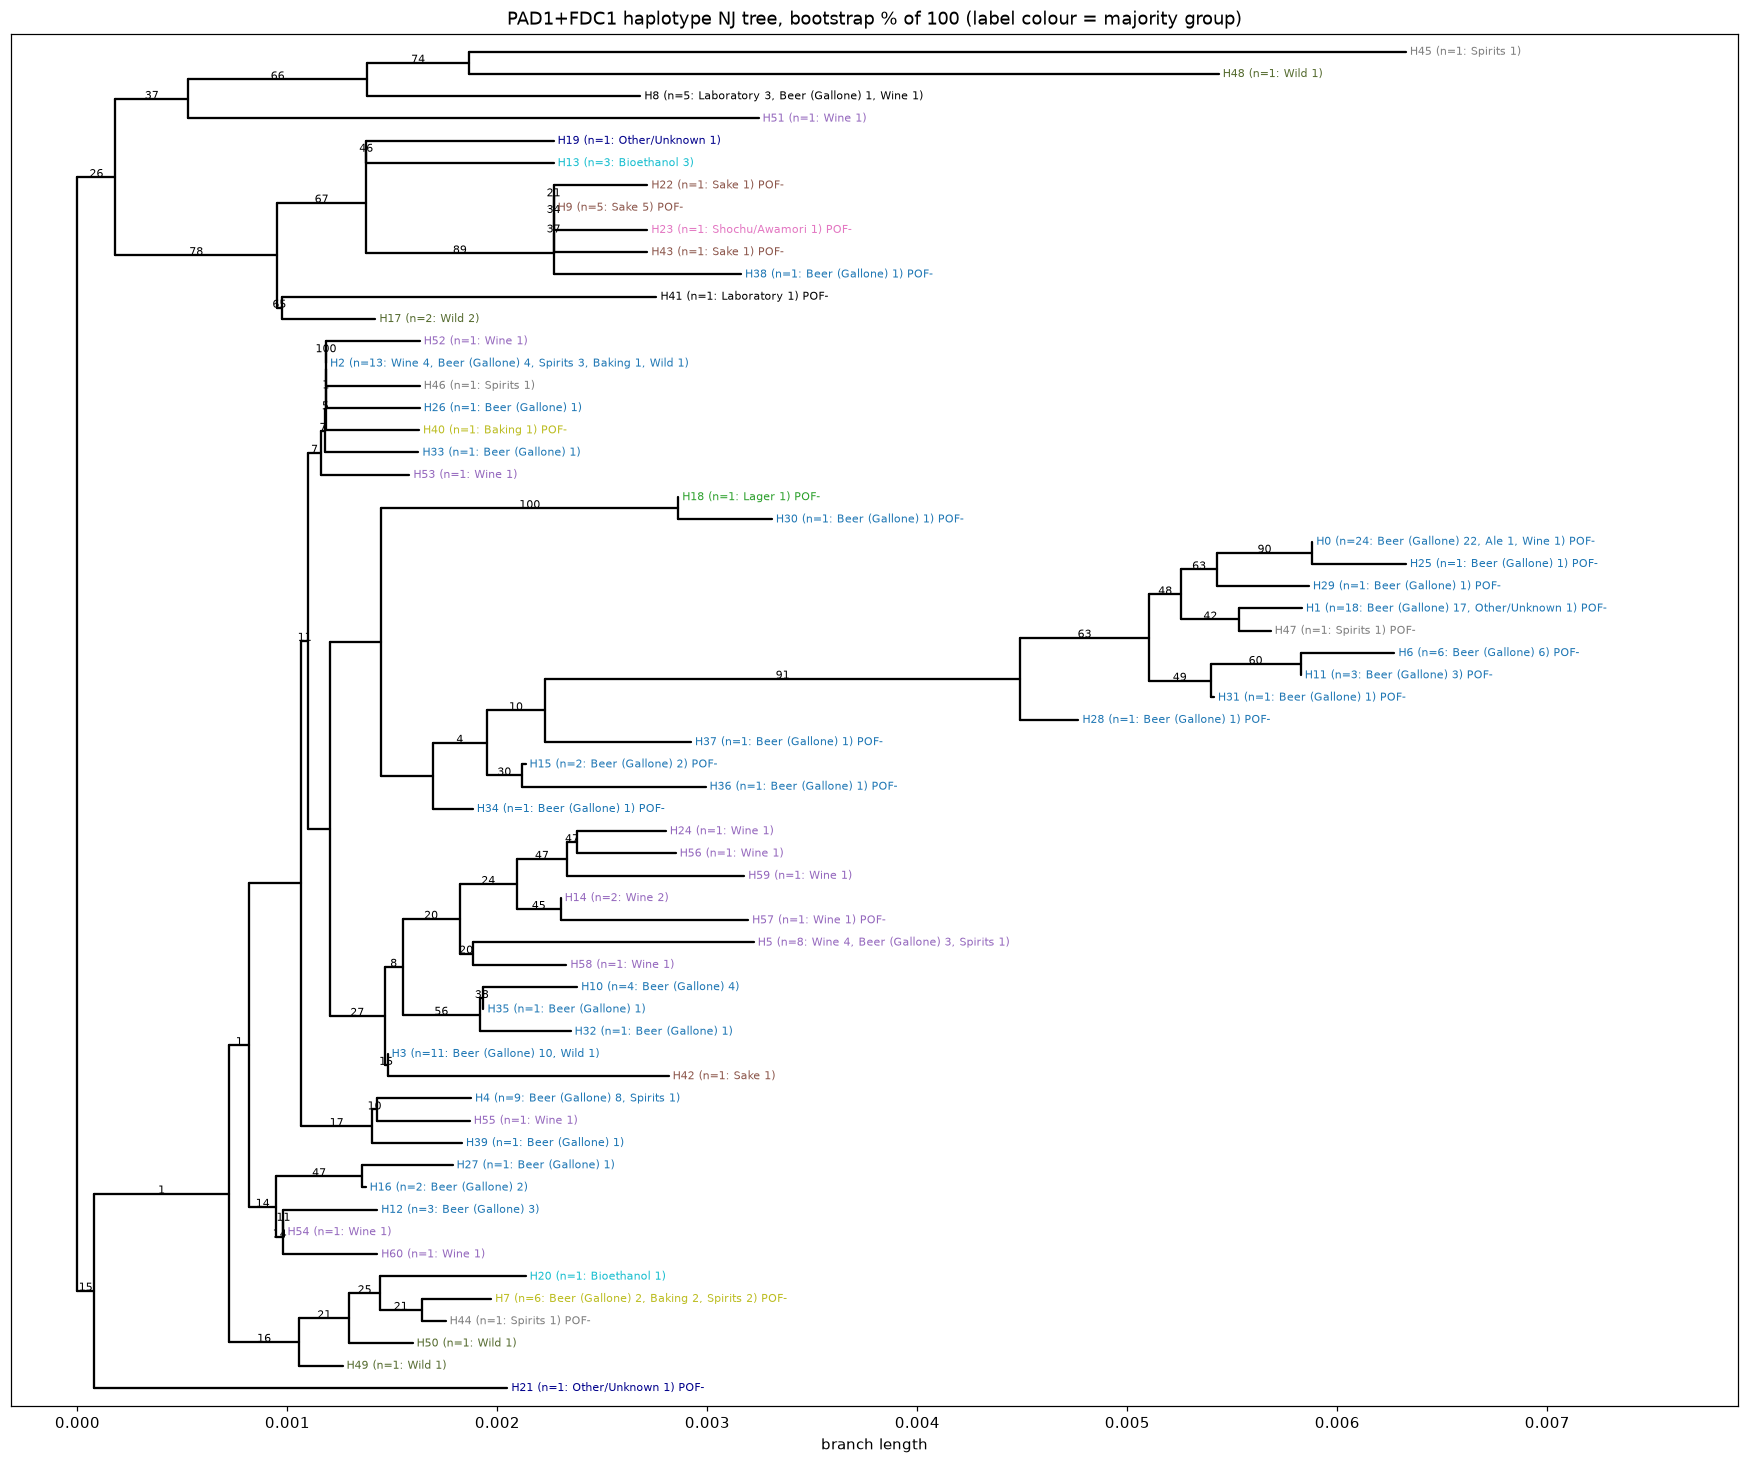

In [30]:
# Haplotype NJ tree with bootstrap support (concatenated PAD1+FDC1)
gene = "PAD1_FDC1"
h = haps[gene]
rep = h.drop_duplicates("haplotype").set_index("haplotype").sacc          # one representative per haplotype
A = msa_array(msas[gene])
idx = {r.id: i for i, r in enumerate(msas[gene])}
Ah = A[[idx[s] for s in rep]]
hn = [f"H{k}" for k in rep.index]
nj_h = DistanceTreeConstructor().nj(to_dm(hn, p_distance(Ah)))
reps = [DistanceTreeConstructor().nj(to_dm(hn, p_distance(Ah[:, rng.integers(0, Ah.shape[1], Ah.shape[1])])))
        for _ in range(N_BOOT)]
nj_h = get_support(nj_h, reps)                     # confidence = % of replicates containing the clade
nj_h.root_at_midpoint()
for cl in nj_h.get_nonterminals(): cl.name = None
Phylo.write(nj_h, f"data/results/{gene}_haplotype_nj_bootstrap.nwk", "newick")

def hap_label(name):
    k = int(name[1:]); sub = h[h.haplotype == k]
    comp = ", ".join(f"{g} {c}" for g, c in sub.group.value_counts().items())
    pofs = sub.POF.value_counts().to_dict()
    return f"{name} (n={len(sub)}: {comp}) {'POF-' if pofs.get('POF-', 0) == len(sub) else ''}"
major = lambda name: PALETTE[h[h.haplotype == int(name[1:])].group.mode()[0]]
fig, ax = plt.subplots(figsize=(16, max(8, 0.22 * len(hn))))
Phylo.draw(nj_h, label_func=lambda c: hap_label(c.name) if c.is_terminal() else "",
           label_colors=lambda s: major(s.split()[0]) if s.startswith("H") else "grey", axes=ax, do_show=False)
for t in ax.texts: t.set_fontsize(7)
ax.set_title(f"PAD1+FDC1 haplotype NJ tree, bootstrap % of {N_BOOT} (label colour = majority group)")
ax.set_yticks([]); ax.set_ylabel("")
fig.tight_layout(); fig.savefig("figures/tree_haplotypes_PAD1_FDC1_bootstrap.png", dpi=150); plt.show()
strong = [c for c in nj_h.get_nonterminals() if c.confidence is not None and c.confidence >= 70]
print(f"{len(hn)} haplotypes; {len(strong)} clades with >= 70% bootstrap support")
for c in strong:
    ks = [int(t.name[1:]) for t in c.get_terminals()]
    if len(ks) < len(hn):
        sub = h[h.haplotype.isin(ks)]
        print(f"  {c.confidence:.0f}%: {len(ks)} haplotypes, {len(sub)} strains: {sub.group.value_counts().to_dict()}; POF {sub.POF.value_counts().to_dict()}")

In [31]:
# 4e. Where do the 'off-group' strains fall?
gene = "PAD1_FDC1"
M = ident[gene]; L = msas[gene].get_alignment_length()
for q in ["laboratory001", "wine012", "wine014", "sake002", "bioethanol002", "Y7", "RIB6002", "N85"]:
    hits = [x for x in M.index if info[gene, x].strain == q] or [x for x in alleles["FDC1"] if info["FDC1", x].strain == q]
    if not hits:
        o = [(g, x) for g, x in outliers if info[g, x].strain == q]
        for g, x in o:
            d = (100 - outliers[g, x]).sort_values()
            print(f"{q} [{info[g, x].group}; {info[g, x].POF}] ({g}) EXCLUDED as divergent: median identity "
                  f"{outliers[g, x].median():.2f}%, closest {info[g, d.index[0]].strain} at {100 - d.iloc[0]:.2f}%")
        if not o: print(f"{q}: not in the data")
        continue
    x = hits[0]
    if x not in M.index:   # not paired -> use FDC1 alone
        gx, Mx = "FDC1", ident["FDC1"]
    else: gx, Mx = gene, M
    r = info[gx, x]
    d = ((100 - Mx.loc[x].drop(x)) / 100 * msas[gx].get_alignment_length()).round().astype(int).sort_values()
    nn = ", ".join(f"{info[gx, y].strain} [{info[gx, y].group}, {info[gx, y].POF}] {v}" for y, v in d.head(5).items())
    print(f"{q} [{r.group}; {r.POF}; {r.LOF_allele or 'intact'}] ({gx}, haplotype H{haps[gx].set_index('sacc').haplotype[x]}, "
          f"{Mx.loc[x].drop(x).median():.2f}% median identity to others)\n    nearest (diffs): {nn}")

laboratory001 [Laboratory; POF-; c.294T>G p.Y98* -> 97 aa + c.864delA p.G288fs -> 305 aa] (PAD1_FDC1, haplotype H41, 99.49% median identity to others)
    nearest (diffs): wild001 [Wild, POF+] 5, wild002 [Wild, POF+] 5, N85 [Other/Unknown, POF+] 7, beer023 [Beer (Gallone), POF+] 7, bioethanol004 [Bioethanol, POF+] 7
wine012 [Wine; POF-; c.305G>A p.W102* -> 101 aa + c.460C>T p.Q154*; c.501dupA p.K167fs -> 153 aa] (PAD1_FDC1, haplotype H0, 99.46% median identity to others)
    nearest (diffs): NCYC240 [Ale, POF-] 0, beer009 [Beer (Gallone), POF-] 0, beer010 [Beer (Gallone), POF-] 0, beer036 [Beer (Gallone), POF-] 0, beer047 [Beer (Gallone), POF-] 0
wine014 [Wine; POF-; c.925A>T p.R309* -> 308 aa] (PAD1_FDC1, haplotype H57, 99.62% median identity to others)
    nearest (diffs): Kyokai wine yeast No.3 [Wine, POF+] 2, wine007 [Wine, POF+] 2, beer021 [Beer (Gallone), POF+] 4, beer013 [Beer (Gallone), POF+] 4, beer034 [Beer (Gallone), POF+] 4
sake002 [Sake; POF+; intact] (PAD1_FDC1, haplotype

PCA explained variance (first 5): [46.6 12.7  5.5  4.7  4.6] %
best k = 15, silhouette = 0.77; ARI(kmeans vs group) = 0.09; ARI(kmeans vs POF, n=169) = 0.16
 k  silhouette  ARI_group  ARI_POF
 2        0.53      -0.05     0.46
 3        0.54       0.15     0.44
 4        0.53       0.17     0.38
 5        0.58       0.05     0.32
 6        0.54       0.10     0.40
 7        0.56       0.10     0.26
 8        0.61       0.10     0.23
 9        0.67       0.10     0.20
10        0.72       0.07     0.17
11        0.73       0.07     0.17
12        0.75       0.08     0.16
13        0.76       0.08     0.15
14        0.77       0.09     0.16
15        0.77       0.09     0.16
kmeans          0   1   2   3   4   5   6   7   8   9   10  11  12  13  14
group                                                                     
Ale              0   1   0   0   0   0   0   0   0   0   0   0   0   0   0
Baking           2   0   0   0   2   0   0   0   0   0   0   0   0   0   0
Beer (Gallone)   6

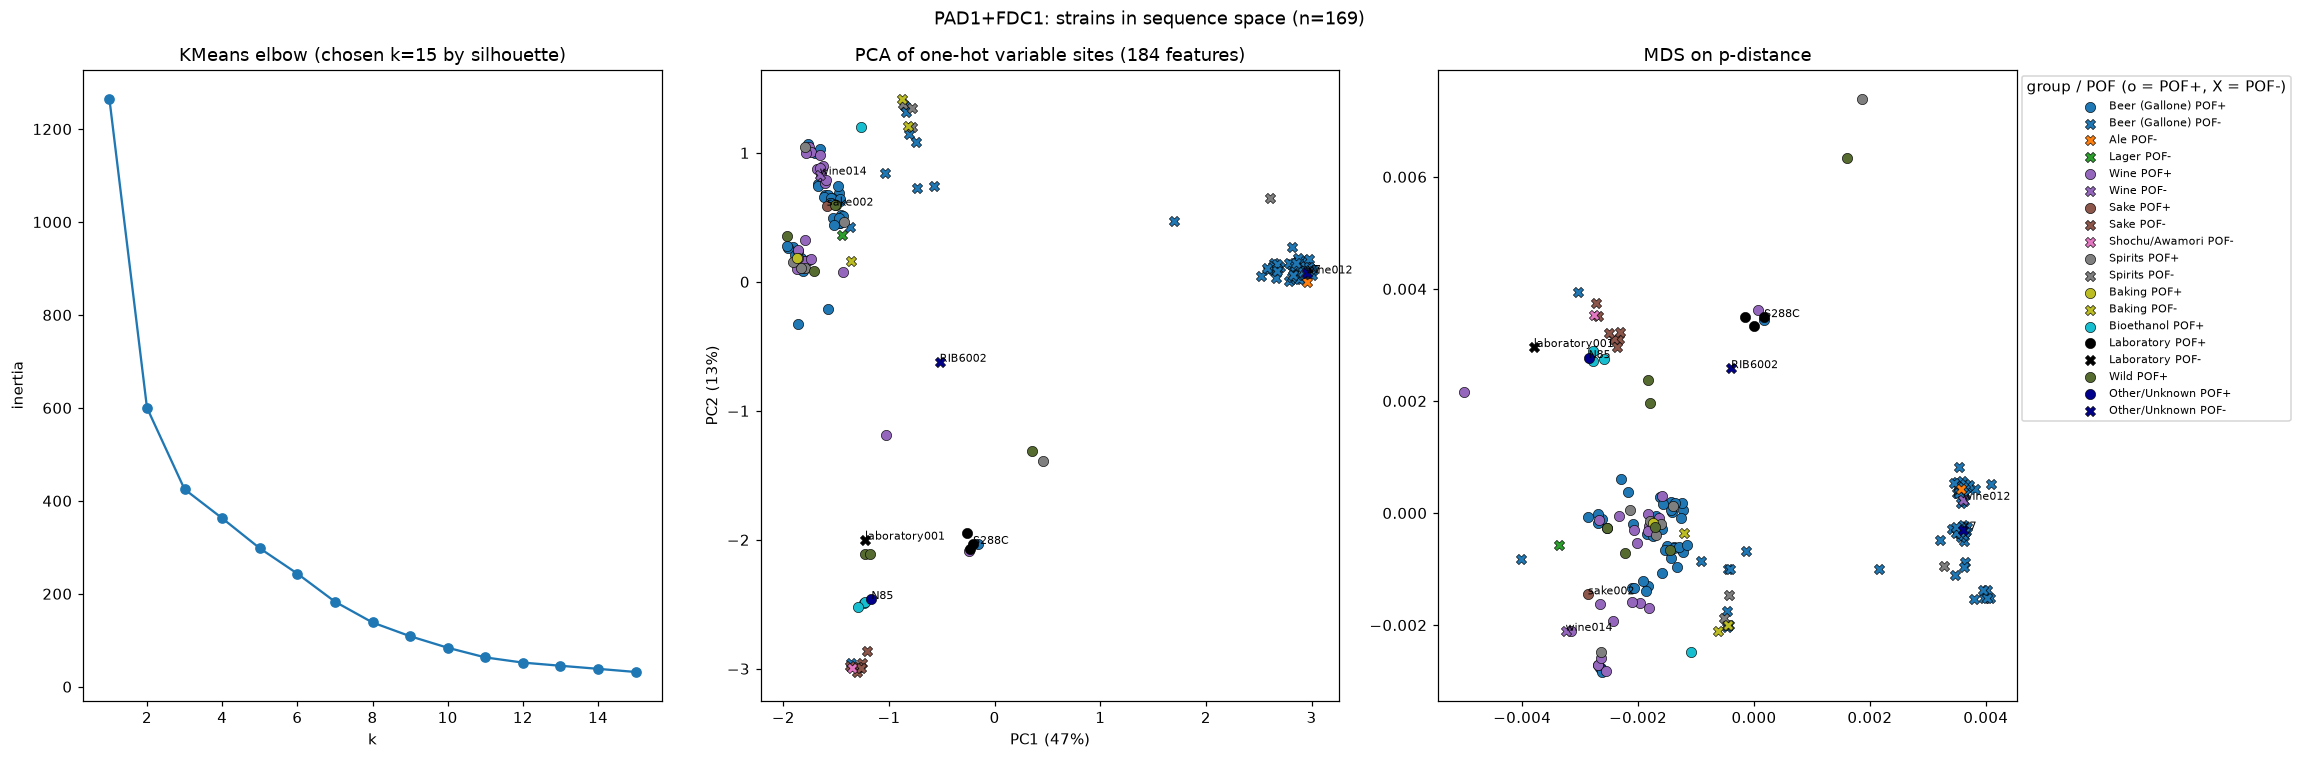

In [32]:
# 4f. Dimensionality reduction and KMeans
gene = "PAD1_FDC1"
X = one_hot_variable(msas[gene])
names = list(X.index)
grp = [info[gene, x].group for x in names]
pofs = [info[gene, x].POF for x in names]
nc = min(10, X.shape[0] - 1, X.shape[1])
pca = PCA(n_components=nc).fit(X.values)
P = pca.transform(X.values)
Mds = MDS(n_components=2, metric="precomputed", init="classical_mds", random_state=0).fit_transform(
    1 - ident[gene].loc[names, names].values / 100)

ks = range(1, min(15, len(set(map(tuple, X.values)))) + 1)
fits = {k: KMeans(k, n_init=10, random_state=0).fit(P) for k in ks}
inertia = [fits[k].inertia_ for k in ks]
sil = {k: silhouette_score(P, fits[k].labels_) for k in ks if 1 < k < len(names)}
best_k = max(sil, key=sil.get) if sil else 1
km = fits[best_k].labels_
known = [i for i, v in enumerate(pofs) if v != "?"]
ari_g = adjusted_rand_score(grp, km)
ari_p = adjusted_rand_score([pofs[i] for i in known], km[known])

fig, axs = plt.subplots(1, 3, figsize=(21, 7))
axs[0].plot(list(ks), inertia, "o-"); axs[0].set(xlabel="k", ylabel="inertia", title=f"KMeans elbow (chosen k={best_k} by silhouette)")
for ax, Y, t in [(axs[1], P[:, :2], f"PCA of one-hot variable sites ({X.shape[1]} features)"), (axs[2], Mds, "MDS on p-distance")]:
    jit = rng.normal(0, 0.01 * (np.ptp(Y, axis=0) + 1e-9), Y.shape)   # identical haplotypes overlap
    for g in [g for g in GROUPS if g in grp]:
        for pv, mk in [("POF+", "o"), ("POF-", "X"), ("?", "s")]:
            i = [n for n in range(len(names)) if grp[n] == g and pofs[n] == pv]
            if i: ax.scatter(Y[i, 0] + jit[i, 0], Y[i, 1] + jit[i, 1], c=PALETTE[g], marker=mk, s=45, edgecolor="k",
                             linewidth=0.4, label=f"{g} {pv}")
    for n, x in enumerate(names):
        if info[gene, x].strain in ["laboratory001", "wine012", "wine014", "sake002", "bioethanol002", "Y7", "RIB6002", "N85", "S288C"]:
            ax.annotate(info[gene, x].strain, Y[n] + jit[n], fontsize=7)
    ax.set_title(t)
ev = pca.explained_variance_ratio_
axs[1].set(xlabel=f"PC1 ({100 * ev[0]:.0f}%)", ylabel=f"PC2 ({100 * ev[1]:.0f}%)")
axs[2].legend(fontsize=7, title="group / POF (o = POF+, X = POF-)", bbox_to_anchor=(1, 1), ncol=1)
fig.suptitle(f"PAD1+FDC1: strains in sequence space (n={len(names)})"); fig.tight_layout()
fig.savefig(f"figures/pca_mds_kmeans_{gene}.png", dpi=150); plt.show()

clusters = pd.DataFrame({"sacc": names, "strain": [info[gene, x].strain for x in names], "group": grp, "POF": pofs,
                         "LOF_allele": [info[gene, x].LOF_allele for x in names], "kmeans": km, "PC1": P[:, 0], "PC2": P[:, 1]})
clusters.to_csv(f"data/results/{gene}_pca_kmeans.csv", index=False)
print(f"PCA explained variance (first 5): {np.round(100 * ev[:5], 1)} %")
print(f"best k = {best_k}, silhouette = {sil[best_k]:.2f}; ARI(kmeans vs group) = {ari_g:.2f}; "
      f"ARI(kmeans vs POF, n={len(known)}) = {ari_p:.2f}")
# silhouette keeps rising when points are discrete haplotypes, so show agreement for every k, not just the chosen one
print(pd.DataFrame([dict(k=k, silhouette=sil[k], ARI_group=adjusted_rand_score(grp, fits[k].labels_),
                         ARI_POF=adjusted_rand_score([pofs[i] for i in known], fits[k].labels_[known])) for k in sil]).round(2).to_string(index=False))
print(pd.crosstab(clusters.group, clusters.kmeans))
print(pd.crosstab(clusters.POF, clusters.kmeans))
print("\nLOF alleles per cluster (beer = 'Beer (Gallone)' + Ale/Lager/Wheat):")
beer = clusters[clusters.group.isin(["Beer (Gallone)", "Ale", "Lager", "Wheat/Hefeweizen"])]
print(pd.crosstab(beer.LOF_allele.replace("", "intact").str.replace(r" -> \d+ aa", "", regex=True), beer.kmeans).to_string())

                n MAL11         MAL31         MPH2_3         total_loci        
                   mean min max  mean min max   mean min max       mean min max
group                                                                          
Ale             1  1.00   1   1  1.00   1   1   0.00   0   0       2.00   2   2
Lager           2  2.00   2   2  3.50   2   5   0.50   0   1       6.00   5   7
Wine           10  0.50   0   1  1.70   1   3   1.00   0   2       3.20   2   5
Sake            1  1.00   1   1  3.00   3   3   1.00   1   1       5.00   5   5
Bioethanol      1  1.00   1   1  2.00   2   2   1.00   1   1       4.00   4   4
Laboratory      4  0.50   0   1  1.75   1   2   1.50   1   2       3.75   3   5
Wild            7  1.00   1   1  2.14   2   3   0.71   0   1       3.86   3   4
Clinical        4  0.25   0   1  2.25   1   4   0.75   0   1       3.25   1   6
Other/Unknown   6  0.50   0   1  2.83   1   6   0.83   0   2       4.17   1   7
         gene  domesticated_mean  domest

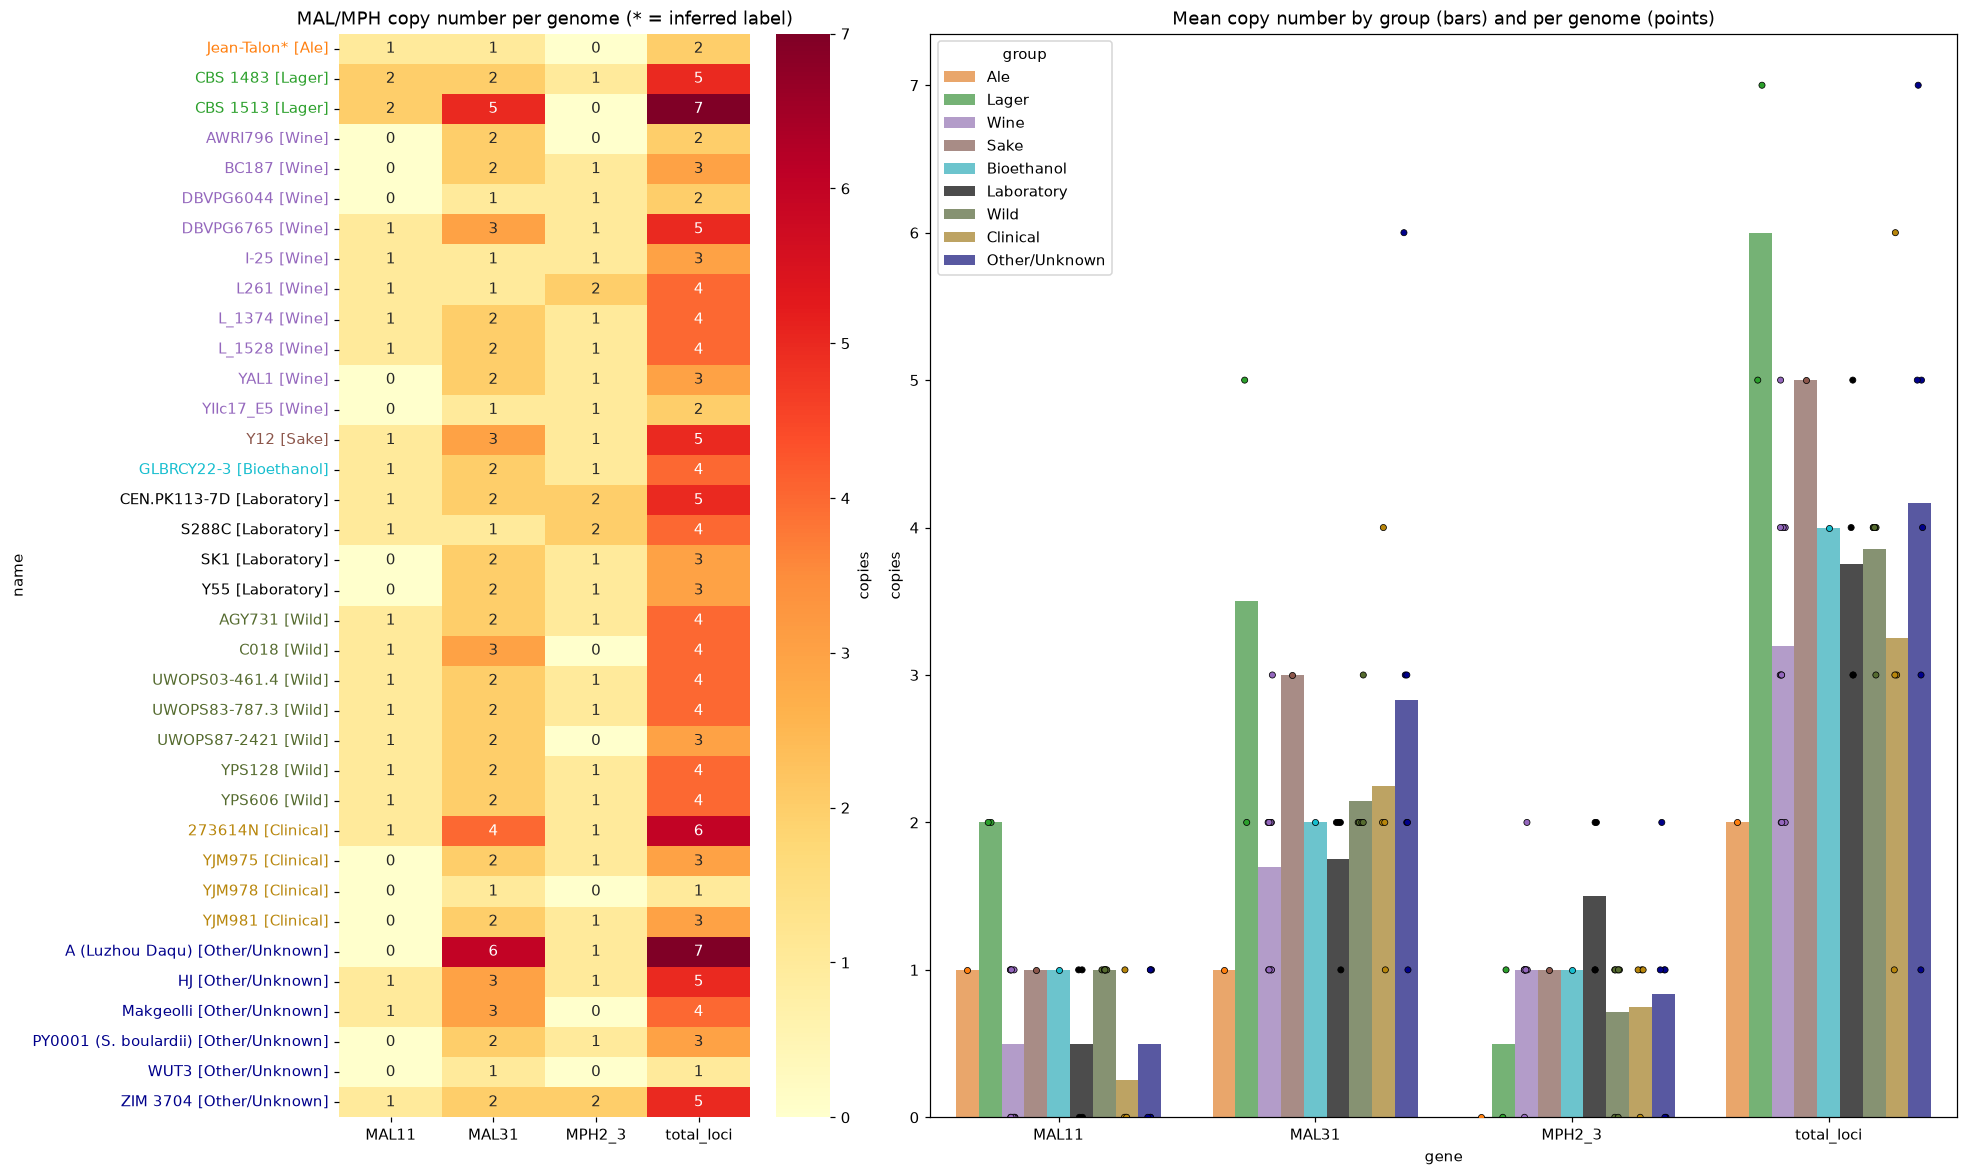

In [33]:
# 4g. MAL / MPH maltose-transporter copy number
cnv_path = "data/cnv/mal_copy_number.csv"
if os.path.exists(cnv_path):
    cnv = pd.read_csv(cnv_path)
    genes = [g for g in ["MAL11", "MAL31", "MPH2_3", "total_loci"] if g in cnv.columns]
    cnv["group"] = cnv.group.where(cnv.group.isin(PALETTE), "Other/Unknown")
    cnv["name"] = cnv.strain + np.where(cnv.strain == "Jean-Talon", "*", "") + " [" + cnv.group + "]"
    cnv = cnv.sort_values(["group", "strain"], key=lambda c: c.map(GROUPS.index) if c.name == "group" else c)
    H = cnv.set_index("name")[genes]
    fig, axs = plt.subplots(1, 2, figsize=(18, max(6, 0.3 * len(cnv))), gridspec_kw={"width_ratios": [1, 2]})
    sns.heatmap(H, annot=True, fmt="g", cmap="YlOrRd", ax=axs[0], cbar_kws={"label": "copies"})
    gcol = cnv.set_index("name").group
    for t in axs[0].get_yticklabels(): t.set_color(PALETTE[gcol[t.get_text()]])
    axs[0].set_title("MAL/MPH copy number per genome (* = inferred label)")
    long = cnv.melt(id_vars=["strain", "group"], value_vars=genes, var_name="gene", value_name="copies")
    order = [g for g in GROUPS if g in set(cnv.group)]
    sns.barplot(data=long, x="gene", y="copies", hue="group", hue_order=order, palette=PALETTE, ax=axs[1], errorbar=None, alpha=0.7)
    sns.stripplot(data=long, x="gene", y="copies", hue="group", hue_order=order, palette=PALETTE, dodge=True, ax=axs[1],
                  size=4, edgecolor="k", linewidth=0.5, legend=False)
    axs[1].set_title("Mean copy number by group (bars) and per genome (points)")
    fig.tight_layout(); fig.savefig("figures/mal_copy_number.png", dpi=150); plt.show()

    summary = cnv.groupby("group")[genes].agg(["mean", "min", "max"]).round(2)
    summary.insert(0, "n", cnv.groupby("group").size())
    print(summary.loc[order].to_string())
    dom = cnv.group.isin(["Beer (Gallone)", "Spirits", "Ale", "Lager", "Wheat/Hefeweizen", "Wine", "Sake", "Shochu/Awamori", "Baking", "Bioethanol"])
    wl = cnv.group.isin(["Wild", "Laboratory"])
    rows = []
    for g in genes:
        a, b = cnv.loc[dom, g], cnv.loc[wl, g]
        p = mannwhitneyu(a, b).pvalue if len(a) and len(b) and (a.nunique() + b.nunique() > 2) else np.nan
        rows.append(dict(gene=g, domesticated_mean=a.mean(), domesticated_median=a.median(), domesticated_n=len(a),
                         wild_lab_mean=b.mean(), wild_lab_median=b.median(), wild_lab_n=len(b), mannwhitney_p=p))
    cnv_test = pd.DataFrame(rows).round(3)
    cnv_test.to_csv("data/results/mal_cnv_comparison.csv", index=False)
    print(cnv_test.to_string())
    print("\nBeer genomes:"); print(cnv[cnv.group.isin(["Ale", "Lager"])][["name"] + genes].to_string(index=False))
else:
    print("data/cnv/mal_copy_number.csv not found - CNV section skipped")

In [34]:
# 5. Structural context of the PAD1 / FDC1 variants
import os, re, json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from Bio.PDB import PDBParser, NeighborSearch
from Bio.SeqUtils import seq1

S = "data/structure"; R = "data/results"; FIG = "figures"
for d in (S, R, FIG):
    os.makedirs(d, exist_ok=True)

FDC1_PDB = f"{S}/4ZAC_A_CA_het.pdb"
PAD1_PDB = f"{S}/AF-P33751-F1_CA.pdb"
FEAT = f"{S}/uniprot_features.json"

def fetch_if_missing():
    """Only runs when the cached files are absent (needs internet + requests)."""
    import requests
    if not os.path.exists(FDC1_PDB):
        txt = requests.get("https://files.rcsb.org/download/4ZAC.pdb", timeout=60).text
        keep = [l for l in txt.splitlines()
                if l.startswith(("HEADER", "REMARK   2 RES"))
                or (l.startswith("HELIX ") and l[19] == "A") or (l.startswith("SHEET ") and l[21] == "A")
                or (l.startswith("HETATM") and l[21] == "A" and l[17:20] != "HOH")
                or (l.startswith("ATOM") and l[21] == "A" and l[12:16] == " CA " and l[16] in " A")]
        open(FDC1_PDB, "w").write("\n".join(keep) + "\nEND\n")
    if not os.path.exists(PAD1_PDB):
        url = requests.get("https://alphafold.ebi.ac.uk/api/prediction/P33751", timeout=60).json()[0]["pdbUrl"]
        txt = requests.get(url, timeout=60).text
        keep = [l for l in txt.splitlines() if l.startswith("ATOM") and l[12:16] == " CA "]
        open(PAD1_PDB, "w").write("\n".join(keep) + "\nEND\n")
    if not os.path.exists(FEAT):
        out = {}
        for acc in ("Q03034", "P33751"):
            j = requests.get(f"https://rest.uniprot.org/uniprotkb/{acc}.json", timeout=60).json()
            ss = {"Helix", "Beta strand", "Turn"}
            pf = requests.get(f"https://www.ebi.ac.uk/interpro/api/entry/pfam/protein/uniprot/{acc}", timeout=60).json()
            out[acc] = {"gene": j["genes"][0]["geneName"]["value"], "length": j["sequence"]["length"],
                        "sequence": j["sequence"]["value"],
                        "features": [{"type": f["type"], "start": f["location"]["start"]["value"],
                                      "end": f["location"]["end"]["value"], "description": f.get("description", ""),
                                      "ligand": f.get("ligand", {}).get("name", "")}
                                     for f in j["features"] if f["type"] not in ss | {"Chain"}],
                        "pfam": [[r["metadata"]["accession"], r["metadata"]["name"], fr["start"], fr["end"]]
                                 for r in pf["results"] for loc in r["proteins"][0]["entry_protein_locations"]
                                 for fr in loc["fragments"]],
                        "secondary_structure": [[f["type"], f["location"]["start"]["value"], f["location"]["end"]["value"]]
                                                for f in j["features"] if f["type"] in ss]}
        json.dump(out, open(FEAT, "w"), indent=1)

if not all(os.path.exists(p) for p in (FDC1_PDB, PAD1_PDB, FEAT)):
    fetch_if_missing()

In [35]:
# 5a. Load structures and map UniProt features onto chain A
feat = json.load(open(FEAT))
UNI = {"FDC1": feat["Q03034"], "PAD1": feat["P33751"]}
parser = PDBParser(QUIET=True)

def load_chain(path):
    chain = parser.get_structure(os.path.basename(path), path)[0]["A"]
    prot = {r.id[1]: r for r in chain if r.id[0] == " " and "CA" in r}
    het = [a for r in chain if r.id[0].startswith("H_") for a in r]
    return prot, het

STRUCT = {"FDC1": load_chain(FDC1_PDB), "PAD1": load_chain(PAD1_PDB)}
for g, (prot, het) in STRUCT.items():
    seq = UNI[g]["sequence"]
    mism = [n for n, r in prot.items() if seq1(r.get_resname()) != seq[n - 1]]
    print(f"{g}: {len(prot)} residues with CA (UniProt length {len(seq)}), "
          f"{len(seq) - len(prot)} missing, {len(mism)} sequence mismatches; HETATM groups: "
          f"{sorted({a.get_parent().get_resname() for a in het})}")

prot_f, het_f = STRUCT["FDC1"]
prfmn = [a for a in het_f if a.get_parent().get_resname() == "4LU"]
mn = [a for a in het_f if a.get_parent().get_resname() == "MN"]
ACTIVE = {"FDC1": {175: "R175", 280: "E280", 285: "E285 (proton donor)"}}

def binding_sites(g):
    """[(resnum, label)] for UniProt binding/active sites."""
    out = []
    for f in UNI[g]["features"]:
        if f["type"] in ("Binding site", "Active site"):
            lab = f["ligand"] or f["description"]
            out += [(i, lab) for i in range(f["start"], f["end"] + 1)]
    return out

BIND = {g: binding_sites(g) for g in UNI}
CA = {g: np.array([STRUCT[g][0][n]["CA"].coord for n in sorted(STRUCT[g][0])]) for g in UNI}
RESNUM = {g: np.array(sorted(STRUCT[g][0])) for g in UNI}
BFAC = {g: np.array([STRUCT[g][0][n]["CA"].bfactor for n in sorted(STRUCT[g][0])]) for g in UNI}

# prFMN contacts measured from the structure itself (CA within 8 Å of any prFMN atom)
ns_cof = NeighborSearch(prfmn + mn)
cof_contact = sorted(n for n, r in prot_f.items() if ns_cof.search(r["CA"].coord, 8.0))
print("Fdc1 residues with CA within 8 Å of prFMN/Mn:", cof_contact)
print("UniProt Fdc1 binding sites:", sorted({n for n, _ in BIND['FDC1']}))

FDC1: 503 residues with CA (UniProt length 503), 0 missing, 0 sequence mismatches; HETATM groups: ['4LU', 'K', 'MN', 'NA']
PAD1: 242 residues with CA (UniProt length 242), 0 missing, 0 sequence mismatches; HETATM groups: []
Fdc1 residues with CA within 8 Å of prFMN/Mn: [154, 155, 156, 170, 171, 172, 173, 174, 175, 176, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 285, 286, 316, 317, 318, 319, 324, 325, 326, 327, 329, 330, 333, 334]
UniProt Fdc1 binding sites: [170, 171, 172, 173, 174, 175, 192, 193, 236, 285, 394]


In [36]:
# 5b. Variants: truncations (LOF alleles) and missense sites
AS, VC = f"{R}/allele_summary.csv", f"{R}/variant_calls.csv"
if os.path.exists(AS) and os.path.exists(VC):
    allele = pd.read_csv(AS); calls = pd.read_csv(VC); MOCK = False
else:  # shortcut: mock used only until section 3 has been run
    MOCK = True
    allele = pd.DataFrame({"gene": ["FDC1", "FDC1"], "strain": ["mock ale", "mock lager"],
                           "group": ["Ale", "Lager"], "protein_len": [153, 169], "partial": [False, False],
                           "LOF": [True, True], "LOF_allele": ["c.460C>T p.Q154*", "c.501dupA p.K167fs"]})
    calls = pd.DataFrame({"gene": ["FDC1", "FDC1", "PAD1"], "strain": ["mock"] * 3, "group": ["Wine"] * 3,
                          "effect": ["missense"] * 3, "protein_change": ["p.P249L", "p.S317L", "p.G220D"]})
print("MOCK variant data" if MOCK else "Using section-3 variant calls")

FULL = {g: UNI[g]["length"] for g in UNI}
first_pos = lambda s: min(int(m) for m in re.findall(r"p\.[A-Z](\d+)(?:\*|fs)", s))

ok = allele.callable.astype(bool) if "callable" in allele else ~allele.partial.astype(bool)  # B1 schema v2 / v1
trunc = allele[(allele.protein_len < allele.gene.map(FULL)) & ok].copy()
trunc["allele"] = trunc.apply(lambda r: r.LOF_allele if isinstance(r.LOF_allele, str) and r.LOF_allele
                              else "; ".join(calls[(calls.sacc == r.sacc) & (calls.gene == r.gene) &
                                                   calls.effect.isin(["nonsense", "frameshift"])].protein_change)
                              if "sacc" in calls else "", axis=1)
trunc["native_len"] = trunc.allele.map(first_pos) - 1
lof_rows = []
for (g, al), d in trunc.groupby(["gene", "allele"]):
    L, nat = FULL[g], int(d.native_len.iloc[0])
    lost_bind = sorted({f"{lab}:{n}" for n, lab in BIND[g] if n > nat})
    doms = [f"{name} {s}-{e} ({'lost' if s > nat else 'cut' if e > nat else 'kept'})"
            for _, name, s, e in UNI[g]["pfam"]]
    lof_rows.append({"gene": g, "allele": al, "native_residues": nat, "fraction_retained": round(nat / L, 3),
                     "LOF_called": bool(d.LOF.any()), "n_records": len(d),
                     "groups": "; ".join(sorted(set(d.group))), "strains": "; ".join(sorted(set(d.strain))),
                     "pfam_domains": "; ".join(doms),
                     "n_binding_residues_lost": len({n for n, _ in BIND[g] if n > nat}),
                     "n_binding_residues_total": len({n for n, _ in BIND[g]}),
                     "binding_lost": "; ".join(lost_bind)})
lof = pd.DataFrame(lof_rows).sort_values(["gene", "native_residues"])
lof["short"] = lof.allele.map(lambda a: re.findall(r"p\.[A-Z]\d+(?:\*|fs)", a)[0])
# one marker per truncation point for plotting (Q154* and Q154*+K167fs end at the same residue)
cuts = lof.groupby(["gene", "native_residues"]).agg(label=("short", lambda x: "/".join(dict.fromkeys(x))),
    LOF_called=("LOF_called", "any"), fraction_retained=("fraction_retained", "first")).reset_index()
lof.to_csv(f"{R}/structure_lof_context.csv", index=False)
print(lof[["gene", "allele", "native_residues", "fraction_retained", "n_binding_residues_lost",
           "n_binding_residues_total", "groups"]].to_string(index=False))

Using section-3 variant calls
gene                                         allele  native_residues  fraction_retained  n_binding_residues_lost  n_binding_residues_total                                                groups
FDC1                       c.160A>T p.K54* -> 53 aa               53              0.105                       11                        11   Beer (Gallone); Other/Unknown; Sake; Shochu/Awamori
FDC1                     c.460C>T p.Q154* -> 153 aa              153              0.304                       11                        11                                                Baking
FDC1 c.460C>T p.Q154*; c.501dupA p.K167fs -> 153 aa              153              0.304                       11                        11     Ale; Beer (Gallone); Other/Unknown; Spirits; Wine
FDC1                   c.501dupA p.K167fs -> 169 aa              166              0.330                       11                        11 Baking; Beer (Gallone); Lager; Other/Unknown; Spirits
FDC1 

In [37]:
# Missense variants: distance to cofactor / active site, and local order (B-factor or pLDDT)
mis = calls[calls.effect == "missense"].copy()
mis[["ref_aa", "pos", "alt_aa"]] = mis.protein_change.str.extract(r"p\.([A-Z])(\d+)([A-Z])")
mis["pos"] = mis.pos.astype(int)
mis = (mis.groupby(["gene", "protein_change", "ref_aa", "pos", "alt_aa"])
          .agg(n_records=("strain", "size"), groups=("group", lambda x: "; ".join(sorted(set(x)))))
          .reset_index())

def ca_of(g, n):
    r = STRUCT[g][0].get(n)
    return None if r is None else r["CA"]

rows = []
for _, m in mis.iterrows():
    g, n = m.gene, m.pos
    assert UNI[g]["sequence"][n - 1] == m.ref_aa, f"{g} {m.protein_change}: ref aa mismatch"
    a = ca_of(g, n)
    row = m.to_dict()
    if a is None:
        rows.append(row); continue
    row["b_or_plddt"] = round(float(a.bfactor), 1)
    if g == "FDC1":
        row["d_prFMN_A"] = round(min(a - x for x in prfmn), 1)
        row["d_Mn_A"] = round(min(a - x for x in mn), 1)
        row["d_active_site_A"] = round(min(a - ca_of(g, k) for k in ACTIVE["FDC1"]), 1)
    else:
        sites = sorted({k for k, _ in BIND[g] if k != n})
        row["d_binding_site_CA_A"] = round(min(a - ca_of(g, k) for k in sites), 1)
    row["in_pfam_domain"] = "; ".join(name for _, name, s, e in UNI[g]["pfam"] if s <= n <= e) or "none"
    row["in_transit_peptide"] = g == "PAD1" and n <= 58
    rows.append(row)
mctx = pd.DataFrame(rows).sort_values(["gene", "pos"])
mctx.to_csv(f"{R}/structure_missense_context.csv", index=False)
print(mctx.drop(columns=["ref_aa", "alt_aa"]).to_string(index=False))

gene protein_change  pos  n_records                                                                                                               groups  b_or_plddt  d_prFMN_A    d_Mn_A  d_active_site_A                           in_pfam_domain  in_transit_peptide  d_binding_site_CA_A
FDC1         p.V16I   16          3                                                                                                           Bioethanol        20.6  20.799999 28.500000        27.000000                   UbiD N-terminal domain               False                  NaN
FDC1         p.N55Y   55         14                                                     Baking; Beer (Gallone); Bioethanol; Other/Unknown; Spirits; Wild        24.3  22.400000 35.000000        24.000000                   UbiD N-terminal domain               False                  NaN
FDC1         p.L56V   56          2                                                                                                           Bio

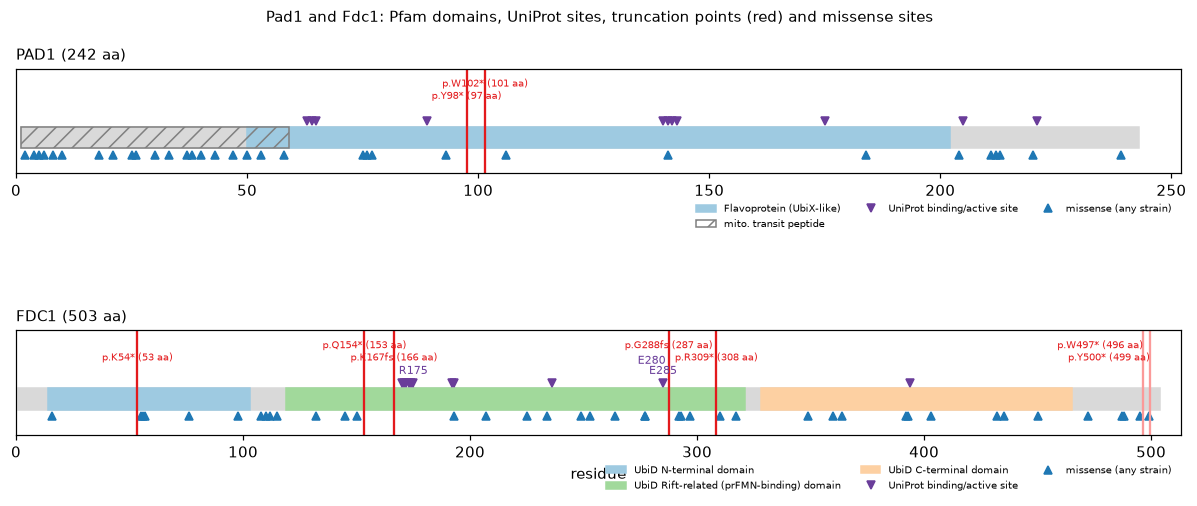

In [38]:
# 5c. Figures
# (a) feature tracks with truncation points and missense sites
fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), gridspec_kw={"height_ratios": [1, 1]})
dom_col = ["#9ecae1", "#a1d99b", "#fdd0a2"]
for ax, g in zip(axes, ["PAD1", "FDC1"]):
    L = FULL[g]
    ax.add_patch(plt.Rectangle((1, -0.15), L, 0.3, color="#d9d9d9"))
    for i, (_, name, s, e) in enumerate(UNI[g]["pfam"]):
        ax.add_patch(plt.Rectangle((s, -0.15), e - s + 1, 0.3, color=dom_col[i % 3], label=name))
    for f in UNI[g]["features"]:
        if f["type"] == "Transit peptide":
            ax.add_patch(plt.Rectangle((f["start"], -0.15), f["end"] - f["start"] + 1, 0.3,
                                       fill=False, hatch="//", ec="grey", label="mito. transit peptide"))
    bpos = sorted({n for n, _ in BIND[g]})
    ax.plot(bpos, [0.22] * len(bpos), "v", color="#6a3d9a", ms=5, label="UniProt binding/active site")
    for k, lab in ACTIVE.get(g, {}).items():
        ax.annotate(lab.split()[0], (k, 0.22 if k != 280 else 0.36), xytext=(0, 6), textcoords="offset points",
                    ha="center", fontsize=7, color="#6a3d9a")
    mg = mctx[mctx.gene == g]
    ax.plot(mg.pos, [-0.24] * len(mg), "^", color="#1f78b4", ms=5, label="missense (any strain)")
    for i, (_, t) in enumerate(cuts[cuts.gene == g].iterrows()):
        x = t.native_residues + 0.5
        ax.axvline(x, color="#e31a1c" if t.LOF_called else "#fb9a99", lw=1.5)
        ax.text(x, 0.5 + 0.17 * (i % 2), f"{t.label} ({t.native_residues} aa)", color="#e31a1c",
                fontsize=6.5, ha="right" if x > 0.9 * L else "center", va="bottom")
    ax.set_xlim(0, L + 10); ax.set_ylim(-0.5, 0.95); ax.set_yticks([])
    ax.set_title(f"{g} ({L} aa)", loc="left", fontsize=10)
    ax.legend(fontsize=6.5, loc="lower right", ncol=3, frameon=False, bbox_to_anchor=(1, -0.62))
axes[-1].set_xlabel("residue")
fig.suptitle("Pad1 and Fdc1: Pfam domains, UniProt sites, truncation points (red) and missense sites", fontsize=10)
fig.tight_layout(); fig.savefig(f"{FIG}/05a_feature_tracks.png", dpi=200); plt.show()

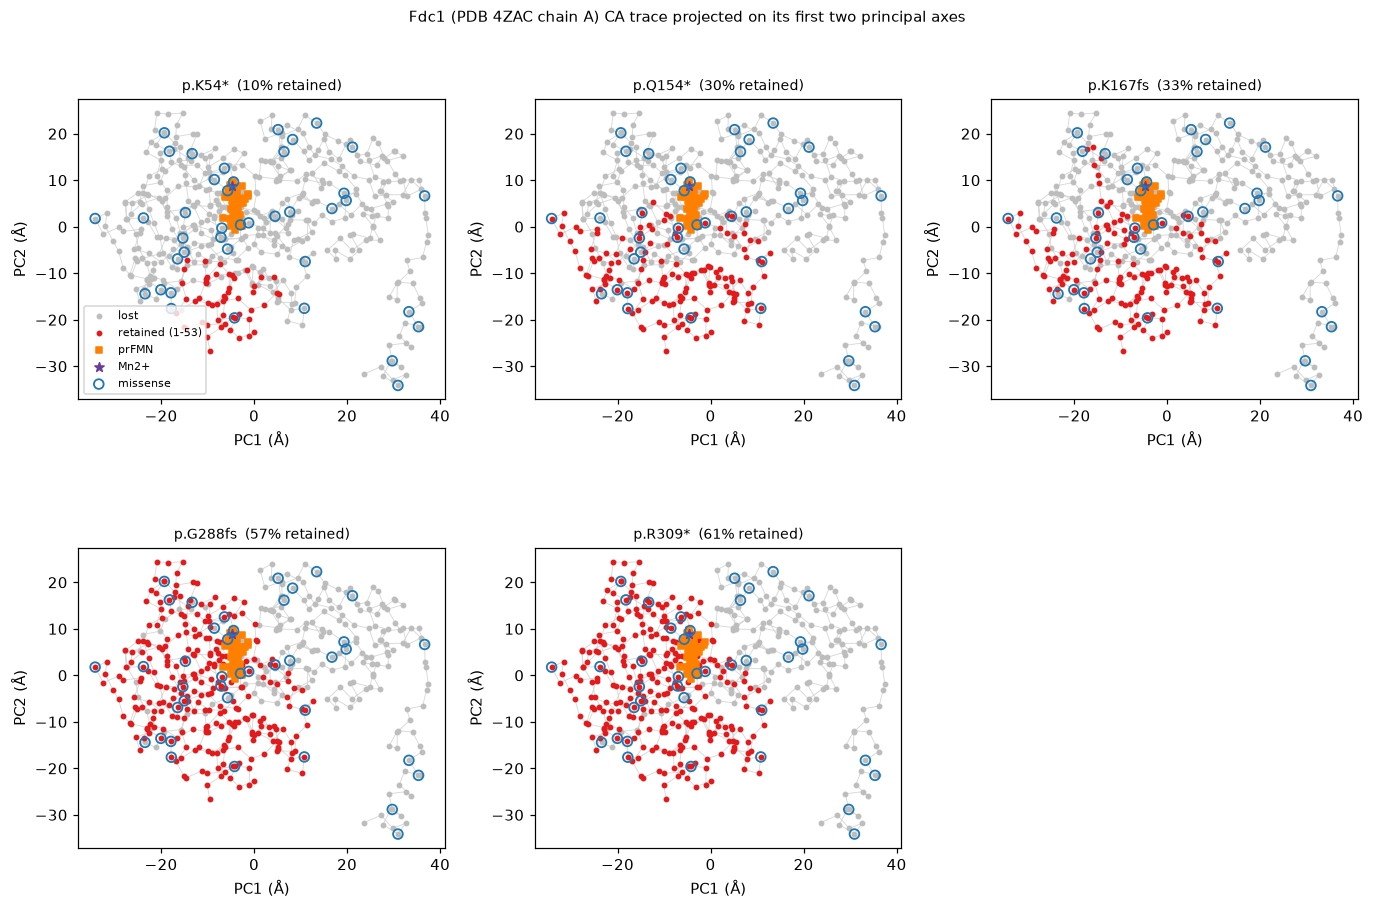

In [39]:
# (b) PCA projection of the Fdc1 CA trace, retained vs lost for each Fdc1 truncation
X = CA["FDC1"]; mu = X.mean(0)
_, _, Vt = np.linalg.svd(X - mu, full_matrices=False)
P = (X - mu) @ Vt[:2].T
Pc = (np.array([a.coord for a in prfmn]) - mu) @ Vt[:2].T
Pm = (np.array([a.coord for a in mn]) - mu) @ Vt[:2].T
ft = cuts[(cuts.gene == "FDC1") & cuts.LOF_called].reset_index(drop=True)
nc = min(3, len(ft)); nr = -(-len(ft) // nc)
fig, axes = plt.subplots(nr, nc, figsize=(4.2 * nc, 4.3 * nr), squeeze=False)
for ax in axes.flat[len(ft):]:
    ax.axis("off")
for ax, (_, t) in zip(axes.flat, ft.iterrows()):
    keep = RESNUM["FDC1"] <= t.native_residues
    ax.plot(P[:, 0], P[:, 1], color="#d9d9d9", lw=0.6, zorder=1)
    ax.scatter(*P[~keep].T, s=8, c="#bdbdbd", label="lost", zorder=2)
    ax.scatter(*P[keep].T, s=8, c="#e31a1c", label=f"retained (1-{t.native_residues})", zorder=3)
    ax.scatter(*Pc.T, s=14, c="#ff7f00", marker="s", label="prFMN", zorder=4)
    ax.scatter(*Pm.T, s=40, c="#6a3d9a", marker="*", label="Mn2+", zorder=4)
    idx = np.isin(RESNUM["FDC1"], mctx[mctx.gene == "FDC1"].pos)
    ax.scatter(*P[idx].T, s=40, facecolors="none", edgecolors="#1f78b4", lw=1.2, label="missense", zorder=5)
    ax.set_title(f"{t.label}  ({t.fraction_retained:.0%} retained)", fontsize=9)
    ax.set_xlabel("PC1 (Å)"); ax.set_ylabel("PC2 (Å)"); ax.set_aspect("equal")
axes[0][0].legend(fontsize=7, loc="best")
fig.suptitle("Fdc1 (PDB 4ZAC chain A) CA trace projected on its first two principal axes", fontsize=10)
fig.tight_layout(); fig.savefig(f"{FIG}/05b_fdc1_ca_pca_truncations.png", dpi=200); plt.show()

p.K54*: retained segment has 42 internal long-range contacts and 112 contacts to the lost part (73% of its contacts)
p.Q154*: retained segment has 192 internal long-range contacts and 246 contacts to the lost part (56% of its contacts)
p.K167fs: retained segment has 192 internal long-range contacts and 328 contacts to the lost part (63% of its contacts)
p.G288fs: retained segment has 564 internal long-range contacts and 265 contacts to the lost part (32% of its contacts)
p.R309*: retained segment has 694 internal long-range contacts and 141 contacts to the lost part (17% of its contacts)


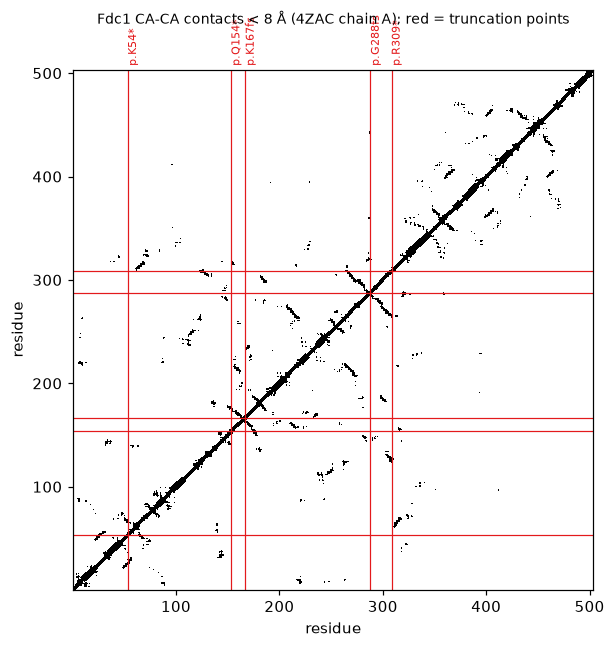

In [40]:
# (c) CA-CA contact map (< 8 Å) with truncation lines
D = np.linalg.norm(CA["FDC1"][:, None] - CA["FDC1"][None], axis=-1)
C = D < 8.0
fig, ax = plt.subplots(figsize=(6.2, 6))
ax.imshow(C, cmap="Greys", origin="lower", extent=[0.5, FULL["FDC1"] + 0.5] * 2, interpolation="nearest")
for _, t in ft.iterrows():
    x = t.native_residues + 0.5
    ax.axvline(x, color="#e31a1c", lw=0.8); ax.axhline(x, color="#e31a1c", lw=0.8)
    ax.text(x, FULL["FDC1"] + 4, t.label, color="#e31a1c", fontsize=7, rotation=90, va="bottom")
ax.set_xlabel("residue"); ax.set_ylabel("residue")
ax.set_title("Fdc1 CA-CA contacts < 8 Å (4ZAC chain A); red = truncation points", fontsize=9, pad=30)
fig.tight_layout(); fig.savefig(f"{FIG}/05c_fdc1_contact_map.png", dpi=200); plt.show()

# fraction of each truncation's long-range contacts (|i-j| > 5) that cross the cut
lr = C & (np.abs(RESNUM["FDC1"][:, None] - RESNUM["FDC1"][None]) > 5)
for _, t in ft.iterrows():
    k = RESNUM["FDC1"] <= t.native_residues
    kept_lr = lr[np.ix_(k, k)].sum() / 2; cross = lr[np.ix_(k, ~k)].sum()
    print(f"{t.label}: retained segment has {int(kept_lr)} internal long-range contacts and "
          f"{int(cross)} contacts to the lost part ({cross / (kept_lr + cross):.0%} of its contacts)")

figures written: ['05a_feature_tracks.png', '05b_fdc1_ca_pca_truncations.png', '05c_fdc1_contact_map.png', '05d_missense_distances.png']


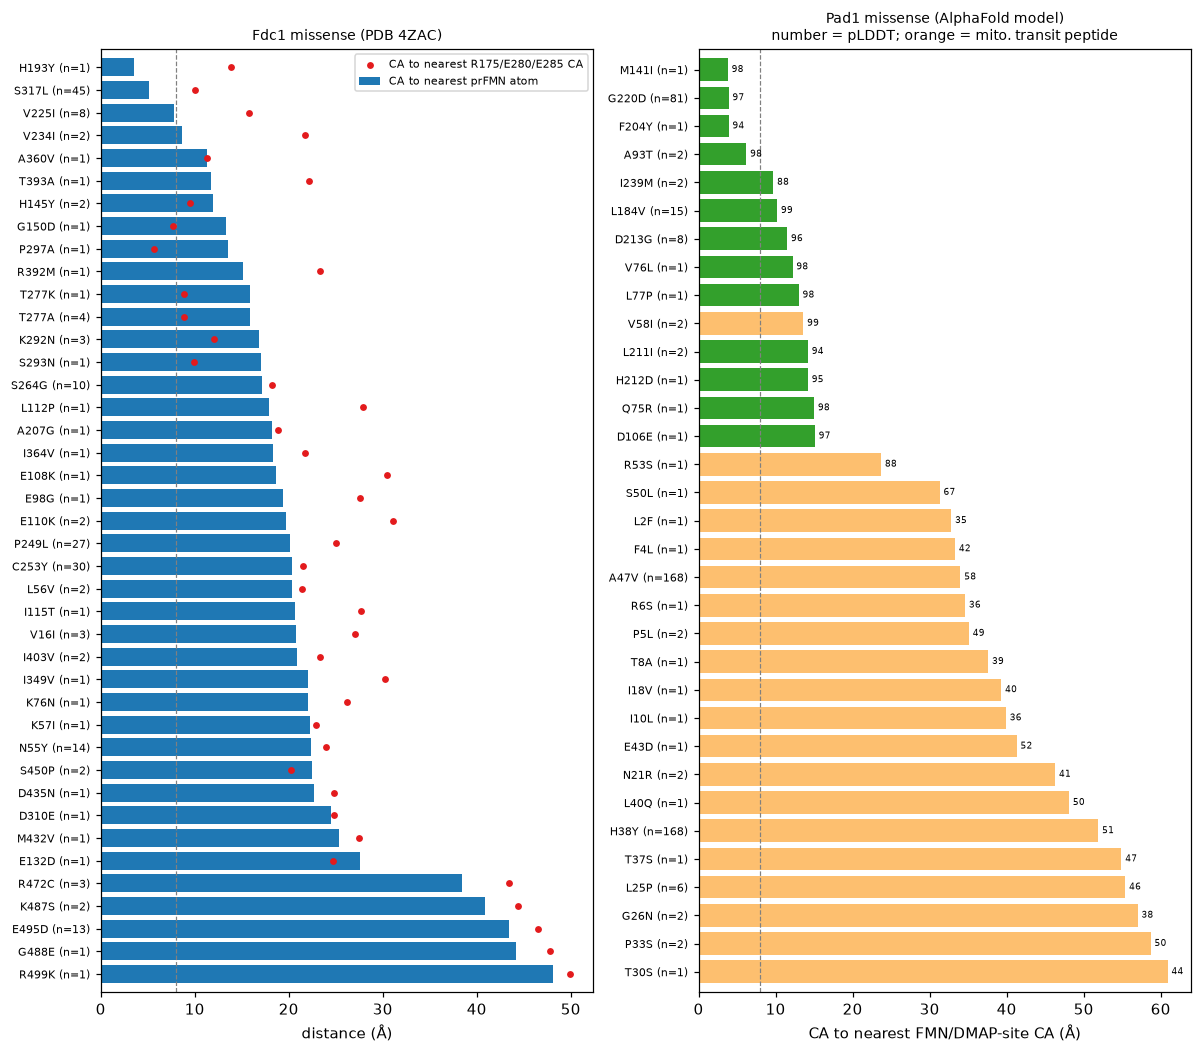

In [41]:
# (d) distance to cofactor for missense variants
fm = mctx[mctx.gene == "FDC1"].sort_values("d_prFMN_A", ascending=False)
pm = mctx[mctx.gene == "PAD1"].sort_values("d_binding_site_CA_A", ascending=False)
lab = lambda d: d.protein_change.str[2:] + " (n=" + d.n_records.astype(str) + ")"
fig, axes = plt.subplots(1, 2, figsize=(11, 0.2 * max(len(fm), len(pm)) + 1.5))
ax = axes[0]
ax.barh(lab(fm), fm.d_prFMN_A, color="#1f78b4", label="CA to nearest prFMN atom")
ax.scatter(fm.d_active_site_A, lab(fm), color="#e31a1c", s=12, zorder=3, label="CA to nearest R175/E280/E285 CA")
ax.axvline(8, ls="--", color="grey", lw=0.8)
ax.set_xlabel("distance (Å)"); ax.set_title("Fdc1 missense (PDB 4ZAC)", fontsize=9)
ax.legend(fontsize=7, loc="upper right"); ax.tick_params(axis="y", labelsize=7); ax.margins(y=0.01)
ax = axes[1]
cols = ["#fdbf6f" if t else "#33a02c" for t in pm.in_transit_peptide]
ax.barh(lab(pm), pm.d_binding_site_CA_A, color=cols)
for y, (d, q) in enumerate(zip(pm.d_binding_site_CA_A, pm.b_or_plddt)):
    ax.text(d + 0.5, y, f"{q:.0f}", va="center", fontsize=6)
ax.axvline(8, ls="--", color="grey", lw=0.8)
ax.set_title("Pad1 missense (AlphaFold model)\nnumber = pLDDT; orange = mito. transit peptide", fontsize=9)
ax.set_xlabel("CA to nearest FMN/DMAP-site CA (Å)"); ax.tick_params(axis="y", labelsize=7); ax.margins(y=0.01)
fig.tight_layout(); fig.savefig(f"{FIG}/05d_missense_distances.png", dpi=200); plt.show()
print("figures written:", sorted(f for f in os.listdir(FIG) if f.startswith("05")))

In [42]:
# 7. Is POF loss a domestication signal once relatedness is accounted for? (A1) Does the genotype predict the measured phenotype? (A3)
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.proportion import proportion_confint

RES, EXT = "data/results", "data/raw/external/gallone2016"
for _f in ("mmc1.xlsx", "mmc5.xlsx"):
    ensure_external(f"{EXT}/{_f}")      # cache-first download + checksum (step 00)
GENO_CSV = f"{RES}/pof_genotype_by_strain.csv"
assert os.path.exists(GENO_CSV), "run steps 01-03 first: pof_genotype_by_strain.csv is missing"

# Step 1: load the Gallone strain table. The first rows are section headers ("Strains sequenced in this
# study"), so I keep only rows whose Code looks like two letters + three digits (BE001, WI012, ...).
s1 = pd.read_excel(f"{EXT}/mmc1.xlsx")
s1 = s1[s1.Code.astype(str).str.fullmatch(r"[A-Z]{2}\d{3}")].copy()

# The Gallone tables use codes (BE001) but the NCBI BioSample records, and therefore our genotype table,
# use names like beer001. The prefix mapping below was checked one-to-one against the 157 BioSamples
#, so I can join on it safely.
PREFIX = {"BE": "beer", "WI": "wine", "SP": "spirits", "SA": "sake", "WL": "wild", "BI": "bioethanol",
          "BR": "bread", "LA": "laboratory"}
s1["strain"] = s1.Code.str[:2].map(PREFIX) + s1.Code.str[2:]
s1["clade"] = s1.Subpopulation.astype(str).str.strip().replace({"nan": np.nan, "NS": np.nan})
assert s1.strain.notna().all(), "an unexpected strain-code prefix appeared in Table S1"
print(f"Gallone strains in Table S1: {len(s1)}; with a clade label: {s1.clade.notna().sum()}")
s1.clade.value_counts()

Gallone strains in Table S1: 157; with a clade label: 153


clade
Mosaic             27
Britain            26
Wine               24
Beer2              21
Belgium/Germany    18
Mixed              17
US                 10
Asian              10
Name: count, dtype: int64

In [43]:
# Step 2: join the clade labels onto our predicted genotypes. Only Gallone strains have clade labels, so
# everything in this section is restricted to that panel (one genome per strain, one sequencing study).
geno = pd.read_csv(GENO_CSV)
gal = s1.merge(geno, on="strain", how="left")
gal["called"] = gal.predicted_POF.isin(["POF-", "POF+"])
print(f"Gallone strains matched to a genotype row: {gal.predicted_POF.notna().sum()} / {len(gal)}")
print(f"... with a POF call (both genes callable, or one LOF): {gal.called.sum()}")

# I group strains the same way as section 3.6 so the numbers are comparable: domesticated beverage =
# beer, sake, spirits; reference = wine, wild, bioethanol. Bread and laboratory strains are left out of the
# 2x2 (same as before) because they fit neither side cleanly. I use the strain-name prefix, not the Niche
# column, because Niche has sub-labels ("Beer (Lager)", "Saké", "Wild (Cocoa)") that an exact match misses.
DOMESTIC_PREFIX, REFERENCE_PREFIX = ["beer", "sake", "spirits"], ["wine", "wild", "bioethanol"]
gal["prefix"] = gal.strain.str.extract(r"^([a-z]+)")[0]
gal["side"] = np.where(gal.prefix.isin(DOMESTIC_PREFIX), "domesticated",
                       np.where(gal.prefix.isin(REFERENCE_PREFIX), "reference", "excluded"))
gal["pof_neg"] = (gal.predicted_POF == "POF-").astype(int)
G = gal[gal.called & (gal.side != "excluded")]
pd.crosstab([G.clade.fillna("no label"), G.side], G.predicted_POF)

Gallone strains matched to a genotype row: 157 / 157
... with a POF call (both genes callable, or one LOF): 156


predicted_POF                 POF+  POF-
clade           side                    
Asian           domesticated     0     6
                reference        4     0
Beer2           domesticated    20     1
Belgium/Germany domesticated    11     7
Britain         domesticated     0    25
                reference        0     1
Mixed           domesticated     1     9
                reference        3     0
Mosaic          domesticated     7     9
                reference        8     0
US              domesticated     0    10
Wine            domesticated    10     0
                reference       13     1
no label        domesticated     0     4

In [44]:
# 7.1 Strain-level Fisher test (Gallone panel only) and the clade-stratified CMH test
# Step 1: the uncorrected strain-level test on this panel, for comparison with section 3.6.
tab = [[((G.side == "domesticated") & (G.pof_neg == 1)).sum(), ((G.side == "domesticated") & (G.pof_neg == 0)).sum()],
       [((G.side == "reference") & (G.pof_neg == 1)).sum(), ((G.side == "reference") & (G.pof_neg == 0)).sum()]]
or_strain, p_strain = fisher_exact(tab)
print(f"strain-level 2x2 [[dom POF-, dom POF+], [ref POF-, ref POF+]]: {tab}")
print(f"Fisher OR: {or_strain:.2f}   p: {p_strain:.2e}")

# Step 2: build one 2x2 per clade and keep the informative ones (both sides present). I add 0.5 to empty
# cells only for the per-clade OR display; the CMH statistic itself uses the raw counts.
strata, rows = [], []
for clade, d in G.dropna(subset=["clade"]).groupby("clade"):
    t = np.array([[((d.side == "domesticated") & (d.pof_neg == 1)).sum(), ((d.side == "domesticated") & (d.pof_neg == 0)).sum()],
                  [((d.side == "reference") & (d.pof_neg == 1)).sum(), ((d.side == "reference") & (d.pof_neg == 0)).sum()]])
    informative = t[0].sum() > 0 and t[1].sum() > 0
    rows.append(dict(clade=clade, dom_POFneg=t[0, 0], dom_POFpos=t[0, 1], ref_POFneg=t[1, 0], ref_POFpos=t[1, 1],
                     informative=informative))
    if informative:
        strata.append(t)
cmh_tbl = pd.DataFrame(rows)
assert len(strata) >= 2, "CMH needs at least two clades that contain both domesticated and reference strains"

# Step 3: pooled Mantel-Haenszel OR with 95% CI, the CMH test of OR = 1, and Breslow-Day homogeneity.
st = StratifiedTable([t.astype(float) for t in strata])
cmh = st.test_null_odds(correction=True)
bd = st.test_equal_odds()
ci_lo, ci_hi = st.oddsratio_pooled_confint()
print(f"informative clades: {len(strata)} of {len(cmh_tbl)} ({', '.join(cmh_tbl[cmh_tbl.informative].clade)})")
print(f"strains in informative clades: {int(sum(t.sum() for t in strata))}")
print(f"MH pooled OR: {st.oddsratio_pooled:.2f} (95% CI {ci_lo:.2f}-{ci_hi:.2f}); CMH chi2: {cmh.statistic:.2f}, p: {cmh.pvalue:.2e}")
print(f"Breslow-Day homogeneity p: {bd.pvalue:.3f}")
# Step 3b: how fragile is the pooled OR? A clade only feeds the MH estimate if a*d + b*c > 0 (Britain, all
# POF-, adds nothing), and I count in how many of those the domesticated side is more often POF-.
contrib = [t for t in strata if t[0, 0] * t[1, 1] + t[0, 1] * t[1, 0] > 0]
dom_higher = sum(t[0, 0] / t[0].sum() > t[1, 0] / t[1].sum() for t in contrib)
print(f"clades that feed the MH estimate: {len(contrib)}; domesticated more often POF- in {dom_higher} of them")
cmh_tbl.to_csv(f"{RES}/cmh_strata_by_clade.csv", index=False)
cmh_tbl

strain-level 2x2 [[dom POF-, dom POF+], [ref POF-, ref POF+]]: [[np.int64(71), np.int64(49)], [np.int64(2), np.int64(28)]]
Fisher OR: 20.29   p: 7.86e-08
informative clades: 5 of 8 (Asian, Britain, Mixed, Mosaic, Wine)
strains in informative clades: 97
MH pooled OR: 17.94 (95% CI 3.08-104.71); CMH chi2: 15.82, p: 6.96e-05
Breslow-Day homogeneity p: 0.003
clades that feed the MH estimate: 4; domesticated more often POF- in 3 of them


,clade,dom_POFneg,dom_POFpos,ref_POFneg,ref_POFpos,informative
0,Asian,6,0,0,4,True
1,Beer2,1,20,0,0,False
2,Belgium/Germany,7,11,0,0,False
3,Britain,25,0,1,0,True
4,Mixed,9,1,0,3,True
5,Mosaic,9,7,0,8,True
6,US,10,0,0,0,False
7,Wine,0,10,1,13,True


In [45]:
# Step 4: clade-level view. I collapse to one row per clade so a clonal expansion counts once. A clade is
# called "POF− clade" when most of its called strains are POF−; that threshold is my own simple choice.
MAJORITY = 0.5
clade_view = (gal[gal.called].dropna(subset=["clade"]).groupby("clade")
              .agg(n=("strain", "size"), n_POFneg=("pof_neg", "sum"),
                   niches=("Niche", lambda x: ", ".join(f"{k} {v}" for k, v in x.value_counts().items()))))
clade_view["frac_POFneg"] = clade_view.n_POFneg / clade_view.n
clade_view["POFneg_clade"] = clade_view.frac_POFneg > MAJORITY
clade_view = clade_view.sort_values("frac_POFneg", ascending=False)
clade_view.to_csv(f"{RES}/pof_by_gallone_clade.csv")
print(f"clades that are mostly POF-: {clade_view.POFneg_clade.sum()} of {len(clade_view)}")
clade_view.round(2)

clades that are mostly POF-: 4 of 8


,n,n_POFneg,niches,frac_POFneg,POFneg_clade
clade,,,,,
Britain,26,26,"Beer 13, Beer (Pale ale) 4, Beer (Trappist) 3, Beer (Stout) 2, Beer (Bitter) 2, Beer (Lager) 1, Wine 1",1.00,True
US,10,10,"Beer 6, Beer (Pale ale) 3, Beer (Ale) 1",1.00,True
Mixed,17,12,"Beer (Ale refermentation) 5, Bread 4, Wild 3, Spirits 2, Beer (Ale) 1, Beer (Lager) 1, Beer (Alt) 1",0.71,True
Asian,10,6,"Saké 6, Bioethanol 3, Wild 1",0.60,True
Belgium/Germany,18,7,"Beer 3, Beer (Trappist) 3, Beer (Lager) 3, Beer (Ale) 2, Beer (Ale refermentation) 2, Beer (Wheat) 2, Beer (Bitter) 1, Beer (Hefeweizen) 1, Spirits 1",0.39,False
Mosaic,26,10,"Beer 5, Spirits 5, Wine 4, Beer (Hefeweizen) 3, Wild (Cocoa) 3, Lab 2, Beer (Trappist) 1, Beer (Lager) 1, Beer (Ale) 1, Bioethanol 1",0.38,False
Beer2,21,1,"Beer 10, Beer (Lager) 3, Beer (Ale refermentation) 2, Beer (Saison) 2, Beer (Strong ale) 2, Beer (Abbey) 1, Beer (Pale ale) 1",0.05,False
Wine,24,1,"Wine 14, Spirits 3, Beer (Strong ale) 2, Beer 2, Beer (Ale refermentation) 1, Beer (Trappist) 1, Saké 1",0.04,False


In [46]:
# Step 5: save the A1 numbers for the paper.
RESULTS.update({
    "a1_gallone_n_called": int(len(G)), "a1_gallone_table": [[int(x) for x in r] for r in tab],
    "a1_gallone_fisher_or": float(or_strain), "a1_gallone_fisher_p": float(p_strain),
    "a1_cmh_n_strata": len(strata), "a1_cmh_strata": list(cmh_tbl[cmh_tbl.informative].clade),
    "a1_cmh_n_strains": int(sum(t.sum() for t in strata)),
    "a1_cmh_n_contributing": len(contrib), "a1_cmh_n_dom_higher": int(dom_higher),
    "a1_cmh_or": float(st.oddsratio_pooled), "a1_cmh_or_ci": [float(ci_lo), float(ci_hi)],
    "a1_cmh_chi2": float(cmh.statistic), "a1_cmh_p": float(cmh.pvalue), "a1_breslow_day_p": float(bd.pvalue),
    "a1_n_clades": int(len(clade_view)), "a1_n_pofneg_clades": int(clade_view.POFneg_clade.sum()),
    "a1_pofneg_clades": list(clade_view[clade_view.POFneg_clade].index),
    "a1_clade_frac_pofneg": {k: float(v) for k, v in clade_view.frac_POFneg.items()},
    "a1_clade_n": {k: int(v) for k, v in clade_view.n.items()},
})

In [47]:
# 7.2 Does the predicted genotype match the measured phenotype? (A3)
# Step 1: read the phenotype and turn the z-score into a label.
s5 = pd.read_excel(f"{EXT}/mmc5.xlsx")
s5 = s5[s5["Sample Name"].astype(str).str.fullmatch(r"[A-Z]{2}\d{3}")].copy()
s5["strain"] = s5["Sample Name"].str[:2].map(PREFIX) + s5["Sample Name"].str[2:]
pof_num = pd.to_numeric(s5.POF, errors="coerce")
s5["measured_POF"] = np.select([np.isclose(pof_num, -0.921882, atol=1e-4), np.isclose(pof_num, 1.077693, atol=1e-4)],
                               ["POF-", "POF+"], default="ambiguous")
print(f"phenotyped strains: {len(s5)}; label counts: {s5.measured_POF.value_counts().to_dict()}")

# Step 2: join to the genotype calls and keep strains with both a clear phenotype and a POF call.
ph = s5.merge(gal[["strain", "Niche", "clade", "PAD1", "FDC1", "predicted_POF"]], on="strain", how="left")
both = ph[ph.measured_POF.isin(["POF-", "POF+"]) & ph.predicted_POF.isin(["POF-", "POF+"])].copy()
print(f"strains with both a clear phenotype and a genotype call: {len(both)}")
print(f"phenotyped but no genotype call ('?'): {(ph.measured_POF.isin(['POF-', 'POF+']) & ~ph.predicted_POF.isin(['POF-', 'POF+'])).sum()}")

# Step 3: confusion matrix and the usual diagnostic numbers, each with a Wilson 95% CI (better than the
# normal approximation when a proportion is close to 1, which it is here).
cm = pd.crosstab(both.predicted_POF, both.measured_POF).reindex(index=["POF-", "POF+"], columns=["POF-", "POF+"], fill_value=0)
tp, fp = cm.loc["POF-", "POF-"], cm.loc["POF-", "POF+"]
fn, tn = cm.loc["POF+", "POF-"], cm.loc["POF+", "POF+"]

def rate(k, n):
    """Proportion k/n with its Wilson 95% interval, as (p, lo, hi)."""
    lo, hi = proportion_confint(k, n, method="wilson")
    return float(k / n), float(lo), float(hi)

diag = {"sensitivity": rate(tp, tp + fn), "specificity": rate(tn, tn + fp),
        "ppv": rate(tp, tp + fp), "npv": rate(tn, tn + fn), "accuracy": rate(tp + tn, len(both))}
po = (tp + tn) / len(both)
pe = ((tp + fp) * (tp + fn) + (fn + tn) * (fp + tn)) / len(both) ** 2
kappa = (po - pe) / (1 - pe)          # Cohen's kappa: agreement beyond chance
for k, (p, lo, hi) in diag.items():
    print(f"{k}: {p:.1%} (95% CI {lo:.1%}-{hi:.1%})")
print(f"Cohen's kappa: {kappa:.2f}")
cm.to_csv(f"{RES}/pof_genotype_vs_phenotype_confusion.csv")
cm

phenotyped strains: 154; label counts: {'POF-': 83, 'POF+': 71}
strains with both a clear phenotype and a genotype call: 153
phenotyped but no genotype call ('?'): 1
sensitivity: 77.1% (95% CI 67.0%-84.8%)
specificity: 85.7% (95% CI 75.7%-92.1%)
ppv: 86.5% (95% CI 76.9%-92.5%)
npv: 75.9% (95% CI 65.5%-84.0%)
accuracy: 81.0% (95% CI 74.1%-86.5%)
Cohen's kappa: 0.62


measured_POF,POF-,POF+
predicted_POF,,
POF-,64,10
POF+,19,60


In [48]:
# Step 4: the discordant strains are the interesting ones, so I list them with their genotype detail.
# Predicted POF+ but measured POF− means a loss our caller missed (another mutation, a missing record, or
# regulation); predicted POF− but measured POF+ points to heterozygosity (a working copy hidden behind a
# consensus LOF call) or to a mislabelled record.
disc = both[both.predicted_POF != both.measured_POF].sort_values(["measured_POF", "strain"])
disc[["strain", "Niche", "clade", "PAD1", "FDC1", "predicted_POF", "measured_POF"]].to_csv(f"{RES}/pof_discordant_strains.csv", index=False)
disc[["strain", "Niche", "clade", "PAD1", "FDC1", "predicted_POF", "measured_POF"]]

,strain,Niche,clade,PAD1,FDC1,predicted_POF,measured_POF
5,beer006,Beer (Ale refermentation),Mixed,0.0,1.0,POF-,POF+
24,beer025,Beer (Ale refermentation),Mixed,0.0,1.0,POF-,POF+
27,beer028,Beer (Ale refermentation),Mixed,0.0,1.0,POF-,POF+
28,beer029,Beer (Ale refermentation),Mixed,0.0,1.0,POF-,POF+
63,beer064,Beer,Britain,1.0,1.0,POF-,POF+
86,beer087,Beer (Lager),Belgium/Germany,1.0,1.0,POF-,POF+
104,bread001,Bread,Mixed,0.0,1.0,POF-,POF+
106,bread003,Bread,Mixed,0.0,1.0,POF-,POF+
107,bread004,Bread,Mixed,0.0,1.0,POF-,POF+
124,spirits008,Spirits,Mosaic,1.0,1.0,POF-,POF+


In [49]:
# Step 5: save the A3 numbers.
RESULTS.update({
    "a3_n_phenotyped": int(len(s5)), "a3_n_ambiguous_pheno": int((s5.measured_POF == "ambiguous").sum()),
    "a3_n_compared": int(len(both)),
    "a3_confusion": {"TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)},
    **{f"a3_{k}": v for k, v in diag.items()}, "a3_kappa": float(kappa),
    "a3_discordant": disc[["strain", "Niche", "clade", "predicted_POF", "measured_POF"]].to_dict("records"),
})

In [50]:
# 7.3 Which alleles explain the disagreements?
# Step 1: one "allele signature" per strain = all nonsense/frameshift alleles it carries, sorted.
vc = pd.read_csv(f"{RES}/variant_calls.csv")
trunc = vc[vc.effect.isin(["nonsense", "frameshift"])]
sig = (trunc.assign(a=trunc.gene + " " + trunc.protein_change.str.replace("p.", "", regex=False))
       .groupby("strain").a.apply(lambda x: " + ".join(sorted(set(x)))))
ph2 = ph[ph.measured_POF.isin(["POF-", "POF+"])].copy()
ph2["alleles"] = ph2.strain.map(sig).fillna("no truncating allele")
allele_pheno = pd.crosstab(ph2.alleles, ph2.measured_POF).reindex(columns=["POF-", "POF+"], fill_value=0)
allele_pheno["n"] = allele_pheno.sum(axis=1)
allele_pheno = allele_pheno.sort_values("n", ascending=False)
allele_pheno.to_csv(f"{RES}/pof_phenotype_by_allele_signature.csv")
allele_pheno

measured_POF,POF-,POF+,n
alleles,,,
no truncating allele,16,60,76
FDC1 K167fs + FDC1 Q154* + PAD1 W102*,47,3,50
FDC1 K167fs,7,6,13
FDC1 K54*,6,0,6
FDC1 W497*,3,1,4
FDC1 G288fs + PAD1 Y98*,1,0,1
FDC1 K54* + PAD1 W102*,1,0,1
FDC1 K167fs + FDC1 Q154*,1,0,1
FDC1 R309*,1,0,1


In [51]:
# Step 2: sensitivity analysis. Rule A = the caller as is. Rule B counts the late FDC1 stops (W497*, Y500*)
# as LOF, which drops the 95%-length rule. Rule C additionally ignores c.501dupA when it is the strain's only
# truncating allele, because it sits in an A6 homopolymer where assembly errors are common.
LATE = {"FDC1 W497*", "FDC1 Y500*"}
def rescore(row, count_late, drop_lone_dup):
    """Return the predicted POF label for one strain under the chosen rule."""
    al = set() if row.alleles == "no truncating allele" else set(row.alleles.split(" + "))
    if drop_lone_dup and al == {"FDC1 K167fs"}:
        al = set()
    if not count_late:
        al -= LATE
    if al:
        return "POF-"
    # no truncating allele left: intact only if both genes had a callable record (PAD1/FDC1 are not NaN)
    return "POF+" if pd.notna(row.PAD1) and pd.notna(row.FDC1) else "?"

sens_rows = []
for name, late, dup in [("A: caller as published here", False, False), ("B: late stops count as LOF", True, False),
                        ("C: B + ignore lone c.501dupA", True, True)]:
    pred = ph2.apply(rescore, axis=1, count_late=late, drop_lone_dup=dup)
    ok = pred.isin(["POF-", "POF+"])
    m, q = ph2.measured_POF[ok], pred[ok]
    tp_, fn_ = ((q == "POF-") & (m == "POF-")).sum(), ((q == "POF+") & (m == "POF-")).sum()
    tn_, fp_ = ((q == "POF+") & (m == "POF+")).sum(), ((q == "POF-") & (m == "POF+")).sum()
    sens_rows.append(dict(rule=name, n=int(ok.sum()), TP=int(tp_), FN=int(fn_), TN=int(tn_), FP=int(fp_),
                          sensitivity=tp_ / (tp_ + fn_), specificity=tn_ / (tn_ + fp_),
                          accuracy=(tp_ + tn_) / ok.sum()))
sens = pd.DataFrame(sens_rows)
assert sens.loc[0, ["TP", "FN", "TN", "FP"]].tolist() == [tp, fn, tn, fp] or sens.loc[0, "n"] != len(both),     "rule A should reproduce the confusion matrix above"
sens.to_csv(f"{RES}/pof_caller_sensitivity.csv", index=False)
sens.round(3)

,rule,n,TP,FN,TN,FP,sensitivity,specificity,accuracy
0,A: caller as published here,153,64,19,60,10,0.771,0.857,0.810
1,B: late stops count as LOF,153,67,16,59,11,0.807,0.843,0.824
2,C: B + ignore lone c.501dupA,153,60,23,65,5,0.723,0.929,0.817


In [52]:
# Step 3: save the allele-level numbers the paper needs.
def counts_for(label):
    """Measured POF-/POF+ counts for one allele signature (0, 0 if absent)."""
    if label not in allele_pheno.index:
        return {"POF-": 0, "POF+": 0}
    return {k: int(allele_pheno.loc[label, k]) for k in ["POF-", "POF+"]}
RESULTS.update({
    "a3_allele_pheno": {k: {c: int(v) for c, v in r.items()} for k, r in allele_pheno.iterrows()},
    "a3_lone_dupA": counts_for("FDC1 K167fs"),
    "a3_w497": counts_for("FDC1 W497*"),
    "a3_sensitivity_rules": sens.to_dict("records"),
})

In [53]:
# 8. How many times was the clove flavour lost? (A2)
import os
import numpy as np
import pandas as pd
from Bio import Phylo

RES = "data/results"
HAP_CSV, TREE_NWK = f"{RES}/PAD1_FDC1_haplotypes.csv", f"{RES}/PAD1_FDC1_haplotype_nj_bootstrap.nwk"
assert os.path.exists(HAP_CSV) and os.path.exists(TREE_NWK), "run step 04 first (haplotype table and tree)"

# Step 1: one allele set per strain (every nonsense or frameshift change, including the late stops so I can
# show them separately), then one allele set per haplotype. Strains in one haplotype have identical PAD1+FDC1
# sequence, so they must share alleles; the assert checks that.
vc = pd.read_csv(f"{RES}/variant_calls.csv")
trunc = vc[vc.effect.isin(["nonsense", "frameshift"])].copy()
trunc["allele"] = trunc.gene + " " + trunc.hgvs_c + " " + trunc.protein_change
LATE_STOPS = {"p.W497*", "p.Y500*"}          # stop at >= 95% of Fdc1 length; not called LOF by the caller (step 03)
hap = pd.read_csv(HAP_CSV)
strain_alleles = trunc.groupby("strain").allele.apply(set)
hap["alleles"] = hap.strain.map(strain_alleles).apply(lambda x: x if isinstance(x, set) else set())
per_hap = hap.groupby("haplotype").alleles.agg(lambda s: frozenset().union(*s))
mixed = hap.groupby("haplotype").alleles.agg(lambda s: len({frozenset(x) for x in s}) > 1)
print(f"haplotypes: {hap.haplotype.nunique()}  strains: {len(hap)}  haplotypes with mixed allele sets: {mixed.sum()}")
missing = sorted(set(trunc.strain) - set(hap.strain))
print(f"strains with a truncating allele but no paired PAD1+FDC1 haplotype (left out of the tree count): {missing}")

haplotypes: 61  strains: 169  haplotypes with mixed allele sets: 0
strains with a truncating allele but no paired PAD1+FDC1 haplotype (left out of the tree count): ['Awamori 101', 'Kagoshima yeast No.5', 'unnamed (AB293446.1)']


In [54]:
# Step 2: the tree-free lower bound. I list each distinct mutation with how many strains and which groups and
# Gallone clades carry it (clades from Table S1, joined the same way as step 07).
s1 = pd.read_excel(ensure_external("data/raw/external/gallone2016/mmc1.xlsx"))
s1 = s1[s1.Code.astype(str).str.fullmatch(r"[A-Z]{2}\d{3}")]
PREFIX = {"BE": "beer", "WI": "wine", "SP": "spirits", "SA": "sake", "WL": "wild", "BI": "bioethanol",
          "BR": "bread", "LA": "laboratory"}
clade_of = dict(zip(s1.Code.str[:2].map(PREFIX) + s1.Code.str[2:], s1.Subpopulation.astype(str).str.strip()))
trunc["clade"] = trunc.strain.map(clade_of).fillna("not in Gallone panel")
origin_tbl = (trunc.groupby(["gene", "hgvs_c", "protein_change"])
              .agg(n_strains=("strain", "nunique"),
                   groups=("group", lambda x: "; ".join(f"{k} {v}" for k, v in x.value_counts().items())),
                   clades=("clade", lambda x: "; ".join(f"{k} {v}" for k, v in x.value_counts().items())))
              .reset_index())
origin_tbl["called_LOF"] = ~origin_tbl.protein_change.isin(LATE_STOPS)
n_distinct_lof = int(origin_tbl.called_LOF.sum())
print(f"distinct LOF mutations (lower bound on independent origins): {n_distinct_lof}")
print(f"... plus late stops not called LOF: {int((~origin_tbl.called_LOF).sum())}")
origin_tbl

distinct LOF mutations (lower bound on independent origins): 8
... plus late stops not called LOF: 2


,gene,hgvs_c,protein_change,n_strains,groups,clades,called_LOF
0,FDC1,c.1491G>A,p.W497*,4,Beer (Gallone) 4,Beer2 4,False
1,FDC1,c.1500C>G,p.Y500*,1,Other/Unknown 1,not in Gallone panel 1,False
2,FDC1,c.160A>T,p.K54*,12,Sake 7; Shochu/Awamori 3; Other/Unknown 1; Beer (Gallone) 1,Asian 6; not in Gallone panel 5; Beer2 1,True
3,FDC1,c.460C>T,p.Q154*,57,Beer (Gallone) 52; Ale 1; Wine 1; Spirits 1; Baking 1; Other/Unknown 1,Britain 26; US 10; Belgium/Germany 7; Mosaic 6; NS 4; not in Gallone panel 2; Mixed 2,True
4,FDC1,c.501dupA,p.K167fs,71,Beer (Gallone) 60; Spirits 4; Other/Unknown 4; Baking 2; Ale 1; Lager 1; Wine 1,Britain 26; Mixed 11; US 10; Mosaic 9; Belgium/Germany 7; not in Gallone panel 6; NS 4,True
5,FDC1,c.864delA,p.G288fs,1,Laboratory 1,Mosaic 1,True
6,FDC1,c.925A>T,p.R309*,1,Wine 1,Wine 1,True
7,PAD1,c.294T>G,p.Y98*,1,Laboratory 1,Mosaic 1,True
8,PAD1,c.305G>A,p.W102*,55,Beer (Gallone) 51; Ale 1; Wine 1; Spirits 1; Other/Unknown 1,Britain 26; US 10; Belgium/Germany 7; Mosaic 6; NS 4; not in Gallone panel 2,True
9,PAD1,c.306G>A,p.W102*,1,Beer (Gallone) 1,Beer2 1,True


In [55]:
# Step 3: Sankoff parsimony on the haplotype tree for a 0/1 trait. I wrote it from the textbook recursion
# because Biopython has no parsimony scorer for a single character; it handles polytomies, which NJ can
# leave after zero-length branches. Cost of a node in state s = sum over children of min(cost of child in
# s, cost of child in the other state + 1).
def sankoff_changes(tree, present):
    """Minimum number of 0<->1 changes on the tree for leaf set `present`, with the root forced to 0 (absent)."""
    def cost(clade):
        if clade.is_terminal():
            return np.array([np.inf, 0.0]) if clade.name in present else np.array([0.0, np.inf])
        c = np.zeros(2)
        for ch in clade.clades:
            cc = cost(ch)
            c += [min(cc[0], cc[1] + 1), min(cc[1], cc[0] + 1)]
        return c
    return int(cost(tree.root)[0])

# Quick self-check on toy trees: one allele on one cherry = 1 change; on two separate leaves = 2 changes.
_t = Phylo.read(__import__("io").StringIO("((A,B),(C,(D,E)));"), "newick")
assert sankoff_changes(_t, {"A", "B"}) == 1 and sankoff_changes(_t, {"A", "D"}) == 2 and sankoff_changes(_t, set()) == 0

# Step 4: root the haplotype tree on the S288C haplotype. S288C carries no truncating allele and is the
# reference the alleles are named against, so "absent at the root" is the natural starting state.
tree = Phylo.read(TREE_NWK, "newick")
s288c_hap = f"H{int(hap.loc[hap.strain == 'S288C', 'haplotype'].iloc[0])}"
tree.root_with_outgroup(s288c_hap)
rows = []
for r in origin_tbl.itertuples():
    a = f"{r.gene} {r.hgvs_c} {r.protein_change}"
    carriers = {f"H{k}" for k, al in per_hap.items() if a in al}
    rows.append(dict(allele=a, n_haplotypes=len(carriers), parsimony_changes=sankoff_changes(tree, carriers) if carriers else 0))
pars = origin_tbl.assign(allele=origin_tbl.gene + " " + origin_tbl.hgvs_c + " " + origin_tbl.protein_change).merge(pd.DataFrame(rows), on="allele")
pars.to_csv(f"{RES}/lof_independent_origins.csv", index=False)
print(f"tree rooted on {s288c_hap} (S288C)")
pars[["allele", "n_strains", "n_haplotypes", "parsimony_changes", "called_LOF", "clades"]]

tree rooted on H8 (S288C)


,allele,n_strains,n_haplotypes,parsimony_changes,called_LOF,clades
0,FDC1 c.1491G>A p.W497*,4,1,1,False,Beer2 4
1,FDC1 c.1500C>G p.Y500*,1,1,1,False,not in Gallone panel 1
2,FDC1 c.160A>T p.K54*,12,5,1,True,Asian 6; not in Gallone panel 5; Beer2 1
3,FDC1 c.460C>T p.Q154*,57,10,2,True,Britain 26; US 10; Belgium/Germany 7; Mosaic 6; NS 4; not in Gallone panel 2; Mixed 2
4,FDC1 c.501dupA p.K167fs,71,18,3,True,Britain 26; Mixed 11; US 10; Mosaic 9; Belgium/Germany 7; not in Gallone panel 6; NS 4
5,FDC1 c.864delA p.G288fs,1,1,1,True,Mosaic 1
6,FDC1 c.925A>T p.R309*,1,1,1,True,Wine 1
7,PAD1 c.294T>G p.Y98*,1,1,1,True,Mosaic 1
8,PAD1 c.305G>A p.W102*,55,8,1,True,Britain 26; US 10; Belgium/Germany 7; Mosaic 6; NS 4; not in Gallone panel 2
9,PAD1 c.306G>A p.W102*,1,1,1,True,Beer2 1


In [56]:
# Step 5: a joint view of the POF trait. A strain is POF− here if it carries any called-LOF allele. The
# parsimony count for this combined trait is the number of times POF− (re)appears on the tree; I report it
# next to the distinct-mutation bound because they answer slightly different questions.
lof_alleles = set(pars[pars.called_LOF].allele)
pofneg_haps = {f"H{k}" for k, al in per_hap.items() if al & lof_alleles}
pof_changes = sankoff_changes(tree, pofneg_haps)
print(f"haplotypes carrying >= 1 called LOF allele: {len(pofneg_haps)} of {len(per_hap)}")
print(f"minimum POF+ <-> POF- changes on the haplotype tree: {pof_changes}")

# Step 6: mutations are not losses. A second stop codon in a gene that is already broken changes nothing,
# so I join LOF mutations that ever occur in the same strain (union-find) and count the groups. Groups never
# share a strain, so each one needs its own loss: this is the minimum number of separate losses of POF.
lof_carriers = {a: set(trunc.loc[trunc.allele == a, "strain"]) for a in lof_alleles}
parent = {a: a for a in lof_carriers}
def find(a):
    while parent[a] != a:
        a = parent[a]
    return a
for a in lof_carriers:
    for b in lof_carriers:
        if a < b and lof_carriers[a] & lof_carriers[b]:
            parent[find(a)] = find(b)
events = {}
for a in lof_carriers:
    events.setdefault(find(a), []).append(a)
BEVERAGE = {"Beer (Gallone)", "Ale", "Lager", "Sake", "Shochu/Awamori", "Spirits"}
event_rows = []
for als in events.values():
    strains = set().union(*(lof_carriers[a] for a in als))
    grp = trunc[trunc.strain.isin(strains)].drop_duplicates("strain").group
    event_rows.append(dict(alleles=" + ".join(sorted(a.split(" p.")[1] if " p." in a else a for a in als)),
                           n_strains=len(strains), beverage=bool(grp.isin(BEVERAGE).mean() > 0.5),
                           groups="; ".join(f"{k} {v}" for k, v in grp.value_counts().items())))
loss_events = pd.DataFrame(event_rows).sort_values("n_strains", ascending=False)
# self-check: groups split the 8 mutations exactly once each
assert sum(len(v) for v in events.values()) == n_distinct_lof, "every LOF mutation must sit in exactly one loss group"
print(f"separate losses (mutation groups that never share a strain): {len(loss_events)}, "
      f"in mostly beverage strains: {int(loss_events.beverage.sum())}")
loss_events

RESULTS.update({
    "a2_n_loss_events": int(len(loss_events)), "a2_n_beverage_loss_events": int(loss_events.beverage.sum()),
    "a2_loss_events": loss_events.to_dict("records"),
    "a2_n_distinct_lof": n_distinct_lof,
    "a2_n_late_stops": int((~origin_tbl.called_LOF).sum()),
    "a2_alleles": pars[["allele", "n_strains", "n_haplotypes", "parsimony_changes", "called_LOF", "groups", "clades"]].to_dict("records"),
    "a2_n_haplotypes": int(len(per_hap)), "a2_n_pofneg_haplotypes": len(pofneg_haps),
    "a2_pof_parsimony_changes": pof_changes, "a2_tree_root": s288c_hap,
    "a2_missing_from_tree": missing,
})

haplotypes carrying >= 1 called LOF allele: 26 of 61
minimum POF+ <-> POF- changes on the haplotype tree: 7
separate losses (mutation groups that never share a strain): 4, in mostly beverage strains: 2


In [57]:
# 9. MAL/MPH transporter copy number across the 1,011 S. cerevisiae genomes
# Libraries used in this step
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, kruskal       # rank tests (beyond class)
from statsmodels.stats.multitest import multipletests  # Benjamini-Hochberg (beyond class)

# Input files (downloaded earlier, see data/MANIFEST.csv)
cn_path = ensure_external("data/raw/external/peter2018_1002genomes/genesMatrix_CopyNumber.tab.gz")
meta_path = ensure_external("data/raw/external/peter2018_nature_supp/41586_2018_30_MOESM3_ESM.xls")
os.makedirs("data/results", exist_ok=True)
os.makedirs("figures/extended", exist_ok=True)

# The matrix columns for my genes. I checked these names by searching the header for the
# systematic IDs; the '_NumOfGenes_2' suffix marks a column that merges two paralogs.
gene_cols = {
    "MAL11": "X4188.YGR289C",                    # AGT1, the maltotriose transporter
    "MAL31": "X2289.YBR298C_NumOfGenes_2",       # MAL31 + paralog, merged
    "MPH2/3": "X2689.YDL247W_NumOfGenes_2",      # MPH2 + MPH3, merged
}
pof_cols = {
    "FDC1": "X3229.YDR539W",                     # ferulic acid decarboxylase
    "PAD1 (merged)": "X3228.YDR538W_NumOfGenes_2",  # PAD1 + YDR537C, merged
}

In [58]:
# Step 1: load the copy-number matrix. I read only the columns I need because the full matrix
# has 7,796 ORF columns and I would not use the rest.
cn = pd.read_csv(cn_path, sep="\t",
                 usecols=["STD_name"] + list(gene_cols.values()) + list(pof_cols.values()))
cn = cn.rename(columns={v: k for k, v in {**gene_cols, **pof_cols}.items()})

# The total is the sum of the three transporter columns: all the maltose/maltotriose
# transporter copy number I can see in this matrix.
cn["Total"] = cn[list(gene_cols)].sum(axis=1)

# I expect 1,011 strains with one row each; duplicates would double-count strains in the tests.
assert cn.shape[0] == 1011, f"expected 1011 strains, got {cn.shape[0]}"
assert cn["STD_name"].is_unique, "duplicate strain IDs in the copy-number matrix"
assert cn[list(gene_cols) + list(pof_cols)].notna().all().all(), "missing copy-number values"
print("Copy-number matrix (strains, columns):", cn.shape)

# Step 2: load Table S1. The real header is on spreadsheet row 4 (header=3), and several
# column names and cells carry stray spaces, so I strip them before matching.
meta = pd.read_excel(meta_path, sheet_name="Table S1", header=3, engine="xlrd")
meta.columns = [str(c).strip() for c in meta.columns]
for col in ["Standardized name", "Ecological origins", "Clades"]:
    meta[col] = meta[col].astype("string").str.strip()

# The sheet ends with blank footer rows; I drop rows without a strain name.
meta = meta.dropna(subset=["Standardized name"])
assert meta["Standardized name"].is_unique, "duplicate strain names in Table S1"

# Step 3: join. An inner join keeps strains present in both files; every matrix strain should
# have metadata, otherwise group sizes would silently shrink.
df = cn.merge(meta[["Standardized name", "Ecological origins", "Clades"]],
              left_on="STD_name", right_on="Standardized name", how="inner")
assert len(df) == len(cn), "some copy-number strains have no Table S1 row"
print("Strains after join:", len(df))

Copy-number matrix (strains, columns): (1011, 7)
Strains after join: 1011


In [59]:
# Raw ecological-origin labels, before I group them. I print these first so the mapping
# below can be checked against what the table really says.
eco_counts = df["Ecological origins"].fillna("(blank)").value_counts()
eco_counts

Ecological origins
Wine               248
Human, clinical    107
Tree                64
Beer                59
Nature              52
Fruit               47
Sake                47
Soil                38
Bakery              37
Fermentation        36
Human               31
Palm wine           30
Industrial          30
Distillery          29
Unknown             28
Bioethanol          27
Dairy               27
Insect              20
Water               19
Cider               17
Flower              14
Probiotic            2
Lab strain           2
Name: count, dtype: Int64

In [60]:
# Step 1: map each raw label to my group. Anything not in the map (Unknown, Lab strain, blank)
# becomes NaN and drops out of the tests.
eco_map = {
    "Beer": "Beer", "Wine": "Wine", "Sake": "Sake", "Bakery": "Bakery",
    "Distillery": "Distillery", "Bioethanol": "Bioethanol",
    "Palm wine": "Other fermentation", "Cider": "Other fermentation",
    "Fermentation": "Other fermentation", "Dairy": "Other fermentation",
    "Industrial": "Other fermentation", "Probiotic": "Other fermentation",
    "Tree": "Wild", "Soil": "Wild", "Insect": "Wild", "Fruit": "Wild",
    "Nature": "Wild", "Flower": "Wild", "Water": "Wild",
    "Human, clinical": "Clinical", "Human": "Clinical",
}
group_order = ["Beer", "Wine", "Sake", "Bakery", "Distillery", "Bioethanol",
               "Other fermentation", "Wild", "Clinical"]
domesticated = group_order[:7]
df["group"] = df["Ecological origins"].map(eco_map)

# Step 2: make sure I did not miss a label. Every raw label must be either mapped or on my
# deliberate exclusion list, otherwise strains would vanish without me noticing.
excluded_labels = {"Unknown", "Lab strain"}
unmapped = set(df["Ecological origins"].dropna()) - set(eco_map) - excluded_labels
assert not unmapped, f"labels with no group: {unmapped}"
df["domesticated"] = df["group"].isin(domesticated)
print("Strains in a group:", df["group"].notna().sum(), "of", len(df))
print("Strains excluded (unknown/lab/blank):", df["group"].isna().sum())

group_n = df["group"].value_counts().reindex(group_order)
group_n

Strains in a group: 981 of 1011
Strains excluded (unknown/lab/blank): 30


group
Beer                   59
Wine                  248
Sake                   47
Bakery                 37
Distillery             29
Bioethanol             27
Other fermentation    142
Wild                  254
Clinical              138
Name: count, dtype: int64

In [61]:
# Clades: I keep the Table S1 clade labels, and merge the four "1. Wine/European (subclade k)"
# labels into one wine clade because they are one lineage in Peter 2018.
df["clade"] = df["Clades"].str.replace(r"\s*\(subclade \d\)", "", regex=True)

# Beer-related clades named in Table S1.
beer_clades = ["11. Ale beer", "7. Mosaic beer", "6. African beer"]

# I call a clade "wild" from the data, not from memory: a clade is wild when at least
# WILD_CLADE_FRAC of its strains have a wild ecological origin (my own cut-off, chosen so that
# a clade must be clearly wild, not merely mixed).
WILD_CLADE_FRAC = 0.75
clade_wild_frac = (df.dropna(subset=["clade"])
                     .groupby("clade")["group"].apply(lambda g: (g == "Wild").mean()))
wild_clades = sorted(clade_wild_frac[clade_wild_frac >= WILD_CLADE_FRAC].index)
assert all(c in set(df["clade"]) for c in beer_clades), "a beer clade name is not in Table S1"
assert len(wild_clades) > 0, "no clade passed the wild cut-off"
df["clade_group"] = np.where(df["clade"].isin(wild_clades), "Wild clades", df["clade"])
print("Wild clades:", ", ".join(wild_clades))
print("Strains in wild clades:", df["clade"].isin(wild_clades).sum())

clade_wild_frac.loc[wild_clades + beer_clades].round(2)

Wild clades: 14. CHNIII, 15. CHNII, 16. CHNI, 17. Taiwanese, 18. Far East Asia, 19. Malaysian, 20. CHN V, 21. Ecuadorean, 22. Far East Russian, 23. North American oak, 4. Mediterranean oak
Strains in wild clades: 60


clade
14. CHNIII                1.00
15. CHNII                 1.00
16. CHNI                  1.00
17. Taiwanese             1.00
18. Far East Asia         0.89
19. Malaysian             1.00
20. CHN V                 1.00
21. Ecuadorean            1.00
22. Far East Russian      0.75
23. North American oak    1.00
4. Mediterranean oak      1.00
11. Ale beer              0.11
7. Mosaic beer            0.05
6. African beer           0.05
Name: group, dtype: float64

In [62]:
def cliffs_delta(x, y):
    """Cliff's delta of x vs y (= rank-biserial correlation, 2U/(n1*n2) - 1); positive means x
    tends to have more copies than y."""
    u = mannwhitneyu(x, y, alternative="two-sided").statistic
    return 2 * u / (len(x) * len(y)) - 1

def slug(s):
    """Lower-case key fragment for RESULTS, e.g. '11. Ale beer' -> 'ale_beer'."""
    return re.sub(r"[^a-z0-9]+", "_", re.sub(r"^[A-Z]?\d+\.\s*", "", s).lower()).strip("_")

genes = list(gene_cols) + ["Total"]

# Step 1: per-group summary (n, mean, median) for each gene, for ecological groups and for
# the clades I test. I save it as a table so the paper can quote it.
summary_rows = []
for grouping, col, levels in [("ecology", "group", group_order + ["Domesticated (all)"]),
                              ("clade", "clade_group", beer_clades + ["Wild clades"])]:
    for level in levels:
        mask = df["domesticated"] if level == "Domesticated (all)" else df[col] == level
        for gene in genes:
            x = df.loc[mask, gene]
            summary_rows.append({"grouping": grouping, "group": level, "gene": gene,
                                 "n": len(x), "mean": x.mean(), "median": x.median()})
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv("data/results/mal_cnv_1011_summary.csv", index=False)
# I also keep the per-strain table (small: one row per strain) so the main figure can plot individual strains.
df.to_csv("data/results/mal_cnv_1011_per_strain.csv", index=False)
summary_df.pivot_table(index=["grouping", "group"], columns="gene",
                       values="mean", sort=False).round(2)

gene                         MAL11  MAL31  MPH2/3  Total
grouping group                                          
ecology  Beer                 0.67   2.70    0.30   3.66
         Wine                 0.51   2.10    1.08   3.70
         Sake                 1.04   2.45    0.06   3.55
         Bakery               0.97   2.61    0.28   3.86
         Distillery           0.85   1.78    0.50   3.13
         Bioethanol           0.63   1.94    0.41   2.98
         Other fermentation   0.46   1.88    1.26   3.61
         Wild                 0.74   1.81    0.99   3.54
         Clinical             0.38   2.21    0.73   3.32
         Domesticated (all)   0.61   2.15    0.85   3.61
clade    11. Ale beer         0.82   3.72    0.09   4.63
         7. Mosaic beer       0.97   2.71    0.44   4.12
         6. African beer      0.24   2.19    0.19   2.62
         Wild clades          1.00   1.00    1.01   3.01

In [63]:
# Step 1: two-sided Mann-Whitney U tests. Copy number is a small, skewed, partly discrete
# count, so I use a rank test instead of a t-test. Each comparison is a family of 4 tests
# (3 transporter columns + total) and I correct within each family with Benjamini-Hochberg.
comparisons = {
    "beer_vs_wild": (df["group"] == "Beer", df["group"] == "Wild"),
    "domesticated_vs_wild": (df["domesticated"], df["group"] == "Wild"),
    "ale_beer_clade_vs_wild_clades": (df["clade"] == "11. Ale beer",
                                      df["clade"].isin(wild_clades)),
    "mosaic_beer_clade_vs_wild_clades": (df["clade"] == "7. Mosaic beer",
                                         df["clade"].isin(wild_clades)),
    "african_beer_clade_vs_wild_clades": (df["clade"] == "6. African beer",
                                          df["clade"].isin(wild_clades)),
}
test_rows = []
for name, (m1, m2) in comparisons.items():
    for gene in genes:
        x, y = df.loc[m1, gene], df.loc[m2, gene]
        test_rows.append({"comparison": name, "test": "Mann-Whitney U (two-sided)",
                          "gene": gene, "n1": len(x), "n2": len(y),
                          "median1": x.median(), "median2": y.median(),
                          "mean1": x.mean(), "mean2": y.mean(),
                          "statistic": mannwhitneyu(x, y, alternative="two-sided").statistic,
                          "p": mannwhitneyu(x, y, alternative="two-sided").pvalue,
                          "cliffs_delta": cliffs_delta(x, y)})

# Step 2: Kruskal-Wallis across the 9 ecological groups, the rank-based version of a one-way
# ANOVA, to see if ANY group differs (not just beer vs wild).
grouped = df.dropna(subset=["group"])
for gene in genes:
    samples = [grouped.loc[grouped["group"] == g, gene] for g in group_order]
    h = kruskal(*samples)
    test_rows.append({"comparison": "kruskal_ecology_groups", "test": "Kruskal-Wallis",
                      "gene": gene, "n1": len(grouped), "n2": np.nan,
                      "statistic": h.statistic, "p": h.pvalue, "cliffs_delta": np.nan})
tests_df = pd.DataFrame(test_rows)

# Step 3: BH correction within each comparison (4 genes per family).
tests_df["p_bh"] = tests_df.groupby("comparison")["p"].transform(
    lambda p: multipletests(p, method="fdr_bh")[1])
assert tests_df["p_bh"].ge(tests_df["p"] - 1e-12).all(), "BH should never lower a p-value"
tests_df.to_csv("data/results/mal_cnv_1011_tests.csv", index=False)
tests_df[["comparison", "gene", "n1", "n2", "median1", "median2", "p", "p_bh",
          "cliffs_delta"]].round(4)

,comparison,gene,n1,n2,median1,median2,p,p_bh,cliffs_delta
0,beer_vs_wild,MAL11,59,254.0,0.7500,1.0,0.0555,0.0740,-0.1398
1,beer_vs_wild,MAL31,59,254.0,2.5000,2.0,0.0000,0.0000,0.5366
2,beer_vs_wild,MPH2/3,59,254.0,0.0000,1.0,0.0000,0.0000,-0.5546
3,beer_vs_wild,Total,59,254.0,3.5000,3.0,0.5105,0.5105,0.0536
4,domesticated_vs_wild,MAL11,589,254.0,1.0000,1.0,0.0001,0.0001,-0.1572
5,domesticated_vs_wild,MAL31,589,254.0,2.0000,2.0,0.0000,0.0000,0.2461
6,domesticated_vs_wild,MPH2/3,589,254.0,1.0000,1.0,0.0141,0.0188,-0.0983
7,domesticated_vs_wild,Total,589,254.0,3.5000,3.0,0.2446,0.2446,0.0497
8,ale_beer_clade_vs_wild_clades,MAL11,18,60.0,0.9000,1.0,0.0000,0.0000,-0.5000
9,ale_beer_clade_vs_wild_clades,MAL31,18,60.0,3.4500,1.0,0.0000,0.0000,1.0000


In [64]:
# Step 1: bonus check on the flavour side. A strain with FDC1 (or the PAD1 column) at copy
# number 0 has lost the gene outright, which is another way to be POF- besides the point
# mutations studied in steps 3-5. ABSENT_CN = 0 because the matrix reports clean zeros
# (I checked the value counts: deletions are exactly 0.0, the next value is 0.5).
ABSENT_CN = 0
absent_rows = []
for level in group_order + ["Domesticated (all)"]:
    mask = df["domesticated"] if level == "Domesticated (all)" else df["group"] == level
    for gene in pof_cols:
        x = df.loc[mask, gene]
        absent_rows.append({"group": level, "gene": gene, "n": len(x),
                            "n_absent": int((x <= ABSENT_CN).sum()),
                            "frac_absent": (x <= ABSENT_CN).mean()})
absent_df = pd.DataFrame(absent_rows)
print("FDC1 absent, all strains:", int((df["FDC1"] <= ABSENT_CN).sum()), "of", len(df))
print("PAD1 (merged) absent, all strains:",
      int((df["PAD1 (merged)"] <= ABSENT_CN).sum()), "of", len(df))
print("Both absent:", int(((df["FDC1"] <= ABSENT_CN)
                           & (df["PAD1 (merged)"] <= ABSENT_CN)).sum()))
absent_df.pivot(index="group", columns="gene", values="frac_absent").loc[
    group_order + ["Domesticated (all)"]].round(3)

FDC1 absent, all strains: 25 of 1011
PAD1 (merged) absent, all strains: 24 of 1011
Both absent: 24


gene,FDC1,PAD1 (merged)
group,,
Beer,0.000,0.000
Wine,0.000,0.000
Sake,0.000,0.000
Bakery,0.000,0.000
Distillery,0.000,0.000
Bioethanol,0.222,0.185
Other fermentation,0.070,0.070
Wild,0.020,0.020
Clinical,0.029,0.029


In [65]:
# Step 1: put every number the paper might quote into RESULTS as plain python types.
RESULTS["a4_n_strains_joined"] = int(len(df))
RESULTS["a4_n_strains_grouped"] = int(df["group"].notna().sum())
RESULTS["a4_n_domesticated"] = int(df["domesticated"].sum())
RESULTS["a4_wild_clade_frac_cutoff"] = WILD_CLADE_FRAC
RESULTS["a4_wild_clades"] = list(wild_clades)
RESULTS["a4_n_wild_clades_strains"] = int(df["clade"].isin(wild_clades).sum())
for g, n in group_n.items():
    RESULTS[f"a4_n_{slug(g)}"] = int(n)
for c in beer_clades:
    RESULTS[f"a4_n_clade_{slug(c)}"] = int((df["clade"] == c).sum())

# Step 2: summary means/medians and every test (p, BH p, Cliff's delta).
for r in summary_df.itertuples():
    key = f"a4_{r.grouping}_{slug(r.group)}_{slug(r.gene)}"
    RESULTS[key + "_mean"] = float(r.mean)
    RESULTS[key + "_median"] = float(r.median)
for r in tests_df.itertuples():
    key = f"a4_{r.comparison}_{slug(r.gene)}"
    RESULTS[key + "_p"] = float(r.p)
    RESULTS[key + "_p_bh"] = float(r.p_bh)
    if not np.isnan(r.cliffs_delta):
        RESULTS[key + "_cliffs_delta"] = float(r.cliffs_delta)
RESULTS["a4_min_p_bh_mannwhitney"] = float(tests_df.loc[
    tests_df["test"].str.startswith("Mann"), "p_bh"].min())

# Step 3: FDC1 / PAD1 absence counts and fractions.
for r in absent_df.itertuples():
    key = f"a4_fdc1_{'fdc1' if r.gene == 'FDC1' else 'pad1merged'}_absent_{slug(r.group)}"
    RESULTS[key + "_n"] = int(r.n_absent)
    RESULTS[key + "_frac"] = float(r.frac_absent)
RESULTS["a4_fdc1_fdc1_absent_all_n"] = int((df["FDC1"] <= ABSENT_CN).sum())
RESULTS["a4_fdc1_pad1merged_absent_all_n"] = int((df["PAD1 (merged)"] <= ABSENT_CN).sum())
print("a4_ keys in RESULTS:", sum(k.startswith("a4_") for k in RESULTS))

a4_ keys in RESULTS: 241


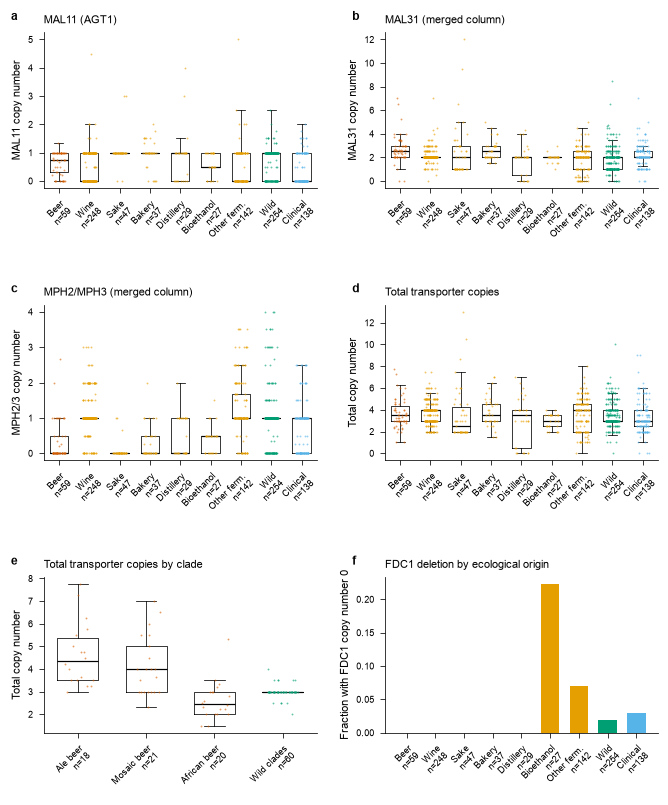

In [66]:
# Extended Data figure. Nature style: Arial 6-7 pt, 183 mm (double column) wide, bold lower-case
# panel letters, Okabe-Ito colours (colour-blind safe). I colour by role, not by group, so the
# colours carry one idea: beer (vermillion), other domesticated (orange), wild (bluish green),
# clinical (sky blue). Each point is one strain, jittered sideways so ties stay visible.
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica"],
                     "font.size": 6, "axes.labelsize": 7, "axes.titlesize": 7,
                     "axes.linewidth": 0.5, "xtick.major.width": 0.5,
                     "ytick.major.width": 0.5, "pdf.fonttype": 42, "svg.fonttype": "none"})
okabe = {"beer": "#D55E00", "dom": "#E69F00", "wild": "#009E73", "clin": "#56B4E9"}
eco_colors = {g: okabe["dom"] for g in domesticated}
eco_colors.update({"Beer": okabe["beer"], "Wild": okabe["wild"], "Clinical": okabe["clin"]})
clade_colors = {c: okabe["beer"] for c in beer_clades}
clade_colors["Wild clades"] = okabe["wild"]
rng = np.random.default_rng(0)  # fixed seed so the jitter is the same on every run
MM = 1 / 25.4                   # inches per mm

def strip_box(ax, data, col, levels, colors, gene, labels=None):
    """Draw a box plot plus jittered strain points of `gene` per level of `col`, with n under
    each tick label."""
    vals = [data.loc[data[col] == lv, gene].values for lv in levels]
    ax.boxplot(vals, positions=range(len(levels)), widths=0.6, showfliers=False,
               medianprops={"color": "black", "linewidth": 0.8},
               boxprops={"linewidth": 0.5}, whiskerprops={"linewidth": 0.5},
               capprops={"linewidth": 0.5})
    for i, (lv, v) in enumerate(zip(levels, vals)):
        ax.scatter(i + rng.uniform(-0.22, 0.22, len(v)), v, s=1.5, color=colors[lv],
                   alpha=0.6, linewidths=0, zorder=3)
    names = labels or levels
    ax.set_xticks(range(len(levels)))
    ax.set_xticklabels([f"{nm}\nn={len(v)}" for nm, v in zip(names, vals)],
                       rotation=45, ha="right", rotation_mode="anchor")
    ax.set_ylabel(f"{gene} copy number")
    ax.spines[["top", "right"]].set_visible(False)

# Three rows of two panels, so the nine group labels per panel have room (183 x 210 mm).
fig = plt.figure(figsize=(183 * MM, 210 * MM))
gs = fig.add_gridspec(3, 2, hspace=0.75, wspace=0.25)
short = {g: ("Other ferm." if g == "Other fermentation" else g) for g in group_order}
gene_titles = {"MAL11": "MAL11 (AGT1)", "MAL31": "MAL31 (merged column)",
               "MPH2/3": "MPH2/MPH3 (merged column)", "Total": "Total transporter copies"}

# Panels a-d: each transporter column and the total, by ecological origin.
for i, gene in enumerate(genes):
    ax = fig.add_subplot(gs[i // 2, i % 2])
    strip_box(ax, grouped, "group", group_order, eco_colors, gene,
              labels=[short[g] for g in group_order])
    ax.set_title(gene_titles[gene], loc="left")
    ax.text(-0.12, 1.08, "abcd"[i], transform=ax.transAxes, fontsize=8, fontweight="bold")

# Panel e: total copies in the beer clades vs the pooled wild clades, the lineage-based view.
clade_levels = beer_clades + ["Wild clades"]
ax = fig.add_subplot(gs[2, 0])
strip_box(ax, df, "clade_group", clade_levels, clade_colors, "Total",
          labels=["Ale beer", "Mosaic beer", "African beer", "Wild clades"])
ax.set_title("Total transporter copies by clade", loc="left")
ax.text(-0.12, 1.08, "e", transform=ax.transAxes, fontsize=8, fontweight="bold")

# Panel f: fraction of strains with FDC1 deleted (copy number 0), by ecological origin.
ax = fig.add_subplot(gs[2, 1])
fdc1_frac = absent_df[absent_df["gene"] == "FDC1"].set_index("group").loc[group_order]
ax.bar(range(len(group_order)), fdc1_frac["frac_absent"], width=0.65,
       color=[eco_colors[g] for g in group_order])
ax.set_xticks(range(len(group_order)))
ax.set_xticklabels([f"{short[g]}\nn={n}" for g, n in zip(group_order, fdc1_frac["n"])],
                   rotation=45, ha="right", rotation_mode="anchor")
ax.set_ylabel("Fraction with FDC1 copy number 0")
ax.set_title("FDC1 deletion by ecological origin", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.text(-0.12, 1.08, "f", transform=ax.transAxes, fontsize=8, fontweight="bold")

fig.savefig("figures/extended/ED_mal_cnv_1011.png", dpi=300, bbox_inches="tight")
fig.savefig("figures/extended/ED_mal_cnv_1011.pdf", bbox_inches="tight")
plt.show()

In [67]:
# 10. The S. eubayanus half of lager yeast: are its PAD1 / FDC1 copies intact?
# Libraries used in this section
import os, re, ast, time, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio import Entrez, SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.Align import PairwiseAligner, substitution_matrices
from Bio.Data.CodonTable import standard_dna_table

# NCBI asks every script to say who it is; the e-mail comes from the environment.
EMAIL, TOOL = os.environ.get('NCBI_EMAIL', 'anonymous@example.org'), 'bch339n_project'
Entrez.email, Entrez.tool = EMAIL, TOOL
LAGER = 'data/lager'
SE_CDS_FA = f'{LAGER}/Seub_FM1318_PAD1_FDC1_cds.fasta'   # Se reference CDSs
HITS_TSV = f'{LAGER}/lager_pad1_fdc1_blast_hits.tsv'     # raw blast2seq HSPs
BATCH_TSV = f'{LAGER}/lager_blast_batches.tsv'          # which records went in which BLAST job
LOCI_FA = f'{LAGER}/lager_pad1_fdc1_loci.fasta'          # efetched locus sequences
OUT_CSV = 'data/results/lager_subgenome_pad1_fdc1.csv'
FIG_DIR = 'figures/extended'
for d in (LAGER, FIG_DIR, 'data/results'):
    os.makedirs(d, exist_ok=True)
SE_ASSEMBLY = 'GCF_001298625.1'   # S. eubayanus FM1318 SEUB3.0 (Baker et al. 2015), RefSeq reference
SE_TAXID = 1080349                # Saccharomyces eubayanus
GENES = ['PAD1', 'FDC1']

# Thresholds (our choice). A copy belongs to a subgenome if it matches that subgenome's reference at
# >= 98 % and the other reference at < 90 %. Sc and Se orthologs are only ~78-82 % identical
# (step 2 below), so the gap between 90 and 98 leaves room for strain-level SNPs - for example a
# lager Sc copy need not be 99 % identical to the lab strain S288C. MIN_QCOV is section 2's filter.
SC_MIN_ID = 98.0
SE_MIN_ID = 98.0
OTHER_MAX_ID = 90.0
MIN_QCOV = 0.7
BLAST_EVALUE = '1e-5'   # sensitive on purpose: a missing copy must not be a search artefact
PAD_NT = 30        # extra flank fetched on each side so indels near the CDS ends are not cut off
DATE = '2026-11-18'

In [68]:
def add_manifest(source, acc_or_url, path, notes):
    """Append one row to data/MANIFEST.csv for a cached file, unless that path is already logged."""
    man = pd.read_csv('data/MANIFEST.csv')
    if path in set(man.local_path):
        return
    sha = hashlib.sha256(open(path, 'rb').read()).hexdigest()
    row = dict(source=source, accession_or_url=acc_or_url, local_path=path,
               date_downloaded=DATE, sha256=sha, notes=notes)
    pd.concat([man, pd.DataFrame([row])]).to_csv('data/MANIFEST.csv', index=False)

# Step 0: the S288C reference CDSs (same files section 3 uses).
sc_cds = {g: str(next(SeqIO.parse(f'data/reference/{g}_cds.fasta', 'fasta')).seq).upper()
          for g in GENES}
print('S288C CDS lengths (nt):', {g: len(s) for g, s in sc_cds.items()})

S288C CDS lengths (nt): {'PAD1': 729, 'FDC1': 1512}


In [69]:
# 10.1 S. eubayanus reference CDSs
# Step 1: find the Se PAD1/FDC1 genes in NCBI Gene and fetch their CDS (cached).
if not os.path.exists(SE_CDS_FA):
    term = f'txid{SE_TAXID}[orgn] AND (PAD1[sym] OR FDC1[sym])'
    ids = Entrez.read(Entrez.esearch(db='gene', term=term, retmax=10))['IdList']
    summ = Entrez.read(Entrez.esummary(db='gene', id=','.join(ids)), validate=False)
    recs = []
    for d in summ['DocumentSummarySet']['DocumentSummary']:
        gi = d['GenomicInfo'][0]
        a, b = int(gi['ChrStart']), int(gi['ChrStop'])
        strand = 1 if b > a else 2             # NCBI Gene lists minus-strand genes as start > stop
        lo, hi = min(a, b) + 1, max(a, b) + 1  # 0-based -> 1-based
        fa = Entrez.efetch(db='nuccore', id=gi['ChrAccVer'], rettype='fasta', retmode='text',
                           seq_start=lo, seq_stop=hi, strand=strand).read()
        seq = ''.join(fa.split('\n')[1:]).strip()
        desc = (f"{gi['ChrAccVer']}:{lo}-{hi} strand={strand} GeneID:{d.attributes['uid']} "
                f"locus_tag:{d['OtherAliases']} chromosome {d['Chromosome']} {d['Description']}")
        recs.append(f">Se_{d['Name']} {desc}\n{seq}\n")
        time.sleep(0.4)
    open(SE_CDS_FA, 'w').write(''.join(recs))
add_manifest('NCBI Gene + nuccore (S. eubayanus FM1318, RefSeq ' + SE_ASSEMBLY + ', Baker et al. 2015)',
             'Entrez gene esearch txid1080349 PAD1/FDC1 -> efetch nuccore CDS ranges',
             SE_CDS_FA, 'S. eubayanus PAD1 (DI49_4415) and FDC1 (DI49_4416) CDS')
se_recs = {r.id.split('_')[1]: r for r in SeqIO.parse(SE_CDS_FA, 'fasta')}
se_cds = {g: str(se_recs[g].seq).upper() for g in GENES}
for g in GENES:
    print(f'Se {g}:', se_recs[g].description)

# Check that what I fetched really is a CDS: a multiple of 3, starts ATG, ends in a stop and has no
# internal stop. If the 0/1-based conversion were wrong, these would fail.
for g, s in se_cds.items():
    p = str(Seq(s).translate())
    assert len(s) % 3 == 0 and s.startswith('ATG') and p.endswith('*') and p.count('*') == 1, g

Se PAD1: Se_PAD1 NC_030972.1:934704-935432 strand=1 GeneID:28933552 locus_tag:DI49_4415 chromosome XIII phenylacrylic acid decarboxylase PAD1
Se FDC1: Se_FDC1 NC_030972.1:935885-937396 strand=1 GeneID:28933553 locus_tag:DI49_4416 chromosome XIII putative phenylacrylic acid decarboxylase FDC1


In [70]:
# Step 2: how far apart are the Sc and Se orthologs? I use the class-style global aligner
# (attribute style, BLOSUM62 / open -10 / extend -1 as in the student's HW04, lecture_08.md).
prot_class = PairwiseAligner()
prot_class.mode = 'global'
prot_class.substitution_matrix = substitution_matrices.load('BLOSUM62')
prot_class.open_gap_score = -10
prot_class.extend_gap_score = -1

def pct_id(aln):
    """Percent identity over aligned (non-gap) columns of a 2-row alignment."""
    cols = [(x, y) for x, y in zip(aln[0], aln[1]) if x != '-' and y != '-']
    return 100 * sum(x == y for x, y in cols) / len(cols)

# Nucleotide aligner: same scoring as section 3 (match 2, mismatch -3, open -10, extend -1).
nt_class = PairwiseAligner(mode='global', match_score=2, mismatch_score=-3,
                           open_gap_score=-10, extend_gap_score=-1)
sc_se = []
for g in GENES:
    nt = pct_id(nt_class.align(sc_cds[g], se_cds[g])[0])
    aa = pct_id(prot_class.align(str(Seq(sc_cds[g]).translate(to_stop=True)),
                                 str(Seq(se_cds[g]).translate(to_stop=True)))[0])
    sc_se.append(dict(gene=g, sc_len_nt=len(sc_cds[g]), se_len_nt=len(se_cds[g]),
                      nt_identity=round(nt, 2), aa_identity=round(aa, 2)))
    RESULTS[f'a5_sc_vs_se_{g}_nt_identity_pct'] = round(nt, 2)
    RESULTS[f'a5_sc_vs_se_{g}_aa_identity_pct'] = round(aa, 2)
# The two orthologs should be clearly different (~80-90 %), otherwise BLAST could not tell
# the subgenomes apart by identity.
assert all(r['nt_identity'] < SE_MIN_ID for r in sc_se), 'Sc and Se references are too similar'

# Step 3: where do the Se genes sit on their chromosome? A gene close to a chromosome end lives in a
# subtelomeric region, which is more often lost or rearranged, so I note the distance to the end.
se_chr = se_recs['FDC1'].description.split(' ')[1].split(':')[0]
se_chr_len = int(Entrez.read(Entrez.esummary(db='nuccore', id=se_chr))[0]['Length'])
se_end = max(int(se_recs[g].description.split(':')[1].split('-')[1].split(' ')[0]) for g in GENES)
print(f'Se reference chromosome {se_chr} length (nt): {se_chr_len}')
print(f'Distance from Se PAD1-FDC1 cluster to the chromosome end (nt): {se_chr_len - se_end}')
RESULTS['a5_se_ref_cluster_to_chr_end_nt'] = se_chr_len - se_end
pd.DataFrame(sc_se)

Se reference chromosome NC_030972.1 length (nt): 953685
Distance from Se PAD1-FDC1 cluster to the chromosome end (nt): 16289


,gene,sc_len_nt,se_len_nt,nt_identity,aa_identity
0,PAD1,729,729,78.05,83.06
1,FDC1,1512,1512,81.68,88.27


In [71]:
# 10.2 BLAST both references against each lager assembly
strains_cnv = pd.read_csv('data/cnv/complete_genome_strains.csv')
lagers = strains_cnv[strains_cnv.group == 'Lager'].reset_index(drop=True)
# The task names exactly these two assemblies; stop if the strain table ever changes under us.
assert sorted(lagers.assembly_accession) == ['GCA_011022315.1', 'GCA_056824455.1'], lagers
acc2strain = {a: r.strain for r in lagers.itertuples() for a in r.nuccore_accessions.split(';')}

def blast2seq(query_fasta, subject_accs):
    """Run one blastn align-two-sequences job on NCBI and return the tabular HSP rows."""
    import requests
    url = 'https://blast.ncbi.nlm.nih.gov/'
    put = requests.post(url + 'BlastAlign.cgi', data=dict(
        CMD='Put', PROGRAM='blastn', BLAST_SPEC='blast2seq', QUERY=query_fasta,
        SUBJECTS='\n'.join(subject_accs), EXPECT=BLAST_EVALUE, HITLIST_SIZE=500,
        EMAIL=EMAIL, TOOL=TOOL)).text
    rid = re.search(r'name="RID" value="(\w+)"', put).group(1)
    # NCBI asks clients to poll no faster than every ~10 s
    while True:
        time.sleep(15)
        info = requests.get(url + 'Blast.cgi', params=dict(
            CMD='Get', FORMAT_OBJECT='SearchInfo', RID=rid)).text
        if 'Status=READY' in info:
            break
        if 'Status=WAITING' not in info:
            raise RuntimeError(rid + ' failed')
    txt = requests.get(url + 'Blast.cgi', params=dict(
        CMD='Get', FORMAT_TYPE='Text', ALIGNMENT_VIEW='Tabular', DESCRIPTIONS=5000,
        ALIGNMENTS=5000, RID=rid)).text
    return [l.split('\t') for l in txt.splitlines()
            if re.match(r'^\S+\t', l) and not l.startswith('#')]

queries = {f'Sc_{g}': sc_cds[g] for g in GENES} | {f'Se_{g}': se_cds[g] for g in GENES}
# Positive control: section 2's MAL/MPH queries hit chromosomes of both subgenomes in these lagers.
# If a batch returns no control hit, that batch was not really searched and "absent" means nothing.
ctrl = {f'CTRL_{r.id.split("_")[0]}': str(r.seq)
        for r in SeqIO.parse('data/cnv/mal_query_cds.fasta', 'fasta')}
QLEN = {q: len(s) for q, s in (queries | ctrl).items()}

# Step 3: BLAST (cached). If the TSV exists I skip the network entirely.
if not os.path.exists(HITS_TSV):
    qfa = ''.join(f'>{q}\n{s}\n' for q, s in (queries | ctrl).items())
    rows, batch_rows = [], []
    for r in lagers.itertuples():
        accs = r.nuccore_accessions.split(';')
        summ = Entrez.read(Entrez.esummary(db='nuccore', id=','.join(accs)))
        size = {d['AccessionVersion']: int(d['Length']) for d in summ}
        title = {d['AccessionVersion']: d['Title'] for d in summ}
        # first-fit packing, largest records first (bl2seq subject limit is 10 Mb)
        batches = []
        for a in sorted(accs, key=size.get, reverse=True):
            b = next((b for b in batches if b[0] + size[a] <= 9.5e6), None)
            if b is None:
                b = [0, []]
                batches.append(b)
            b[0] += size[a]
            b[1].append(a)
        for bi, (_, batch) in enumerate(batches):
            bid = f"{r.strain.replace(' ', '')}_b{bi}"
            batch_rows.append(dict(strain=r.strain, batch=bid, accessions=';'.join(batch)))
            for h in blast2seq(qfa, batch):
                rows.append(h[:12] + [title.get(h[1], ''), bid])
            time.sleep(10)
    cols = 'query sacc pident length mismatch gapopen qstart qend sstart send evalue bitscore title batch'
    pd.DataFrame(rows, columns=cols.split()).to_csv(HITS_TSV, sep='\t', index=False)
    pd.DataFrame(batch_rows).to_csv(BATCH_TSV, sep='\t', index=False)
add_manifest('NCBI BLAST URL API (blastn, BLAST_SPEC=blast2seq)',
             'https://blast.ncbi.nlm.nih.gov/BlastAlign.cgi; subjects = nuccore records of '
             'GCA_011022315.1 (CBS 1483) and GCA_056824455.1 (CBS 1513)', HITS_TSV,
             'S288C + S. eubayanus FM1318 PAD1/FDC1 CDS + MAL/MPH control CDS vs lager '
             'chromosomes; blastn E<=1e-5')
add_manifest('NCBI BLAST URL API (job log)', 'https://blast.ncbi.nlm.nih.gov/BlastAlign.cgi',
             BATCH_TSV, 'which nuccore records were packed into each blast2seq job (<=9.5 Mb)')
hits_all = pd.read_csv(HITS_TSV, sep='\t')
batches_df = pd.read_csv(BATCH_TSV, sep='\t')
# every record of both assemblies must have been in exactly one batch
assert sorted(';'.join(batches_df.accessions).split(';')) == sorted(acc2strain), 'records missing'
ctrl_per_batch = (hits_all[hits_all['query'].str.startswith('CTRL_')].groupby('batch').size()
                  .reindex(batches_df.batch, fill_value=0))
print('Control (MAL/MPH) HSPs per BLAST batch:', ctrl_per_batch.to_dict())
assert (ctrl_per_batch > 0).all(), 'a BLAST batch returned no control hit - search not trustworthy'
RESULTS['a5_blast_batches_with_control_hit'] = f'{(ctrl_per_batch > 0).sum()}/{len(ctrl_per_batch)}'
hits = hits_all[~hits_all['query'].str.startswith('CTRL_')].copy()
hits['strain'] = hits.sacc.map(acc2strain)
hits['gene'] = hits['query'].str.split('_').str[1]
hits['qcov'] = (hits.qend - hits.qstart + 1) / hits['query'].map(QLEN)
print('HSPs (all):', len(hits))
hits[['query', 'strain', 'sacc', 'pident', 'length', 'qcov', 'sstart', 'send', 'title']].round(3)

Control (MAL/MPH) HSPs per BLAST batch: {'CBS1483_b0': 20, 'CBS1483_b1': 11, 'CBS1483_b2': 10, 'CBS1513_b0': 32, 'CBS1513_b1': 16, 'CBS1513_b2': 10}
HSPs (all): 4


,query,strain,sacc,pident,length,qcov,sstart,send,title
0,Sc_PAD1,CBS 1483,CP048985.1,98.903,729,1.000,1460290,1461018,Saccharomyces pastorianus strain CBS 1483 chromosome ScIV
1,Sc_FDC1,CBS 1483,CP048985.1,99.736,1513,1.000,1461482,1462994,Saccharomyces pastorianus strain CBS 1483 chromosome ScIV
2,Se_PAD1,CBS 1483,CP048985.1,77.610,728,0.999,1460290,1461017,Saccharomyces pastorianus strain CBS 1483 chromosome ScIV
3,Se_FDC1,CBS 1483,CP048985.1,81.727,1494,0.987,1461497,1462990,Saccharomyces pastorianus strain CBS 1483 chromosome ScIV


In [72]:
# 10.3 Assign each locus to a subgenome
# Step 1: keep near-full-length HSPs (same coverage cut as section 2).
keep = hits[hits.qcov >= MIN_QCOV].copy()
keep['lo'] = keep[['sstart', 'send']].min(axis=1)
keep['hi'] = keep[['sstart', 'send']].max(axis=1)

# Step 2: merge overlapping HSPs of the same gene on the same record into loci.
loci = []
for h in keep.sort_values('bitscore', ascending=False).itertuples():
    L = next((L for L in loci if L['sacc'] == h.sacc and L['gene'] == h.gene
              and min(L['hi'], h.hi) > max(L['lo'], h.lo)), None)
    if L is None:
        L = dict(strain=h.strain, gene=h.gene, sacc=h.sacc, title=h.title, lo=h.lo, hi=h.hi,
                 best=h, id_vs_Sc=np.nan, id_vs_Se=np.nan)
        loci.append(L)
    sp = h.query.split('_')[0]
    L[f'id_vs_{sp}'] = np.nanmax([L[f'id_vs_{sp}'], h.pident])

# Step 3: the subgenome call from identity alone, plus the title's chromosome label as a check.
for L in loci:
    # a missing identity (no HSP of that query at this locus) counts as 0.
    sc_id, se_id = np.nan_to_num(L['id_vs_Sc']), np.nan_to_num(L['id_vs_Se'])
    sc_ok = sc_id >= SC_MIN_ID and se_id < OTHER_MAX_ID
    se_ok = se_id >= SE_MIN_ID and sc_id < OTHER_MAX_ID
    L['subgenome'] = 'Sc' if sc_ok else 'Se' if se_ok else 'ambiguous'
    L['chromosome_label'] = re.search(r'chromosome (\S+)', L['title']).group(1)
loci_df = pd.DataFrame(loci)
print('Loci found:', len(loci_df))
# An ambiguous locus would mean the identity rule cannot separate the subgenomes - stop and look.
assert (loci_df.subgenome != 'ambiguous').all(), loci_df[['strain', 'gene', 'id_vs_Sc', 'id_vs_Se']]
loci_df[['strain', 'gene', 'subgenome', 'sacc', 'chromosome_label', 'lo', 'hi',
         'id_vs_Sc', 'id_vs_Se']]

Loci found: 2


,strain,gene,subgenome,sacc,chromosome_label,lo,hi,id_vs_Sc,id_vs_Se
0,CBS 1483,FDC1,Sc,CP048985.1,ScIV,1461482,1462994,99.736,81.727
1,CBS 1483,PAD1,Sc,CP048985.1,ScIV,1460290,1461018,98.903,77.610


In [73]:
# 10.4 Extract each copy and call intact vs loss-of-function
# Step 1: pull the allele-caller definitions out of section 3's source (functions + aligner setup).
WANT = {'aa_of', 'right_shift_ins', 'right_shift_del', 'call_allele'}
tree3 = ast.parse(open('src/yeastflavor/03_variant_calling.py', encoding='utf-8').read())
nodes = [n for n in tree3.body
         if (isinstance(n, ast.FunctionDef) and n.name in WANT)
         or (isinstance(n, ast.Assign) and re.match(r'(nt_aligner|prot_aligner|CODON)\b',
                                                    ast.unparse(n.targets[0])))]
exec(compile(ast.Module(body=nodes, type_ignores=[]), '03_variant_calling.py', 'exec'), globals())
assert all(k in globals() for k in WANT | {'nt_aligner', 'prot_aligner', 'CODON'})

# call_allele looks its reference up in ref_cds / ref_prot by name, so I key them per subgenome.
ref_cds = {f'{sp}_{g}': s for sp, d in (('Sc', sc_cds), ('Se', se_cds)) for g, s in d.items()}
ref_prot = {k: str(Seq(s).translate(to_stop=True)) for k, s in ref_cds.items()}

# Step 2: fetch each locus (cached as one FASTA, ids = strain|gene|subgenome).
def locus_range(L):
    """Full-CDS range (1-based, padded) and efetch strand for a locus from its best HSP."""
    h = L['best']
    ql = QLEN[h.query]
    if h.send > h.sstart:   # plus strand
        return h.sstart - (h.qstart - 1) - PAD_NT, h.send + (ql - h.qend) + PAD_NT, 1
    return h.send - (ql - h.qend) - PAD_NT, h.sstart + (h.qstart - 1) + PAD_NT, 2

loci_df['key'] = loci_df.strain + '|' + loci_df.gene + '|' + loci_df.subgenome
if not os.path.exists(LOCI_FA):
    out = []
    for L in loci_df.itertuples():
        lo, hi, strand = locus_range(L._asdict())
        fa = Entrez.efetch(db='nuccore', id=L.sacc, rettype='fasta', retmode='text',
                           seq_start=lo, seq_stop=hi, strand=strand).read()
        out.append(f">{L.key.replace(' ', '_')} {L.sacc}:{lo}-{hi} strand={strand}\n"
                   + ''.join(fa.split('\n')[1:]).strip() + '\n')
        time.sleep(0.4)
    open(LOCI_FA, 'w').write(''.join(out))
add_manifest('NCBI nuccore efetch (lager PAD1/FDC1 loci)',
             'Entrez efetch nuccore seq_start/seq_stop/strand on CP0489xx / CP1500xx records',
             LOCI_FA, 'Sc and Se PAD1/FDC1 loci +-30 nt from CBS 1483 and CBS 1513')
loc_seqs = {r.id.replace('_', ' ', 1) if r.id.startswith('CBS_') else r.id: r
            for r in SeqIO.parse(LOCI_FA, 'fasta')}
assert set(loc_seqs) == set(loci_df.key), 'cached loci FASTA does not match the BLAST loci'

# Step 3: run the section-3 caller on each copy. I strip the description so the PARTIAL/N flags of
# section 3 (which come from GenBank titles) do not apply - these are complete-genome records.
calls = []
for L in loci_df.itertuples():
    rec = loc_seqs[L.key]
    variants, sm, protein, aln = call_allele(f'{L.subgenome}_{L.gene}', SeqRecord(rec.seq, id=rec.id,
                                                                                  description=''))
    fs_or_stop = [v['hgvs_c'] + ' ' + v['protein_change'] for v in variants
                  if v.get('effect') in ('frameshift', 'nonsense')]
    calls.append(dict(strain=L.strain, gene=L.gene, subgenome=L.subgenome, sacc=L.sacc,
                      chromosome_label=L.chromosome_label, region=rec.description.split(' ')[1],
                      cds_start=L.lo, cds_end=L.hi,
                      blast_id_vs_Sc_ref=L.id_vs_Sc, blast_id_vs_Se_ref=L.id_vs_Se,
                      reference=f'{L.subgenome}_{L.gene}', ref_len_aa=len(ref_prot[f'{L.subgenome}_{L.gene}']),
                      nt_identity_to_ref=sm['pct_identity'], protein_len_aa=sm['protein_len'],
                      frameshift=sm['frameshift'], n_missense=sm['n_missense'],
                      protein_identity_to_ref=sm['protein_pct_identity'],
                      lof_variants='; '.join(fs_or_stop), call=sm['LOF_call']))
calls_df = pd.DataFrame(calls)

# Step 4: make the table complete - one row per strain x gene x subgenome, 'absent' if no locus.
grid = pd.MultiIndex.from_product([lagers.strain, GENES, ['Sc', 'Se']],
                                  names=['strain', 'gene', 'subgenome']).to_frame(index=False)
status = grid.merge(calls_df, how='left', on=['strain', 'gene', 'subgenome'])
status['call'] = status['call'].fillna('absent')
status.to_csv(OUT_CSV, index=False)
print('Saved:', OUT_CSV)
status[['strain', 'gene', 'subgenome', 'chromosome_label', 'cds_start', 'cds_end',
        'nt_identity_to_ref', 'protein_len_aa', 'ref_len_aa', 'lof_variants', 'call']]

Saved: data/results/lager_subgenome_pad1_fdc1.csv


,strain,gene,subgenome,chromosome_label,cds_start,cds_end,nt_identity_to_ref,protein_len_aa,ref_len_aa,lof_variants,call
0,CBS 1483,PAD1,Sc,ScIV,1460290.0,1461018.0,98.903,242.0,242.0,,intact
1,CBS 1483,PAD1,Se,NaN,NaN,NaN,NaN,NaN,NaN,NaN,absent
2,CBS 1483,FDC1,Sc,ScIV,1461482.0,1462994.0,99.736,169.0,503.0,c.501dupA p.K167fs,LOF
3,CBS 1483,FDC1,Se,NaN,NaN,NaN,NaN,NaN,NaN,NaN,absent
4,CBS 1513,PAD1,Sc,NaN,NaN,NaN,NaN,NaN,NaN,NaN,absent
5,CBS 1513,PAD1,Se,NaN,NaN,NaN,NaN,NaN,NaN,NaN,absent
6,CBS 1513,FDC1,Sc,NaN,NaN,NaN,NaN,NaN,NaN,NaN,absent
7,CBS 1513,FDC1,Se,NaN,NaN,NaN,NaN,NaN,NaN,NaN,absent


In [74]:
# Step 5: for a strain with no Sc copy, I list its chromosome-IV records (Sc PAD1/FDC1 sit near the
# right end of chromosome IV in S288C), because a translocation in the title would explain a loss.
for st in status[(status.subgenome == 'Sc') & (status.call == 'absent')].strain.unique():
    accs = lagers.set_index('strain').loc[st, 'nuccore_accessions'].split(';')
    for d in Entrez.read(Entrez.esummary(db='nuccore', id=','.join(accs))):
        if re.search(r'chromosome \S*ScIV\b', d['Title']):
            print(f"{st} chromosome IV record: {d['AccessionVersion']} {d['Title']} "
                  f"({int(d['Length'])} nt)")

CBS 1513 chromosome IV record: CP150027.1 Saccharomyces pastorianus strain CBS 1513 chromosome ScIV-SeII (1466191 nt)


In [75]:
# Step 6: checks and the citable numbers.
# 1) Section 3 found FDC1 c.501dupA in lager alleles; the Sc FDC1 copy here should carry it too.
sc_fdc1 = status[(status.gene == 'FDC1') & (status.subgenome == 'Sc')]
for r in sc_fdc1[sc_fdc1.call != 'absent'].itertuples():
    has_dup = isinstance(r.lof_variants, str) and 'c.501dupA' in r.lof_variants
    print(f'{r.strain} Sc FDC1 carries c.501dupA:', has_dup)
    RESULTS[f"a5_{r.strain.replace(' ', '')}_Sc_FDC1_c501dupA"] = has_dup
# 2) one number per strain x gene x subgenome
for r in status.itertuples():
    k = f"a5_{r.strain.replace(' ', '')}_{r.subgenome}_{r.gene}"
    RESULTS[k + '_call'] = r.call
    if r.call != 'absent':
        RESULTS[k + '_locus'] = f'{r.sacc}:{int(r.cds_start)}-{int(r.cds_end)}'
        RESULTS[k + '_protein_len_aa'] = int(r.protein_len_aa)
        RESULTS[k + '_nt_identity_to_ref_pct'] = float(r.nt_identity_to_ref)
RESULTS['a5_se_reference_assembly'] = SE_ASSEMBLY
RESULTS['a5_se_reference_loci'] = {g: se_recs[g].description.split(' ')[1] for g in GENES}
RESULTS['a5_n_se_copies_intact'] = int(((status.subgenome == 'Se') & (status.call == 'intact')).sum())
RESULTS['a5_n_se_copies_lof'] = int(((status.subgenome == 'Se') & (status.call == 'LOF')).sum())
RESULTS['a5_n_se_copies_absent'] = int(((status.subgenome == 'Se') & (status.call == 'absent')).sum())
print('Se copies intact / LOF / absent:', RESULTS['a5_n_se_copies_intact'],
      RESULTS['a5_n_se_copies_lof'], RESULTS['a5_n_se_copies_absent'])

CBS 1483 Sc FDC1 carries c.501dupA: True
Se copies intact / LOF / absent: 0 0 4


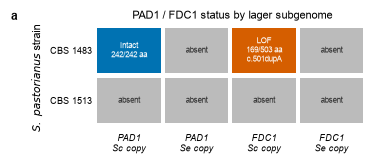

In [76]:
# Extended Data figure: subgenome status grid
# Nature Extended Data style: Arial 6-7 pt, 89 mm single column, bold lowercase panel label.
plt.rcParams.update({'font.family': 'Arial', 'font.size': 6, 'axes.linewidth': 0.5,
                     'pdf.fonttype': 42})
CALL_COL = {'intact': '#0072B2', 'LOF': '#D55E00', 'absent': '#BBBBBB'}   # Okabe-Ito blue / vermillion
cols = [(g, sp) for g in GENES for sp in ('Sc', 'Se')]
strains_order = list(lagers.strain)
mm = 1 / 25.4
fig, ax = plt.subplots(figsize=(89 * mm, 38 * mm))
for i, st in enumerate(strains_order):
    for j, (g, sp) in enumerate(cols):
        r = status[(status.strain == st) & (status.gene == g) & (status.subgenome == sp)].iloc[0]
        ax.add_patch(plt.Rectangle((j, i), 0.94, 0.9, color=CALL_COL[r.call], lw=0))
        txt = r.call if r.call == 'absent' else f'{r.call}\n{int(r.protein_len_aa)}/{int(r.ref_len_aa)} aa'
        if r.call == 'LOF' and isinstance(r.lof_variants, str) and r.lof_variants:
            txt += '\n' + r.lof_variants.split(';')[0].split(' ')[0]
        # white text is unreadable on the light grey 'absent' cells, so those get dark text
        ax.text(j + 0.47, i + 0.45, txt, ha='center', va='center', fontsize=5.5,
                color='#333333' if r.call == 'absent' else 'white')
ax.set_xlim(0, len(cols))
ax.set_ylim(len(strains_order), 0)
ax.set_xticks([j + 0.47 for j in range(len(cols))])
ax.set_xticklabels([f'{g}\n{sp} copy' for g, sp in cols], fontstyle='italic')
ax.set_yticks([i + 0.45 for i in range(len(strains_order))])
ax.set_yticklabels(strains_order)
ax.set_ylabel(r'$\it{S.\ pastorianus}$ strain')   # mathtext so only the species name is italic
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title('PAD1 / FDC1 status by lager subgenome', fontsize=7)
ax.text(-0.32, 1.08, 'a', transform=ax.transAxes, fontsize=8, fontweight='bold')
plt.tight_layout()
for ext in ('png', 'pdf'):
    fig.savefig(f'{FIG_DIR}/ED_lager_subgenome.{ext}', dpi=300)
plt.show()

In [77]:
# 11. Collect the core numbers into results/results.json
import pandas as pd
from Bio import Phylo

RES = "data/results"

# Step 1: dataset size (strains with a genotype row, records per gene, callable records).
geno = pd.read_csv(f"{RES}/pof_genotype_by_strain.csv")
alle = pd.read_csv(f"{RES}/allele_summary.csv")
RESULTS.update({
    "core_n_strains": int(len(geno)),
    "core_n_records": {g: int((alle.gene == g).sum()) for g in ["PAD1", "FDC1"]},
    "core_n_callable": {g: int(((alle.gene == g) & alle.callable).sum()) for g in ["PAD1", "FDC1"]},
    "core_pof_calls": {k: int(v) for k, v in geno.predicted_POF.value_counts().items()},
    "core_genotype_class": {k: int(v) for k, v in geno.genotype_class.value_counts().items()},
})

# Step 2: the strain-level enrichment tests from section 3.6 (kept, but quoted with the relatedness caveat).
enr = pd.read_csv(f"{RES}/lof_enrichment_tests.csv")
for key, row in zip(["core_fisher_domestic", "core_fisher_beer", "core_chi2_all"], enr.itertuples()):
    RESULTS[key] = {k: (None if pd.isna(v) else float(v)) for k, v in row._asdict().items() if k not in ("Index", "test")}
    RESULTS[key]["test"] = row.test

# Step 3: POF- fraction per ecological group (the numbers behind the enrichment bar chart).
called = geno[geno.predicted_POF.isin(["POF-", "POF+"])]
RESULTS["core_pofneg_by_group"] = {g: {"n": int(len(d)), "pof_neg": int((d.predicted_POF == "POF-").sum())}
                                   for g, d in called.groupby("group")}

# Step 4: recurrent alleles and the Mertens comparison (share of POF- Gallone beers carrying FDC1 Q154*).
rec = pd.read_csv(f"{RES}/recurrent_lof_alleles.csv")
RESULTS["core_recurrent_alleles"] = rec[["gene", "hgvs_c", "protein_change", "n_strains", "n_called_LOF", "groups"]].to_dict("records")
vc = pd.read_csv(f"{RES}/variant_calls.csv")
bneg = set(geno[(geno.group == "Beer (Gallone)") & (geno.predicted_POF == "POF-")].strain)
q154 = set(vc[(vc.gene == "FDC1") & (vc.hgvs_c == "c.460C>T")].strain)
RESULTS["core_q154_in_pofneg_beer"] = {"k": len(bneg & q154), "n": len(bneg)}
assert RESULTS["core_q154_in_pofneg_beer"]["n"] > 0, "no POF- Gallone beers found - check step 03 output"

# Step 5: well-supported clades on the haplotype NJ tree (>= 70% bootstrap is the usual cut-off) and what
# strains they hold, so the paper can quote "91% bootstrap" with its contents.
hap = pd.read_csv(f"{RES}/PAD1_FDC1_haplotypes.csv")
tree = Phylo.read(f"{RES}/PAD1_FDC1_haplotype_nj_bootstrap.nwk", "newick")
BOOT_MIN = 70
n_tips = len(tree.get_terminals())
strong = []
for c in tree.get_nonterminals():
    if c.confidence is not None and c.confidence >= BOOT_MIN and len(c.get_terminals()) < n_tips:
        sub = hap[hap.haplotype.isin([int(t.name[1:]) for t in c.get_terminals()])]
        strong.append({"support": float(c.confidence), "n_haplotypes": len(c.get_terminals()), "n_strains": int(len(sub)),
                       "groups": {k: int(v) for k, v in sub.group.value_counts().items()},
                       "POF": {k: int(v) for k, v in sub.POF.value_counts().items()},
                       "LOF_alleles": sorted({x for x in sub.LOF_allele.dropna()})})
RESULTS["core_boot_clades"] = sorted(strong, key=lambda d: -d["support"])
RESULTS["core_n_haplotypes"] = int(hap.haplotype.nunique())

# Step 6: structural context of each truncation (how much protein is left, how many cofactor/metal/active-site
# residues are lost).
st = pd.read_csv(f"{RES}/structure_lof_context.csv")
RESULTS["core_structure"] = st[["gene", "allele", "native_residues", "fraction_retained", "LOF_called",
                                "n_binding_residues_lost", "n_binding_residues_total"]].to_dict("records")

# Step 7: the original assembly-based MAL/MPH copy-number comparison (superseded by step 09, kept for Methods).
mal = pd.read_csv(f"{RES}/mal_cnv_comparison.csv")
RESULTS["core_mal_assembly"] = mal.to_dict("records")
print(f"RESULTS now holds {len(RESULTS)} keys")
sorted(RESULTS)

RESULTS now holds 327 keys


['a1_breslow_day_p', 'a1_clade_frac_pofneg', 'a1_clade_n', 'a1_cmh_chi2', 'a1_cmh_n_contributing', 'a1_cmh_n_dom_higher', 'a1_cmh_n_strains', 'a1_cmh_n_strata', 'a1_cmh_or', 'a1_cmh_or_ci', 'a1_cmh_p', 'a1_cmh_strata', 'a1_gallone_fisher_or', 'a1_gallone_fisher_p', 'a1_gallone_n_called', 'a1_gallone_table', 'a1_n_clades', 'a1_n_pofneg_clades', 'a1_pofneg_clades', 'a2_alleles', 'a2_loss_events', 'a2_missing_from_tree', 'a2_n_beverage_loss_events', 'a2_n_distinct_lof', 'a2_n_haplotypes', 'a2_n_late_stops', 'a2_n_loss_events', 'a2_n_pofneg_haplotypes', 'a2_pof_parsimony_changes', 'a2_tree_root', 'a3_accuracy', 'a3_allele_pheno', 'a3_confusion', 'a3_discordant', 'a3_kappa', 'a3_lone_dupA', 'a3_n_ambiguous_pheno', 'a3_n_compared', 'a3_n_phenotyped', 'a3_npv', 'a3_ppv', 'a3_sensitivity', 'a3_sensitivity_rules', 'a3_specificity', 'a3_w497', 'a4_african_beer_clade_vs_wild_clades_mal11_cliffs_delta', 'a4_african_beer_clade_vs_wild_clades_mal11_p', 'a4_african_beer_clade_vs_wild_clades_mal11_p_b

In [78]:
# 12. Main figures (Nature format)
import io, json, os, re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from Bio import Phylo
from Bio.PDB import PDBParser
from statsmodels.stats.proportion import proportion_confint

RES, OUT = "data/results", "figures/main"
os.makedirs(OUT, exist_ok=True)
MM = 1 / 25.4                       # matplotlib sizes are in inches; Nature gives widths in mm
W2, W1 = 183 * MM, 89 * MM

# Okabe-Ito colours. I checked this exact set with the dataviz palette validator (all checks pass; the
# light ones need direct labels, which every panel has).
C = {"neg": "#D55E00", "pos": "#0072B2", "green": "#009E73", "orange": "#E69F00", "pink": "#CC79A7",
     "sky": "#56B4E9", "grey": "#9a9a9a", "light": "#e6e6e6", "ink": "#222222"}
mpl.rcParams.update({
    "font.family": "Arial", "font.size": 6, "axes.titlesize": 6.5, "axes.labelsize": 6,
    "xtick.labelsize": 5.5, "ytick.labelsize": 5.5, "legend.fontsize": 5.5, "axes.linewidth": 0.5,
    "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2, "ytick.major.size": 2,
    "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "svg.fonttype": "none",
    "savefig.dpi": 300, "mathtext.default": "regular", "figure.dpi": 150, "lines.linewidth": 0.8,
})

def panel(ax_or_fig, letter, x=-0.12, y=1.04):
    """Put a bold lowercase panel letter at the top-left of an axes (axes coordinates)."""
    ax_or_fig.text(x, y, letter, transform=ax_or_fig.transAxes, fontsize=8, fontweight="bold", va="bottom", ha="left")

def save(fig, name):
    """Save one figure as vector PDF and 300-dpi PNG in figures/main/."""
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", bbox_inches="tight", pad_inches=0.02)
    print(f"saved {OUT}/{name}.pdf/.png  ({fig.get_size_inches()[0] / MM:.0f} mm wide)")

R = RESULTS  # every number on the figures comes from here
geno = pd.read_csv(f"{RES}/pof_genotype_by_strain.csv")
vc = pd.read_csv(f"{RES}/variant_calls.csv")
uni = json.load(open("data/structure/uniprot_features.json"))

saved figures/main/Fig1_pathway_design.pdf/.png  (183 mm wide)


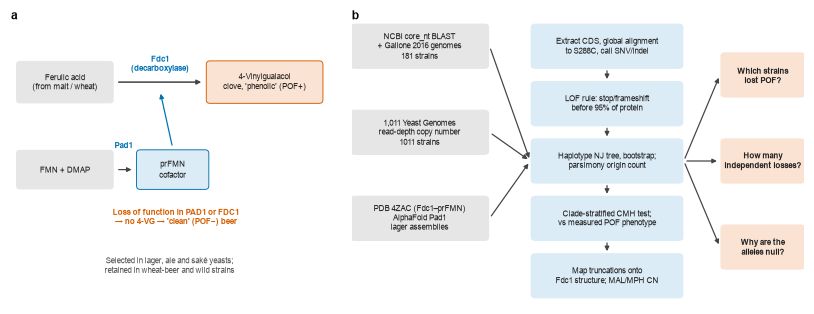

In [79]:
# Figure 1 — the pathway and the study design (schematic)
def box(ax, x, y, w, h, text, fc, ec="none", fs=5.5, color="#222222", weight="normal"):
    """Rounded text box in data coordinates (0-1 axes)."""
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.004,rounding_size=0.012", fc=fc, ec=ec, lw=0.6))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color=color, weight=weight, linespacing=1.25)

def arrow(ax, x0, y0, x1, y1, color="#444444", lw=0.8):
    """Simple straight arrow between two points."""
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, mutation_scale=6))

fig = plt.figure(figsize=(W2, 72 * MM))
axA = fig.add_axes([0.0, 0.0, 0.40, 0.92]); axB = fig.add_axes([0.43, 0.0, 0.57, 0.92])
for ax in (axA, axB):
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")

# a: ferulic acid -> 4-vinylguaiacol needs Fdc1 AND the prFMN cofactor made by Pad1
box(axA, 0.02, 0.70, 0.30, 0.14, "Ferulic acid\n(from malt / wheat)", C["light"])
box(axA, 0.62, 0.70, 0.36, 0.14, "4-Vinylguaiacol\nclove, 'phenolic' (POF+)", "#fbe3d3", ec=C["neg"])
arrow(axA, 0.33, 0.77, 0.61, 0.77, lw=1.0)
axA.text(0.47, 0.80, "Fdc1\n(decarboxylase)", ha="center", va="bottom", fontsize=5.5, weight="bold", color=C["pos"])
box(axA, 0.02, 0.40, 0.30, 0.13, "FMN + DMAP", C["light"])
box(axA, 0.40, 0.40, 0.22, 0.13, "prFMN\ncofactor", "#dcecf7", ec=C["pos"])
arrow(axA, 0.33, 0.465, 0.39, 0.465)
axA.text(0.355, 0.54, "Pad1", ha="center", fontsize=5.5, weight="bold", color=C["pos"])
arrow(axA, 0.51, 0.54, 0.47, 0.74, color=C["pos"])
axA.text(0.52, 0.30, "Loss of function in PAD1 or FDC1\n→ no 4-VG → 'clean' (POF−) beer",
         ha="center", va="center", fontsize=5.5, color=C["neg"], weight="bold")
axA.text(0.5, 0.13, "Selected in lager, ale and saké yeasts;\nretained in wheat-beer and wild strains",
         ha="center", va="center", fontsize=5.2, color="#555555")
panel(axA, "a", x=0.0, y=0.98)

# b: pipeline, with sample sizes pulled from RESULTS
src = [("NCBI core_nt BLAST\n+ Gallone 2016 genomes\n" f"{R['core_n_strains']} strains", 0.82),
       ("1,011 Yeast Genomes\nread-depth copy number\n" f"{R['a4_n_strains_joined']} strains", 0.52),
       ("PDB 4ZAC (Fdc1–prFMN)\nAlphaFold Pad1\nlager assemblies", 0.22)]
steps = [("Extract CDS, global alignment\nto S288C, call SNV/indel", 0.82),
         ("LOF rule: stop/frameshift\nbefore 95% of protein", 0.62),
         ("Haplotype NJ tree, bootstrap;\nparsimony origin count", 0.42),
         ("Clade-stratified CMH test;\nvs measured POF phenotype", 0.22),
         ("Map truncations onto\nFdc1 structure; MAL/MPH CN", 0.02)]
for t, y in src:
    box(axB, 0.0, y, 0.30, 0.15, t, C["light"], fs=5.2)
for t, y in steps:
    box(axB, 0.40, y, 0.33, 0.15, t, "#dcecf7", fs=5.2)
outs = [("Which strains\nlost POF?", 0.72), ("How many\nindependent losses?", 0.42), ("Why are the\nalleles null?", 0.12)]
for t, y in outs:
    box(axB, 0.82, y, 0.18, 0.15, t, "#fbe3d3", fs=5.2, weight="bold")
for _, y in src:
    arrow(axB, 0.305, y + 0.075, 0.395, 0.495)
for (_, y0), (_, y1) in zip(steps[:-1], steps[1:]):
    arrow(axB, 0.565, y0, 0.565, y1 + 0.15)
for _, y in outs:
    arrow(axB, 0.735, 0.495, 0.815, y + 0.075)
panel(axB, "b", x=0.0, y=0.98)
save(fig, "Fig1_pathway_design")
plt.show()

saved figures/main/Fig2_lof_lollipop.pdf/.png  (183 mm wide)


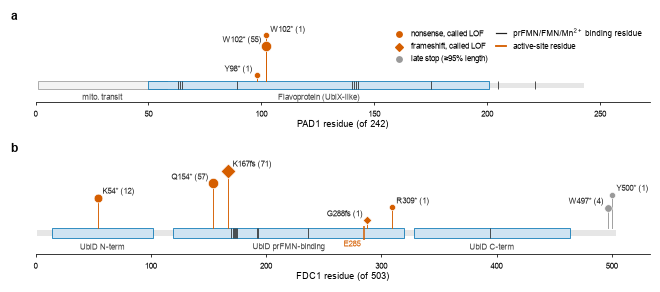

In [80]:
# Figure 2 — where the loss-of-function alleles sit in PAD1 and FDC1 (lollipop map)
# Step 1: one lollipop per distinct truncating allele. The protein position of a nonsense/frameshift is the
# codon that carries it; height = number of strains (log scale, because 1 and 71 must both be readable).
trunc = vc[vc.effect.isin(["nonsense", "frameshift"])].copy()
trunc["aa"] = (trunc.cds_pos - 1) // 3 + 1
lol = trunc.groupby(["gene", "hgvs_c", "protein_change", "aa", "effect"]).strain.nunique().reset_index(name="n")
LATE = {"p.W497*", "p.Y500*"}
DOMAINS = {"FDC1": [(14, 102, "UbiD N-term"), (119, 320, "UbiD prFMN-binding"), (328, 464, "UbiD C-term")],
           "PAD1": [(1, 58, "mito. transit"), (50, 201, "Flavoprotein (UbiX-like)")]}

def sites(acc):
    """Binding-site and active-site residue numbers from the UniProt feature list."""
    f = uni[acc].get("features", [])
    b = sorted({p for x in f if x["type"] == "Binding site" for p in range(x["start"], x["end"] + 1)})
    a = sorted({p for x in f if x["type"] == "Active site" for p in range(x["start"], x["end"] + 1)})
    return b, a

fig, axes = plt.subplots(2, 1, figsize=(W2, 70 * MM), gridspec_kw={"height_ratios": [1, 1.25], "hspace": 0.55})
for ax, gene, acc, letter in [(axes[0], "PAD1", "P33751", "a"), (axes[1], "FDC1", "Q03034", "b")]:
    L = uni[acc]["length"]
    # protein backbone + Pfam/transit boxes
    ax.add_patch(Rectangle((1, -0.18), L, 0.36, fc=C["light"], ec="none"))
    for i, (s, e, name) in enumerate(DOMAINS[gene]):
        fc = "#f3f3f3" if "transit" in name else "#cfe3f2"
        ax.add_patch(Rectangle((s, -0.3), e - s, 0.6, fc=fc, ec=C["pos"] if "transit" not in name else C["grey"], lw=0.5))
        ax.text((s + e) / 2, -0.62, name, ha="center", va="top", fontsize=5, color="#444444")
    b, a = sites(acc)
    ax.vlines(b, -0.3, 0.3, color=C["ink"], lw=0.5)
    ax.vlines(a, -0.42, 0.42, color=C["neg"], lw=1.0)
    for p in a:
        ax.text(p - 3, -0.45, f"E{p}" if gene == "FDC1" else str(p), ha="right", va="top", fontsize=5, color=C["neg"])
    # lollipops
    d = lol[lol.gene == gene].sort_values("aa").reset_index(drop=True)
    CLOSE = 25                       # residues; closer lollipops get stacked heights and left/right labels
    prev_h = -9
    for k, r in d.iterrows():
        h = 0.8 + np.log10(r.n) * 1.3
        if k > 0 and r.aa - d.aa[k - 1] < CLOSE:
            h = max(h, prev_h + 0.8)          # raise the stick above its neighbour
        prev_h = h
        left = k + 1 < len(d) and d.aa[k + 1] - r.aa < CLOSE      # label the earlier one on its left side
        col = C["grey"] if r.protein_change in LATE else C["neg"]
        mk = "D" if r.effect == "frameshift" else "o"
        ax.plot([r.aa, r.aa], [0.3, h], color=col, lw=0.6, zorder=1)
        ax.scatter([r.aa], [h], s=10 + 6 * np.log2(r.n + 1), color=col, marker=mk, edgecolor="white", lw=0.4, zorder=3)
        ax.text(r.aa + (-1 if left else 1) * L * 0.008, h + 0.12, f"{r.protein_change[2:]} ({r.n})", fontsize=5,
                ha="right" if left else "left", va="bottom", color=C["ink"])
    ax.set_xlim(0, L + 30); ax.set_ylim(-1.3, 5.0)
    ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_xlabel(f"{gene} residue (of {L})", labelpad=1)
    panel(ax, letter, x=-0.04, y=0.98)
# legend drawn once, by hand, so marker shapes (nonsense vs frameshift) are explained without colour alone
lx = axes[1].get_xlim()[1]
axes[0].scatter([], [], color=C["neg"], marker="o", s=12, label="nonsense, called LOF")
axes[0].scatter([], [], color=C["neg"], marker="D", s=12, label="frameshift, called LOF")
axes[0].scatter([], [], color=C["grey"], marker="o", s=12, label="late stop (≥95% length)")
axes[0].plot([], [], color=C["ink"], lw=0.8, label="prFMN/FMN/Mn$^{2+}$ binding residue")
axes[0].plot([], [], color=C["neg"], lw=1.2, label="active-site residue")
axes[0].legend(loc="upper right", frameon=False, ncol=2, handlelength=1.2, columnspacing=1.0)
save(fig, "Fig2_lof_lollipop")
plt.show()

saved figures/main/Fig3_enrichment_clades_phenotype.pdf/.png  (183 mm wide)


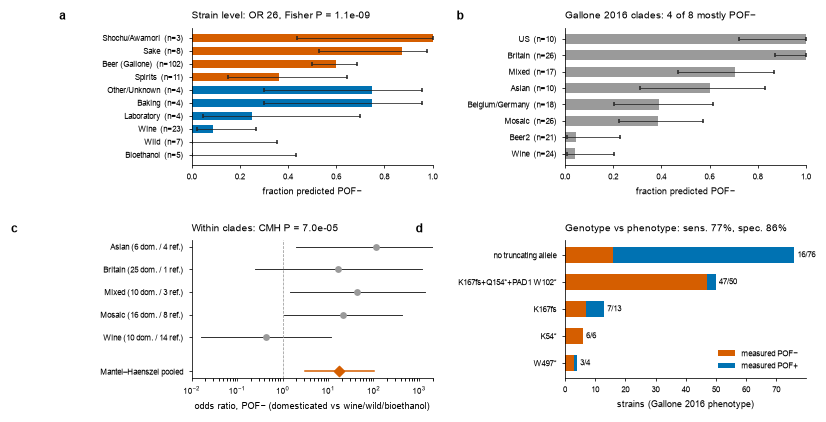

In [81]:
# Figure 3 — POF− genotypes are enriched in domesticated lineages, inside clades too, and match the measured phenotype
fig = plt.figure(figsize=(W2, 105 * MM))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1], height_ratios=[1, 1], wspace=0.55, hspace=0.55)

# a: POF- fraction by ecological group, Wilson 95% CI, n on the right
g = pd.DataFrame(R["core_pofneg_by_group"]).T
g = g[g.n >= 3].copy()          # groups with < 3 strains (ale, lager) are listed in the legend text instead
g["frac"] = g.pof_neg / g.n
lo_hi = [proportion_confint(r.pof_neg, r.n, method="wilson") for r in g.itertuples()]
g["lo"], g["hi"] = [x[0] for x in lo_hi], [x[1] for x in lo_hi]
DOM = {"Beer (Gallone)", "Sake", "Shochu/Awamori", "Spirits"}   # same groups as the Fisher test (baking is not one)
g["dom"] = g.index.isin(DOM)
g = g.sort_values(["dom", "frac"], ascending=[True, True])
ax = fig.add_subplot(gs[0, 0])
y = np.arange(len(g))
ax.barh(y, g.frac, color=[C["neg"] if d else C["pos"] for d in g.dom], height=0.62)
ax.errorbar(g.frac, y, xerr=np.clip([g.frac - g.lo, g.hi - g.frac], 0, None), fmt="none", ecolor=C["ink"], elinewidth=0.5, capsize=1.2)
ax.set_yticks(y, [f"{i}  (n={int(n)})" for i, n in zip(g.index, g.n)])
ax.set_xlim(0, 1.0); ax.set_xlabel("fraction predicted POF−")
fd = R["core_fisher_domestic"]
ax.set_title(f"Strain level: OR {fd['odds_ratio']:.0f}, Fisher P = {fd['fisher_p']:.1e}", loc="left")
panel(ax, "a", x=-0.55)

# b: by Gallone clade
cv = pd.read_csv(f"{RES}/pof_by_gallone_clade.csv").sort_values("frac_POFneg")
ax = fig.add_subplot(gs[0, 1])
y = np.arange(len(cv))
lo_hi = [proportion_confint(r.n_POFneg, r.n, method="wilson") for r in cv.itertuples()]
ax.barh(y, cv.frac_POFneg, color=C["grey"], height=0.62)   # one colour: clades mix niches, so orange/blue would mean nothing here
ax.errorbar(cv.frac_POFneg, y, xerr=np.clip([cv.frac_POFneg - [a for a, _ in lo_hi], [b for _, b in lo_hi] - cv.frac_POFneg], 0, None),
            fmt="none", ecolor=C["ink"], elinewidth=0.5, capsize=1.2)
ax.set_yticks(y, [f"{c}  (n={n})" for c, n in zip(cv.clade, cv.n)])
ax.set_xlim(0, 1.0); ax.set_xlabel("fraction predicted POF−")
ax.set_title(f"Gallone 2016 clades: {R['a1_n_pofneg_clades']} of {R['a1_n_clades']} mostly POF−", loc="left")
panel(ax, "b", x=-0.45)

# c: forest plot, per-clade OR (Haldane +0.5 for display) and the pooled Mantel-Haenszel OR
st = pd.read_csv(f"{RES}/cmh_strata_by_clade.csv")
st = st[st.informative]
ax = fig.add_subplot(gs[1, 0])
rows = []
for r in st.itertuples():
    a_, b_, c_, d_ = [v + 0.5 for v in (r.dom_POFneg, r.dom_POFpos, r.ref_POFneg, r.ref_POFpos)]
    lor, se = np.log(a_ * d_ / (b_ * c_)), np.sqrt(1 / a_ + 1 / b_ + 1 / c_ + 1 / d_)
    rows.append((f"{r.clade} ({r.dom_POFneg + r.dom_POFpos} dom. / {r.ref_POFneg + r.ref_POFpos} ref.)", lor, se))
y = np.arange(len(rows))[::-1] + 2
for (lab, lor, se), yy in zip(rows, y):
    ax.plot([np.exp(lor - 1.96 * se), np.exp(lor + 1.96 * se)], [yy, yy], color=C["ink"], lw=0.6)
    ax.scatter([np.exp(lor)], [yy], s=12, color=C["grey"], zorder=3)
mh, (cl, ch) = R["a1_cmh_or"], R["a1_cmh_or_ci"]
ax.plot([cl, ch], [0.5, 0.5], color=C["neg"], lw=1.0)
ax.scatter([mh], [0.5], marker="D", s=22, color=C["neg"], zorder=3)
ax.axvline(1, color=C["grey"], lw=0.5, ls="--")
ax.set_xscale("log"); ax.set_xlim(0.01, 2000)
ax.set_yticks(list(y) + [0.5], [r[0] for r in rows] + ["Mantel–Haenszel pooled"])
ax.set_xlabel("odds ratio, POF− (domesticated vs wine/wild/bioethanol)")
ax.set_title(f"Within clades: CMH P = {R['a1_cmh_p']:.1e}", loc="left")
panel(ax, "c", x=-0.75)

# d: measured phenotype (Gallone Table S5) for each allele signature
ap = pd.read_csv(f"{RES}/pof_phenotype_by_allele_signature.csv").set_index("alleles")
ap = ap[ap.n >= 3].sort_values("n")
ax = fig.add_subplot(gs[1, 1])
y = np.arange(len(ap))
ax.barh(y, ap["POF-"], color=C["neg"], height=0.62, label="measured POF−")
ax.barh(y, ap["POF+"], left=ap["POF-"], color=C["pos"], height=0.62, label="measured POF+")
for yy, (a_, b_) in zip(y, zip(ap["POF-"], ap["POF+"])):
    ax.text(a_ + b_ + 1, yy, f"{a_}/{a_ + b_}", va="center", fontsize=5)
ax.set_yticks(y, [s.replace("FDC1 ", "").replace("PAD1 ", "PAD1 ").replace(" + ", "+") for s in ap.index])
ax.set_xlabel("strains (Gallone 2016 phenotype)")
ax.legend(frameon=False, loc="lower right")
sens = R["a3_sensitivity"][0]; spec = R["a3_specificity"][0]
ax.set_title(f"Genotype vs phenotype: sens. {sens:.0%}, spec. {spec:.0%}", loc="left")
panel(ax, "d", x=-0.62)
save(fig, "Fig3_enrichment_clades_phenotype")
plt.show()

gain markers drawn: 13
saved figures/main/Fig4_haplotype_tree_origins.pdf/.png  (183 mm wide)


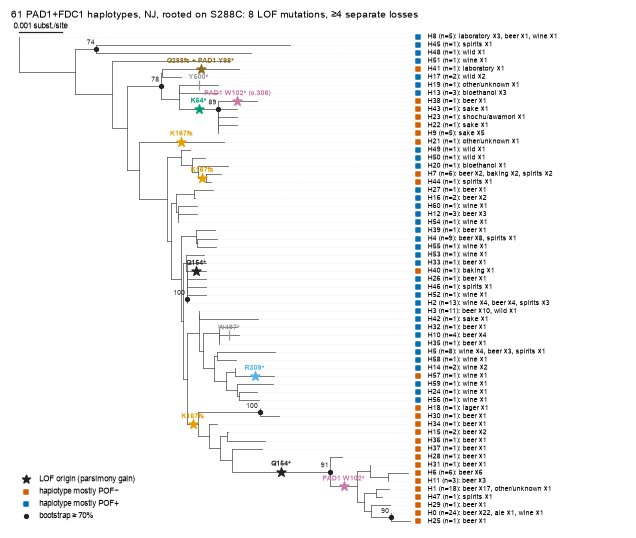

In [82]:
# Figure 4 — the haplotype tree with the independent loss-of-function origins marked (headline figure)
hap = pd.read_csv(f"{RES}/PAD1_FDC1_haplotypes.csv")
tree = Phylo.read(f"{RES}/PAD1_FDC1_haplotype_nj_bootstrap.nwk", "newick")
tree.root_with_outgroup(R["a2_tree_root"])
tree.ladderize()
trunc["allele"] = trunc.gene + " " + trunc.protein_change.str.replace("p.", "", regex=False)
trunc.loc[trunc.hgvs_c == "c.306G>A", "allele"] = "PAD1 W102* (c.306)"
s_all = trunc.groupby("strain").allele.apply(set)
hap["alleles"] = hap.strain.map(s_all).apply(lambda x: x if isinstance(x, set) else set())
per_hap = hap.groupby("haplotype").alleles.agg(lambda s: set().union(*s))

def sankoff_gains(tree, present):
    """Branches (child clades) where the 0/1 trait switches 0->1 in one most-parsimonious reconstruction."""
    cost = {}
    for cl in tree.find_clades(order="postorder"):
        if cl.is_terminal():
            cost[cl] = np.array([np.inf, 0.0]) if cl.name in present else np.array([0.0, np.inf])
        else:
            cost[cl] = sum(np.array([min(cost[ch][0], cost[ch][1] + 1), min(cost[ch][1], cost[ch][0] + 1)]) for ch in cl.clades)
    gains, stack = [], [(tree.root, 0)]
    while stack:
        cl, s = stack.pop()
        for ch in cl.clades:
            t = int(np.argmin([cost[ch][0] + (s != 0), cost[ch][1] + (s != 1)]))
            if s == 0 and t == 1:
                gains.append(ch)
            stack.append((ch, t))
    return gains

# layout: x = cumulative branch length, y = tip order
tips = tree.get_terminals()
ypos = {t: i for i, t in enumerate(tips)}
for cl in tree.find_clades(order="postorder"):
    if not cl.is_terminal():
        ypos[cl] = np.mean([ypos[c] for c in cl.clades])
xpos = {tree.root: 0.0}
for cl in tree.find_clades(order="preorder"):
    for ch in cl.clades:
        xpos[ch] = xpos[cl] + max(ch.branch_length or 0, 0)
xmax = max(xpos.values())

fig, ax = plt.subplots(figsize=(W2, 150 * MM))
for cl in tree.find_clades():
    for ch in cl.clades:
        ax.plot([xpos[cl], xpos[cl]], [ypos[cl], ypos[ch]], color="#555555", lw=0.5)
        ax.plot([xpos[cl], xpos[ch]], [ypos[ch], ypos[ch]], color="#555555", lw=0.5)
    if not cl.is_terminal() and cl.confidence is not None and cl.confidence >= 70 and cl is not tree.root:
        ax.scatter([xpos[cl]], [ypos[cl]], s=6, color=C["ink"], zorder=4)
        ax.text(xpos[cl] - xmax * 0.004, ypos[cl] - 0.35, f"{cl.confidence:.0f}", fontsize=4.5, ha="right", va="bottom", color="#333333")

# tip labels: haplotype, strain count, groups; coloured square = POF status
for t in tips:
    sub = hap[hap.haplotype == int(t.name[1:])]
    # lower-case niche names so "beer 1" (one beer strain) is not misread as the Beer 1 clade
    grp = ", ".join(f"{k.replace(' (Gallone)', '').lower()} ×{v}" for k, v in sub.group.value_counts().head(3).items())
    neg = (sub.POF == "POF-").mean() > 0.5
    ax.plot([xpos[t], xmax * 1.01], [ypos[t]] * 2, color=C["light"], lw=0.4, ls=":", zorder=0)   # leader line tip -> label
    ax.scatter([xmax * 1.02], [ypos[t]], marker="s", s=9, color=C["neg"] if neg else C["pos"])
    ax.text(xmax * 1.045, ypos[t], f"{t.name} (n={len(sub)}): {grp}", fontsize=4.6, va="center")

# origins: one marker per gain, colour per allele (fixed order), label beside the marker
# allele colours avoid the POF-/POF+ square colours (neg/pos) so a star is never read as a POF status
ALLELE_COL = {"FDC1 Q154*": C["ink"], "FDC1 K167fs": C["orange"], "PAD1 W102*": C["pink"], "FDC1 K54*": C["green"],
              "FDC1 R309*": C["sky"], "FDC1 G288fs": "#8C6D1F", "PAD1 Y98*": "#8C6D1F", "PAD1 W102* (c.306)": C["pink"],
              "FDC1 W497*": C["grey"], "FDC1 Y500*": C["grey"]}
# collect every gain first, so alleles gained on the same branch share one marker and one label
gains = {}
for al, col in ALLELE_COL.items():
    carriers = {f"H{k}" for k, s_ in per_hap.items() if al in s_}
    for ch in (sankoff_gains(tree, carriers) if carriers else []):
        gains.setdefault(id(ch), [ch, []])[1].append(al)
n_gain_marks = 0
for ch, als in gains.values():
    par = next(p_ for p_ in tree.find_clades() if ch in p_.clades)
    xm = (xpos[par] + xpos[ch]) / 2 if xpos[ch] > xpos[par] else xpos[ch]
    col = ALLELE_COL[als[0]]
    late = all("W497" in x or "Y500" in x for x in als)
    ax.scatter([xm], [ypos[ch]], marker="|" if late else "*", s=40, color=col, zorder=5, linewidths=0.8)
    lab = " + ".join(x.replace("FDC1 ", "") for x in als)
    ax.text(xm, ypos[ch] - 0.55, lab, fontsize=4.8, color=col, ha="center", va="bottom", weight="bold")
    n_gain_marks += len(als)
ax.set_ylim(len(tips) - 0.3, -1.2); ax.set_xlim(-xmax * 0.02, xmax * 1.55)
ax.axis("off")
ax.plot([0, 0.001], [-0.6] * 2, color=C["ink"], lw=0.8)
ax.text(0.0005, -0.8, "0.001 subst./site", ha="center", va="bottom", fontsize=5)
ax.scatter([], [], marker="*", s=30, color=C["ink"], label="LOF origin (parsimony gain)")
ax.scatter([], [], marker="s", s=9, color=C["neg"], label="haplotype mostly POF−")
ax.scatter([], [], marker="s", s=9, color=C["pos"], label="haplotype mostly POF+")
ax.scatter([], [], s=6, color=C["ink"], label="bootstrap ≥ 70%")
ax.legend(loc="lower left", frameon=False, fontsize=5)
ax.set_title(f"{R['a2_n_haplotypes']} PAD1+FDC1 haplotypes, NJ, rooted on S288C: {R['a2_n_distinct_lof']} LOF mutations, ≥{R['a2_n_loss_events']} separate losses",
             loc="left", fontsize=6.5)
print(f"gain markers drawn: {n_gain_marks}")
save(fig, "Fig4_haplotype_tree_origins")
plt.show()

saved figures/main/Fig5_fdc1_structure_truncations.pdf/.png  (183 mm wide)


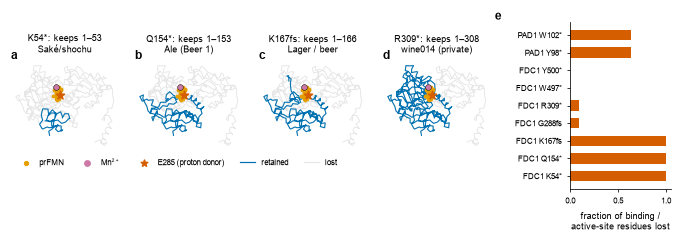

In [83]:
# Figure 5 — every common truncation removes the whole cofactor/metal/active site of Fdc1
s = PDBParser(QUIET=True).get_structure("fdc1", "data/structure/4ZAC_A_CA_het.pdb")
ca = [(r.id[1], r["CA"].coord) for r in s[0]["A"] if "CA" in r and r.id[0] == " "]
resn = np.array([n for n, _ in ca]); X = np.array([c for _, c in ca])
het = [a for a in s[0].get_atoms() if a.get_parent().id[0].startswith("H_")]
fmn = np.array([a.coord for a in het if a.get_parent().get_resname() == "4LU"])
mn = np.array([a.coord for a in het if a.get_parent().get_resname() == "MN"])
mu = X.mean(axis=0); _, _, Vt = np.linalg.svd(X - mu, full_matrices=False)
P, Pf, Pm = (X - mu) @ Vt[:2].T, (fmn - mu) @ Vt[:2].T, (mn - mu) @ Vt[:2].T
e285 = P[resn == 285][0]
stc = pd.DataFrame(R["core_structure"])
show = [("FDC1 K54*", 53, "Saké/shochu"), ("FDC1 Q154*", 153, "Ale (Beer 1)"), ("FDC1 K167fs", 166, "Lager / beer"),
        ("FDC1 R309*", 308, "wine014 (private)")]
fig, axes = plt.subplots(1, 5, figsize=(W2, 50 * MM), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.1], "wspace": 0.15})
for ax, (lab, keep, who), letter in zip(axes[:4], show, "abcd"):
    kept = resn <= keep
    ax.plot(P[:, 0], P[:, 1], color=C["light"], lw=0.6, zorder=1)
    ax.plot(P[kept, 0], P[kept, 1], color=C["pos"], lw=0.7, zorder=2)
    ax.scatter(Pf[:, 0], Pf[:, 1], s=2, color=C["orange"], zorder=3)
    ax.scatter(Pm[:, 0], Pm[:, 1], s=14, color=C["pink"], edgecolor="k", lw=0.3, zorder=4)
    ax.scatter([e285[0]], [e285[1]], marker="*", s=30, color=C["neg"], zorder=5)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"{lab.split()[1]}: keeps 1–{keep}\n{who}", fontsize=5.8)
    panel(ax, letter, x=0.0, y=1.0)
# e: binding residues lost per allele (both proteins), straight from the structure table
stc = stc[~stc.allele.str.contains(";")]       # the Q154*+K167fs haplotype is the same truncation as Q154*
stc["lab"] = stc.gene + " " + stc.allele.str.extract(r"(p\.\S+?)(?:\s|$)")[0].str.replace("p.", "", regex=False)
stc = stc.drop_duplicates("lab").sort_values(["gene", "native_residues"])
ax = axes[4]
y = np.arange(len(stc))
ax.barh(y, stc.n_binding_residues_lost / stc.n_binding_residues_total, color=[C["neg"] if c else C["grey"] for c in stc.LOF_called], height=0.6)
ax.set_yticks(y, stc.lab); ax.set_xlim(0, 1.05)
ax.set_xlabel("fraction of binding /\nactive-site residues lost")
panel(ax, "e", x=-0.75, y=1.0)
ax.set_position([ax.get_position().x0 + 0.08, ax.get_position().y0, ax.get_position().width * 0.85, ax.get_position().height])
axes[0].scatter([], [], s=6, color=C["orange"], label="prFMN"); axes[0].scatter([], [], s=12, color=C["pink"], label="Mn$^{2+}$")
axes[0].scatter([], [], marker="*", s=20, color=C["neg"], label="E285 (proton donor)")
axes[0].plot([], [], color=C["pos"], label="retained"); axes[0].plot([], [], color=C["light"], label="lost")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.02), ncol=5, frameon=False, fontsize=5)
save(fig, "Fig5_fdc1_structure_truncations")
plt.show()

saved figures/main/Fig6_mal_cnv_lager.pdf/.png  (183 mm wide)


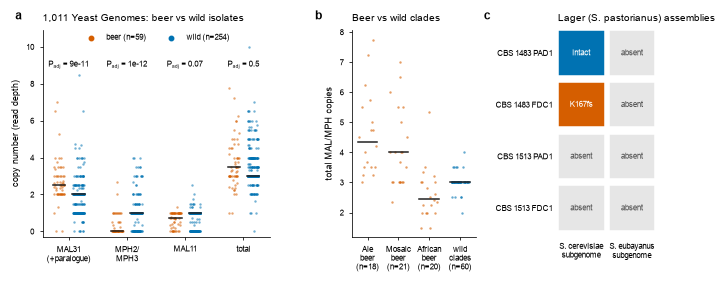

In [84]:
# Figure 6 — maltose-transporter copy number trades off between genes; lager assemblies lack a S. eubayanus pathway copy
# Step 1: per-strain read-depth copy number from step 09 (1,011 genomes). I show beer vs wild strains per gene,
# with a light jitter so stacked integer values stay visible, and the median as a black bar.
cn = pd.read_csv(f"{RES}/mal_cnv_1011_per_strain.csv")
GENES6 = [("MAL31", "MAL31\n(+paralogue)"), ("MPH2/3", "MPH2/\nMPH3"), ("MAL11", "MAL11"), ("Total", "total")]
rng = np.random.default_rng(0)       # fixed seed so the jitter is identical on every run
fig = plt.figure(figsize=(W2, 62 * MM))
gs = fig.add_gridspec(1, 3, width_ratios=[2.3, 1.25, 1.0], wspace=0.55)
ax = fig.add_subplot(gs[0, 0])
for i, (col, lab) in enumerate(GENES6):
    for j, (grp, colr) in enumerate([("Beer", C["neg"]), ("Wild", C["pos"])]):
        v = cn.loc[cn.group == grp, col].dropna().values
        x = i * 3 + j
        ax.scatter(x + rng.uniform(-0.28, 0.28, len(v)), v, s=2.5, color=colr, alpha=0.55, lw=0)
        ax.plot([x - 0.32, x + 0.32], [np.median(v)] * 2, color=C["ink"], lw=1.0)
    key = col.lower().replace("/", "_")
    pbh = R.get(f"a4_beer_vs_wild_{key}_p_bh", R.get(f"a4_beer_vs_wild_{key}_p"))
    ax.text(i * 3 + 0.5, 8.9, f"P$_{{adj}}$ = {pbh:.1g}", ha="center", fontsize=5)   # one row, above the data
ax.set_xticks([i * 3 + 0.5 for i in range(len(GENES6))], [g[1] for g in GENES6])
ax.set_ylabel("copy number (read depth)")
ax.scatter([], [], color=C["neg"], s=8, label=f"beer (n={R['a4_n_beer']})")
ax.scatter([], [], color=C["pos"], s=8, label=f"wild (n={R['a4_n_wild']})")
ax.set_ylim(-0.3, 10.9)
ax.legend(frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))
ax.set_title("1,011 Yeast Genomes: beer vs wild isolates", loc="left")
panel(ax, "a", x=-0.12)

# Step 2: total copy number for the three beer clades vs the wild clades (clade definition from step 09).
ax = fig.add_subplot(gs[0, 1])
clades = [("11. Ale beer", "Ale beer"), ("7. Mosaic beer", "Mosaic beer"), ("6. African beer", "African beer")]
sets = [(cn.loc[cn.clade == c, "Total"].dropna().values, lab) for c, lab in clades]
sets.append((cn.loc[cn.clade.isin(R["a4_wild_clades"]), "Total"].dropna().values, "wild clades"))
for j, (v, lab) in enumerate(sets):
    colr = C["pos"] if lab == "wild clades" else C["neg"]
    ax.scatter(j + rng.uniform(-0.28, 0.28, len(v)), v, s=2.5, color=colr, alpha=0.6, lw=0)
    ax.plot([j - 0.32, j + 0.32], [np.median(v)] * 2, color=C["ink"], lw=1.0)
ax.set_xticks(range(len(sets)), [lab.replace(" ", "\n") + f"\n(n={len(v)})" for v, lab in sets], fontsize=5)
ax.set_ylabel("total MAL/MPH copies")
ax.set_title("Beer vs wild clades", loc="left")
panel(ax, "b", x=-0.3)

# Step 3: lager subgenome status grid from step 10 (one cell per strain x gene x parental subgenome).
lg = pd.read_csv(f"{RES}/lager_subgenome_pad1_fdc1.csv")
status_col = lg.columns[-1]
ax = fig.add_subplot(gs[0, 2])
STAT = {"intact": C["pos"], "LOF": C["neg"], "absent": C["light"]}
rows6 = [(s_, g_) for s_ in lg.strain.unique() for g_ in ["PAD1", "FDC1"]]
for yi, (s_, g_) in enumerate(rows6):
    for xi, sub in enumerate(["Sc", "Se"]):
        st_ = lg[(lg.strain == s_) & (lg.gene == g_) & (lg.subgenome == sub)][status_col].iloc[0]
        ax.add_patch(Rectangle((xi, yi), 0.92, 0.88, fc=STAT[st_], ec="white"))
        ax.text(xi + 0.46, yi + 0.44, st_ if st_ != "LOF" else "K167fs", ha="center", va="center", fontsize=5,
                color="white" if st_ != "absent" else "#555555")
ax.set_xlim(0, 1.95); ax.set_ylim(len(rows6), 0)
ax.set_xticks([0.46, 1.46], ["S. cerevisiae\nsubgenome", "S. eubayanus\nsubgenome"], fontsize=5)
ax.set_yticks([i + 0.44 for i in range(len(rows6))], [f"{s_} {g_}" for s_, g_ in rows6], fontsize=5)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.tick_params(length=0)
ax.set_title("Lager (S. pastorianus) assemblies", loc="left")
panel(ax, "c", x=-0.75)
save(fig, "Fig6_mal_cnv_lager")
plt.show()